In [21]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import sys
import os

# ==========================================
# 1. 配置与加载
# ==========================================
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"

# 变量映射 (基于你确认过的真实列名)
col_map = {
    'albedo': 'Albedo',             # 目标
    'strd': 'Strd',                 # 长波辐射
    'ssrd': 'Ssrd',                 # 短波辐射
    't2m': 'T2m',                   # 2m气温
    'u10': 'U10',                   # 纬向风 (西风分量)
    'v10': 'V10',                   # 经向风 (南风分量)
    'altitude_last_valid': 'Alt',   # 海拔
    'longitude': 'Lon'              # 经度
}

print(f"正在读取文件: {file_path} ...")
if not os.path.exists(file_path):
    print("❌ 文件不存在")
    sys.exit(1)

try:
    df = pd.read_csv(file_path, usecols=list(col_map.keys()))
    df.rename(columns=col_map, inplace=True)
    df.dropna(inplace=True)
    print(f"数据加载成功。有效样本数: {len(df):,}")
except Exception as e:
    print(f"❌ 读取错误: {e}")
    sys.exit(1)

# 定义要分析的物理变量列表
phys_vars = ['Strd', 'Ssrd', 'T2m', 'U10', 'V10']

# ==========================================
# 第一步：海拔分组分析 (Inland vs Margin)
# ==========================================
print("\n" + "="*80)
print("📊 STEP 1: 海拔分组分析 (Elevation Regimes)")
print("   对比内陆 (>1500m) 与 边缘 (<1500m) 的整体机制")
print("="*80)

regions = {
    'Inland (>1500m)': df[df['Alt'] > 1500],
    'Margin (<1500m)': df[df['Alt'] <= 1500]
}

for name, subset in regions.items():
    print(f"\n📍 [{name}] (N={len(subset):,})")
    print("-" * 50)
    print(f"{'Variable':<10} | {'Correlation (r)':<15} | {'P-value':<10} | {'Interpretation Hint'}")
    print("-" * 50)
    
    for var in phys_vars:
        r, p = pearsonr(subset[var], subset['Albedo'])
        
        # 简单的自动解读标记
        hint = ""
        if "Margin" in name and var == "Strd" and r < -0.3: hint = "🔥 Melt driven (Cloud/Warmth)"
        if "Margin" in name and var == "Ssrd" and r < -0.3: hint = "☀️ Melt driven (Sun)"
        if "Inland" in name and var == "Strd" and r < 0:    hint = "❄️ Radiative Cooling?"
        
        sig = "***" if p < 0.001 else "**" if p < 0.01 else ""
        print(f"{var:<10} | {r:>8.3f} {sig:<6} | {p:.1e}  | {hint}")

# ==========================================
# 第二步：内陆东西细分 (Inland West vs East)
# ==========================================
print("\n" + "="*80)
print("🧭 STEP 2: 内陆东西部细分 (Inland West vs East)")
print("   仅分析海拔 > 1500m 区域，以 -42°W 为界")
print("="*80)

# 只取内陆
df_inland = df[df['Alt'] > 1500].copy()
# 划分东西
df_inland['Sector'] = df_inland['Lon'].apply(lambda x: 'West' if x < -42 else 'East')

sectors = ['West', 'East']

for sector in sectors:
    subset = df_inland[df_inland['Sector'] == sector]
    print(f"\n📍 [{sector.upper()} INLAND] (N={len(subset):,})")
    print("-" * 50)
    print(f"{'Variable':<10} | {'Correlation (r)':<15} | {'P-value':<10}")
    print("-" * 50)
    
    for var in phys_vars:
        r, p = pearsonr(subset[var], subset['Albedo'])
        sig = "***" if p < 0.001 else "**" if p < 0.01 else ""
        print(f"{var:<10} | {r:>8.3f} {sig:<6} | {p:.1e}")

print("\n" + "="*80)
print("✅ 分析完成。请复制上方结果。")

正在读取文件: C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv ...
数据加载成功。有效样本数: 4,455

📊 STEP 1: 海拔分组分析 (Elevation Regimes)
   对比内陆 (>1500m) 与 边缘 (<1500m) 的整体机制

📍 [Inland (>1500m)] (N=1,942)
--------------------------------------------------
Variable   | Correlation (r) | P-value    | Interpretation Hint
--------------------------------------------------
Strd       |   -0.077 ***    | 7.4e-04  | ❄️ Radiative Cooling?
Ssrd       |   -0.176 ***    | 5.0e-15  | 
T2m        |   -0.198 ***    | 1.5e-18  | 
U10        |   -0.027        | 2.3e-01  | 
V10        |    0.038        | 9.0e-02  | 

📍 [Margin (<1500m)] (N=2,513)
--------------------------------------------------
Variable   | Correlation (r) | P-value    | Interpretation Hint
--------------------------------------------------
Strd       |   -0.357 ***    | 2.3e-76  | 🔥 Melt driven (Cloud/Warmth)
Ssrd       |   -0.074 ***    | 2.0e-04  | 
T2m        |   -0.595 ***    | 1.5e-240  | 
U10        |   -0.161 ***    | 5.6e-16  | 
V10  

In [ ]:
 正在合并全量数据...
✅ 全量数据就绪: 37,116,900 行

==========================================================================================
🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证
   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)

In [6]:
import pandas as pd
import glob
import os
import sys
from scipy.stats import pearsonr

# ==========================================
# 1. 配置
# ==========================================
folder_path = r"C:\Users\11823\era5land\202209202402"
file_pattern = "*prediction.csv"

# 只需要读取核心变量
use_cols = [
    'albedo', 't2m', 'u10',     # 核心分析变量
    'altitude_last_valid',      # 用于海拔切片
    'longitude', 'latitude'     # 用于区域切片
]

col_rename = {
    'altitude_last_valid': 'Alt',
    'longitude': 'Lon',
    'latitude': 'Lat',
    'albedo': 'Albedo',
    't2m': 'T2m',
    'u10': 'U10'
}

# ==========================================
# 2. 高效读取数据 (一次性读取到内存)
# ==========================================
print(f"🚀 正在加载 450 个文件到内存 (优化模式)...")
all_files = glob.glob(os.path.join(folder_path, file_pattern))

data_buffer = []
for i, f in enumerate(all_files):
    try:
        df_chunk = pd.read_csv(f, usecols=use_cols)
        df_chunk.rename(columns=col_rename, inplace=True)
        df_chunk.dropna(inplace=True)
        data_buffer.append(df_chunk)
        
        if (i+1) % 50 == 0:
            print(f"  已加载 {i+1}/{len(all_files)} 个文件...")
    except Exception as e:
        pass

if not data_buffer:
    print("❌ 没有读取到数据！")
    sys.exit(1)

print("📥 正在合并全量数据...")
df_all = pd.concat(data_buffer, ignore_index=True)
del data_buffer # 释放内存
print(f"✅ 全量数据就绪: {len(df_all):,} 行")

# ==========================================
# 3. 定义实验参数网格
# ==========================================

# A. 海拔切片 (3层)
elevation_bins = [
    (2000, 9000, "High Inland (>2000m)"),  # 核心内陆
    (1000, 2000, "Transition (1-2km)"),    # 过渡带
    (0,    1000, "Low Margin (<1000m)")    # 边缘消融区
]

# B. 经度分界线测试 (3组)
# 我们关注 "East"，所以 Lon > threshold
longitude_splits = [-44, -42, -40] 

# ==========================================
# 4. 执行网格分析
# ==========================================
print("\n" + "="*90)
print("🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证")
print("   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)")
print("="*90)

# 表头
header = f"{'Split(Lon)':<12} | {'Elevation Zone':<20} | {'N (Samples)':<12} | {'U10 vs T2m':<15} | {'U10 vs Albedo':<15} | {'Mechanism?'}"
print(header)
print("-" * 100)

for split_lon in longitude_splits:
    print(f"--- Testing Divider: {split_lon}°W ---")
    
    # 筛选出该分界线以东的所有数据
    df_east_all = df_all[df_all['Lon'] >= split_lon]
    
    for (min_h, max_h, label) in elevation_bins:
        # 筛选海拔
        subset = df_east_all[(df_east_all['Alt'] >= min_h) & (df_east_all['Alt'] < max_h)]
        n = len(subset)
        
        if n < 1000:
            print(f"{split_lon:<12} | {label:<20} | {n:<12} | (样本不足)")
            continue
            
        # 1. 计算 U10 vs T2m (验证焚风热效应)
        r_heat, p_heat = pearsonr(subset['U10'], subset['T2m'])
        
        # 2. 计算 U10 vs Albedo (验证反照率响应)
        r_alb, p_alb = pearsonr(subset['U10'], subset['Albedo'])
        
        # 3. 自动诊断机制
        mech = ""
        # 焚风特征: 风越大越热(r_heat>0)，且越暗(r_alb<0)
        if r_heat > 0.1 and r_alb < -0.1:
            mech = "🔥 Foehn Melt (Darkening)"
        # 堆积特征: 风越大越冷/不变，且越亮(r_alb>0)
        elif r_alb > 0.1:
            mech = "❄️ Accumulation (Brightening)"
        # 混合/其他
        elif r_heat > 0.1 and r_alb > -0.1:
            mech = "⚠️ Warming but no Melt"
            
        # 格式化输出
        # 使用颜色标记关键结果 (如果终端支持)
        r_heat_str = f"{r_heat:6.3f}"
        r_alb_str = f"{r_alb:6.3f}"
        
        print(f"{'> '+str(split_lon):<12} | {label:<20} | {n:<12,} | {r_heat_str:<15} | {r_alb_str:<15} | {mech}")
    print("-" * 100)

# ==========================================
# 5. 补充：极端焚风区验证 (Optional)
# ==========================================
# 很多文献提到东南沿海 (South East) 焚风最强，我们加一个纬度限制试试
print("\n[Deep Dive] 东南沿海特异性检查 (South-East Coast)")
print("条件: Lon > -40 (Strict East) AND Lat < 70 (South) AND Alt < 1000")

subset_se = df_all[(df_all['Lon'] > -40) & (df_all['Lat'] < 70) & (df_all['Alt'] < 1000)]
if len(subset_se) > 1000:
    r_u10_alb, _ = pearsonr(subset_se['U10'], subset_se['Albedo'])
    r_u10_t2m, _ = pearsonr(subset_se['U10'], subset_se['T2m'])
    print(f"Samples: {len(subset_se):,}")
    print(f"U10 vs T2m   (Heat): {r_u10_t2m:.3f} (Expect Positive)")
    print(f"U10 vs Albedo(Dark): {r_u10_alb:.3f} (Expect Negative)")
    
    if r_u10_alb < -0.2:
        print("✅ 捕捉到强烈的焚风变暗信号！")
    else:
        print("❓ 信号未达预期强度。")
else:
    print("样本不足。")

print("="*90)

🚀 正在加载 450 个文件到内存 (优化模式)...
  已加载 50/450 个文件...
  已加载 100/450 个文件...
  已加载 150/450 个文件...
  已加载 200/450 个文件...
  已加载 250/450 个文件...
  已加载 300/450 个文件...
  已加载 350/450 个文件...
  已加载 400/450 个文件...
  已加载 450/450 个文件...
📥 正在合并全量数据...
✅ 全量数据就绪: 37,116,900 行

🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证
   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)
Split(Lon)   | Elevation Zone       | N (Samples)  | U10 vs T2m      | U10 vs Albedo   | Mechanism?
----------------------------------------------------------------------------------------------------
--- Testing Divider: -44°W ---
> -44        | High Inland (>2000m) | 8,393,850    | -0.180          |  0.158          | ❄️ Accumulation (Brightening)
> -44        | Transition (1-2km)   | 4,157,100    | -0.422          |  0.452          | ❄️ Accumulation (Brightening)
> -44        | Low Margin (<1000m)  | 5,488,200    | -0.309          |  0.316          | ❄️ Accumulation (Brightening)
-----------------------------------------------------------------------------

In [6]:
import xarray as xr

# 请确保路径正确
path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc"

try:
    ds = xr.open_dataset(path)
    print("===== 1. 维度信息 (Dimensions) =====")
    print(ds.dims)
    
    print("\n===== 2. 坐标信息 (Coordinates) =====")
    print(ds.coords)
    
    print("\n===== 3. 变量信息 (Variables) =====")
    print(ds.data_vars)
    
    print("\n===== 4. 坐标属性 (Attributes) =====")
    # 检查经度范围和纬度方向
    print(f"Longitude range: {ds.longitude.min().values} to {ds.longitude.max().values}")
    print(f"Latitude range: {ds.latitude.min().values} to {ds.latitude.max().values}")
    print(f"Latitude first 3 values: {ds.latitude.values[:3]}") # 检查升降序
    
    # 检查时间步长
    print(f"\nTime range: {ds.valid_time.min().values} to {ds.valid_time.max().values}")

except Exception as e:
    print(f"读取文件出错: {e}")

===== 1. 维度信息 (Dimensions) =====
FrozenMappingWarningOnValuesAccess({'valid_time': 910, 'pressure_level': 3, 'latitude': 141, 'longitude': 721})

===== 2. 坐标信息 (Coordinates) =====
Coordinates:
    number          int64 8B ...
  * valid_time      (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2025-10-01
  * pressure_level  (pressure_level) float64 24B 850.0 500.0 200.0
  * latitude        (latitude) float64 1kB 90.0 89.75 89.5 ... 55.5 55.25 55.0
  * longitude       (longitude) float64 6kB -130.0 -129.8 -129.5 ... 49.75 50.0
    expver          (valid_time) <U4 15kB ...

===== 3. 变量信息 (Variables) =====
Data variables:
    z        (valid_time, pressure_level, latitude, longitude) float32 1GB ...
    u        (valid_time, pressure_level, latitude, longitude) float32 1GB ...
    v        (valid_time, pressure_level, latitude, longitude) float32 1GB ...
    w        (valid_time, pressure_level, latitude, longitude) float32 1GB ...

===== 4. 坐标属性 (Attributes) =====
Longitude range: -130.0 t

C:\Users\11823\AppData\Local\Temp\ipykernel_44956\3167050699.py:32: UserWarning: The specified chunks separate the stored chunks along dimension "valid_time" starting at index 100. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, chunks={'valid_time': 100})


正在计算三段 JJA 均值：1950–2024, 1990–2024, 2001–2024 ...


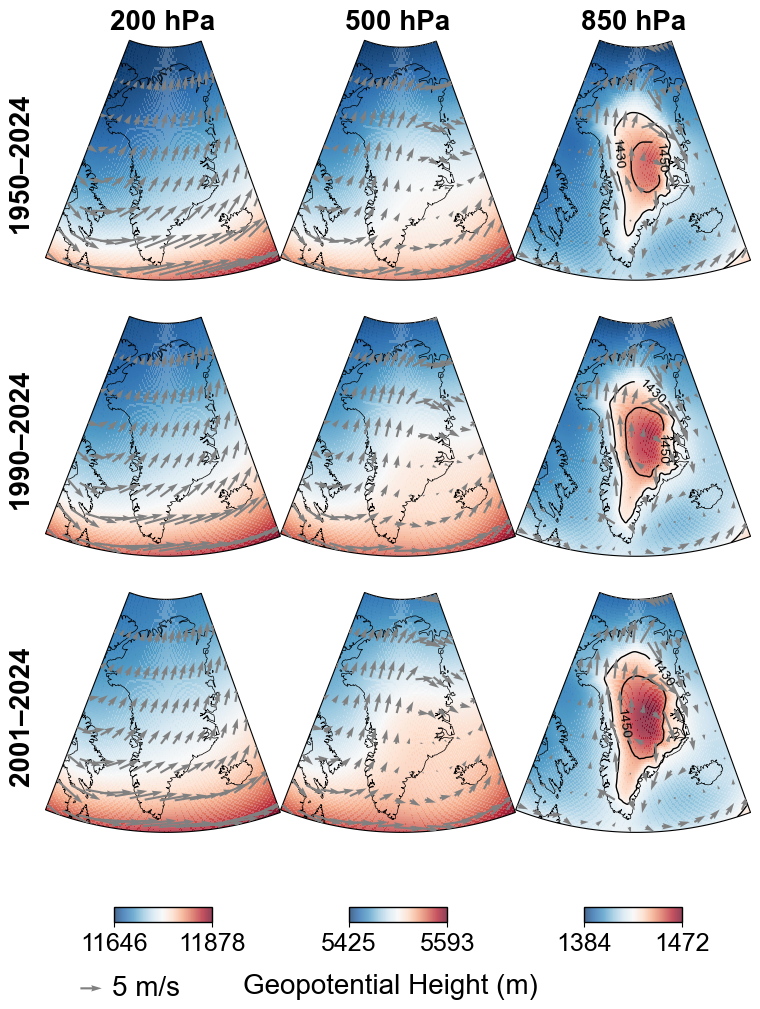

In [29]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import sys
from matplotlib.path import Path

# ===================== 0. 投影与范围（关键：放大extent保证格陵兰完整） =====================
map_proj  = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
data_proj = ccrs.PlateCarree()

# ★关键：别再用 [-58,-18,59.5,83.5]，北部会被切
extent = [-75, -10, 58.0, 85.0]  # [lonW, lonE, latS, latN]

def clip_to_extent(ax, extent, crs, n=260):
    lon0, lon1, lat0, lat1 = extent
    lons = np.linspace(lon0, lon1, n)
    lats = np.linspace(lat0, lat1, n)

    bottom = np.column_stack([lons, np.full_like(lons, lat0)])
    right  = np.column_stack([np.full_like(lats, lon1), lats])
    top    = np.column_stack([lons[::-1], np.full_like(lons, lat1)])
    left   = np.column_stack([np.full_like(lats, lon0), lats[::-1]])

    ring = np.vstack([bottom, right, top, left])
    ax.set_boundary(Path(ring), transform=crs)

# ===================== 1. 数据加载与 JJA 气候态均值 =====================
def load_and_preprocess_means(path, levels, extent):
    try:
        ds = xr.open_dataset(path, chunks={'valid_time': 100})
        if 'lat' in ds.coords:
            ds = ds.rename({'lat': 'latitude', 'lon': 'longitude'})

        # 若经度是0–360，转换到-180–180，保证 slice(-75,-10) 能切到
        if ds.longitude.max() > 180:
            ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180))
            ds = ds.sortby("longitude")

        # 自动识别纬度降序 (90 -> 55)
        is_descending = bool(ds.latitude[0] > ds.latitude[-1])
        lonW, lonE, latS, latN = extent
        lat_slice = slice(latN, latS) if is_descending else slice(latS, latN)

        # 裁剪变量与空间（保持延迟计算）——与绘图extent严格一致
        ds_sub = ds[['z', 'u', 'v']].sel(
            pressure_level=levels,
            longitude=slice(lonW, lonE),
            latitude=lat_slice
        )

        # z: geopotential -> height (m)
        ds_sub["z"] = ds_sub["z"] / 9.80665

        def jja_mean(start, end):
            sub = ds_sub.sel(valid_time=slice(start, end))
            sub = sub.sel(valid_time=sub.valid_time.dt.month.isin([6, 7, 8]))
            return sub.mean("valid_time").compute()

        print("正在计算三段 JJA 均值：1950–2024, 1990–2024, 2001–2024 ...")
        m_1950_2024 = jja_mean("1950-01-01", "2024-12-31")
        m_1990_2024 = jja_mean("1990-01-01", "2024-12-31")
        m_2001_2024 = jja_mean("2001-01-01", "2024-12-31")

        return m_1950_2024, m_1990_2024, m_2001_2024

    except Exception as e:
        print(f"数据初始化失败: {e}")
        sys.exit(1)

# ===================== 2. 样式配置 (Arial 20pt) =====================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 20,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

LEVELS = [200, 500, 850]
m1, m2, m3 = load_and_preprocess_means(
    r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc",
    LEVELS,
    extent
)

# ===================== 3. 统一每个气压层的色标范围（跨三行一致） =====================
vlims = {}
for lev in LEVELS:
    z_all = np.concatenate([
        np.ravel(m1.sel(pressure_level=lev).z.values),
        np.ravel(m2.sel(pressure_level=lev).z.values),
        np.ravel(m3.sel(pressure_level=lev).z.values),
    ])
    z_all = z_all[np.isfinite(z_all)]
    vlims[lev] = (float(z_all.min()), float(z_all.max()))

# ===================== 4. 绘图渲染（三行三列） =====================
fig = plt.figure(figsize=(7.5, 12))
gs = fig.add_gridspec(
    3, 3,
    wspace=0.001, hspace=0.001,
    left=0.04, right=0.98,
    top=0.955, bottom=0.265
)

rows = [
    ("1950–2024 ", m1),
    ("1990–2024 ", m2),
    ("2001–2024 ", m3),
]

col_mappables = [None] * 3
last_q = None

for r, (row_label, r_ds) in enumerate(rows):
    for c, lev in enumerate(LEVELS):
        ax = fig.add_subplot(gs[r, c], projection=map_proj)

        # ★关键：范围放大 + 同步裁剪边界（避免截掉NW/NE）
        ax.set_extent(extent, crs=data_proj)
        clip_to_extent(ax, extent, data_proj, n=260)

        data = r_ds.sel(pressure_level=lev)
        vmin, vmax = vlims[lev]

        im = ax.pcolormesh(
            data.longitude, data.latitude, data.z,
            transform=data_proj, cmap='RdBu_r',
            vmin=vmin, vmax=vmax,
            shading='auto', rasterized=True, alpha=0.75
        )
        if r == 0:
            col_mappables[c] = (im, vmin, vmax)

        # 在850 hPa添加等值线
        if lev == 850:
            cs = ax.contour(
                data.longitude, data.latitude, data.z,
                levels=[1430, 1450],
                colors='black',
                linewidths=1,
                transform=data_proj,
                zorder=4
            )
            ax.clabel(cs, inline=True, fontsize=10, fmt='%g')

        # 箭头
        q_ds = data.isel(latitude=slice(None, None, 15), longitude=slice(None, None, 18))
        last_q = ax.quiver(
            q_ds.longitude.values, q_ds.latitude.values,
            q_ds.u.values, q_ds.v.values,
            transform=data_proj, color='grey',
            scale=55, width=0.009, headwidth=3, zorder=5
        )

        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black')

        # 列标题
        if r == 0:
            ax.set_title(f"{int(lev)} hPa", pad=8, weight='bold')

        # 行标题
        if c == 0:
            pos = gs[r, 0].get_position(fig)
            row_y = pos.y0 + pos.height / 2
            fig.text(
                0.01, row_y, row_label,
                rotation=90, va='center', ha='center',
                weight='bold', fontsize=20
            )

# ===================== 5. 底部：每列色标 + 单位 + 风矢量图例 =====================
CBAR_Y = 0.205
CBAR_H = 0.013

for i, (m, v_min, v_max) in enumerate(col_mappables):
    pos = gs[2, i].get_position(fig)
    cax_w = pos.width * 0.42
    cax_x = pos.x0 + (pos.width - cax_w) / 2
    cax = fig.add_axes([cax_x, CBAR_Y, cax_w, CBAR_H])

    cb = plt.colorbar(m, cax=cax, orientation='horizontal')
    cb.set_ticks([v_min, v_max])
    cb.ax.set_xticklabels([f"{v_min:.0f}", f"{v_max:.0f}"])
    cb.outline.set_linewidth(1)

fig.text(
    0.5, 0.152, "Geopotential Height (m)",
    ha='center', va='center', fontsize=20, weight='normal'
)

if last_q is not None:
    plt.quiverkey(
        last_q,
        X=0.115, Y=0.15, U=5, label="5 m/s",
        labelpos='E', coordinates='figure',
        fontproperties={'family': 'Arial', 'size': 20, 'weight': 'normal'}
    )

plt.show()


In [13]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import sys
from matplotlib.path import Path
from matplotlib.lines import Line2D

# ===================== 0. 样式配置 (Arial 18pt) =====================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

# ===================== 1. 投影与范围 =====================
map_proj  = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
data_proj = ccrs.PlateCarree()

# ★关键：放大extent，保证格陵兰NW/NE完整
extent = [-75, -10, 58.0, 85.0]  # [lonW, lonE, latS, latN]

def clip_to_extent(ax, extent, crs, n=260):
    lon0, lon1, lat0, lat1 = extent
    lons = np.linspace(lon0, lon1, n)
    lats = np.linspace(lat0, lat1, n)

    bottom = np.column_stack([lons, np.full_like(lons, lat0)])
    right  = np.column_stack([np.full_like(lats, lon1), lats])
    top    = np.column_stack([lons[::-1], np.full_like(lons, lat1)])
    left   = np.column_stack([np.full_like(lats, lon0), lats[::-1]])

    ring = np.vstack([bottom, right, top, left])
    ax.set_boundary(Path(ring), transform=crs)

# ===================== 2. 数据加载与 JJA 气候态均值 =====================
def load_and_preprocess_means_850(path, extent):
    try:
        ds = xr.open_dataset(path, chunks={'valid_time': 100})

        # 统一坐标名
        if 'lat' in ds.coords:
            ds = ds.rename({'lat': 'latitude', 'lon': 'longitude'})

        # 经度若是0–360，转为-180–180
        if ds.longitude.max() > 180:
            ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180))
            ds = ds.sortby("longitude")

        # 自动识别纬度降序
        is_descending = bool(ds.latitude[0] > ds.latitude[-1])
        lonW, lonE, latS, latN = extent
        lat_slice = slice(latN, latS) if is_descending else slice(latS, latN)

        ds_sub = ds[['z', 'u', 'v']].sel(
            pressure_level=850,
            longitude=slice(lonW, lonE),
            latitude=lat_slice
        )

        # z: geopotential -> height (m)
        ds_sub["z"] = ds_sub["z"] / 9.80665

        def jja_mean(start, end):
            sub = ds_sub.sel(valid_time=slice(start, end))
            sub = sub.sel(valid_time=sub.valid_time.dt.month.isin([6, 7, 8]))
            return sub.mean("valid_time").compute()

        print("正在计算 850 hPa 两段 JJA 均值：1950–1990, 2001–2024 ...")
        m_1950_1990 = jja_mean("1950-01-01", "1990-12-31")
        m_2000_2024 = jja_mean("2001-01-01", "2024-12-31")

        return m_1950_1990, m_2000_2024

    except Exception as e:
        print(f"数据初始化失败: {e}")
        sys.exit(1)


def load_10m_wind(path, extent):
    """加载10米风场数据"""
    try:
        ds = xr.open_dataset(path, chunks={'time': 100})

        # 统一坐标名
        if 'lat' in ds.coords:
            ds = ds.rename({'lat': 'latitude', 'lon': 'longitude'})
        if 'time' in ds.coords and 'valid_time' not in ds.coords:
            ds = ds.rename({'time': 'valid_time'})

        # 经度若是0–360，转为-180–180
        if ds.longitude.max() > 180:
            ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180))
            ds = ds.sortby("longitude")

        # 自动识别纬度降序
        is_descending = bool(ds.latitude[0] > ds.latitude[-1])
        lonW, lonE, latS, latN = extent
        lat_slice = slice(latN, latS) if is_descending else slice(latS, latN)

        ds_sub = ds[['u10', 'v10']].sel(
            longitude=slice(lonW, lonE),
            latitude=lat_slice
        )

        def jja_mean(start, end):
            sub = ds_sub.sel(valid_time=slice(start, end))
            sub = sub.sel(valid_time=sub.valid_time.dt.month.isin([6, 7, 8]))
            return sub.mean("valid_time").compute()

        print("正在计算 10m 风场两段 JJA 均值：1950–1990, 2000–2024 ...")
        w_1950_1990 = jja_mean("1950-01-01", "1990-12-31")
        w_2000_2024 = jja_mean("2001-01-01", "2024-12-31")

        return w_1950_1990, w_2001_2024

    except Exception as e:
        print(f"10m风场数据加载失败: {e}")
        sys.exit(1)

# ===================== 3. 读数据 =====================
PATH_850 = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc"
PATH_10M = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc"

m1, m2 = load_and_preprocess_means_850(PATH_850, extent)
w1, w2 = load_10m_wind(PATH_10M, extent)

# ===================== 4. 统一色标范围（跨两图一致） =====================
z_all = np.concatenate([
    m1['z'].values.ravel(),
    m2['z'].values.ravel()
])
z_all = z_all[np.isfinite(z_all)]
vmin, vmax = float(z_all.min()), float(z_all.max())

# ===================== 5. 绘图：一行两列 =====================
fig = plt.figure(figsize=(14.0, 7))
gs = fig.add_gridspec(
    1, 2,
    wspace=0.02,
    left=0.04, right=0.90,
    top=0.90, bottom=0.18
)

# 定义两个年代的数据和样式
periods = [
    ("1950–1990", m1, 'blue', '-', 3.0),
    ("2001–2024", m2, 'red', '--', 3.0),
]

mappables = []
last_q = None

# 统一的风场取样和样式设置
q_ds = w2.isel(latitude=slice(None, None, 25), longitude=slice(None, None, 18))
quiver_style = {
    'scale': 70,          # 统一设为 60
    'width': 0.005,       # 统一设为 0.005
    'headwidth': 3,
    'zorder': 5,
    'alpha': 0.5,
    'color': '#262626'    # 深炭灰色，比 #555555 深
}

# --- 左图：1450m 等高线对比 ---
ax1 = fig.add_subplot(gs[0, 0], projection=map_proj)
ax1.set_extent(extent, crs=data_proj)
clip_to_extent(ax1, extent, data_proj, n=260)

# 背景色标
im1 = ax1.pcolormesh(
    m1.longitude, m1.latitude, m1['z'],
    transform=data_proj, cmap='RdBu_r',
    vmin=vmin, vmax=vmax,
    shading='auto', rasterized=True, alpha=0.3
)
mappables.append(im1)

# 叠加两个年代的 1450m 等高线
for label, ds850, color, linestyle, lw in periods:
    cs = ax1.contour(
        ds850.longitude, ds850.latitude, ds850['z'],
        levels=[1450],
        colors=color, linewidths=lw, linestyles=linestyle,
        transform=data_proj, zorder=4
    )
    ax1.clabel(cs, inline=True, fontsize=13, fmt='1450m')

# 风矢量 (应用统一参数)
q1 = ax1.quiver(
    q_ds.longitude.values, q_ds.latitude.values,
    q_ds['u10'].values, q_ds['v10'].values,
    transform=data_proj, 
    **quiver_style  # 使用解包参数，保证和右图一致
)

ax1.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black')


# --- 右图：1430m 等高线对比 ---
ax2 = fig.add_subplot(gs[0, 1], projection=map_proj)
ax2.set_extent(extent, crs=data_proj)
clip_to_extent(ax2, extent, data_proj, n=260)

# 背景色标
im2 = ax2.pcolormesh(
    m1.longitude, m1.latitude, m1['z'],
    transform=data_proj, cmap='RdBu_r',
    vmin=vmin, vmax=vmax,
    shading='auto', rasterized=True, alpha=0.3
)

# 叠加两个年代的 1430m 等高线
for label, ds850, color, linestyle, lw in periods:
    cs = ax2.contour(
        ds850.longitude, ds850.latitude, ds850['z'],
        levels=[1430],
        colors=color, linewidths=lw, linestyles=linestyle,
        transform=data_proj, zorder=4
    )
    ax2.clabel(cs, inline=True, fontsize=13, fmt='1430m')

# 风矢量 (应用统一参数)
last_q = ax2.quiver(
    q_ds.longitude.values, q_ds.latitude.values,
    q_ds['u10'].values, q_ds['v10'].values,
    transform=data_proj, 
    **quiver_style  # 使用解包参数，保证和左图一致
)

ax2.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black')


# ===================== 6. 添加图例 =====================
legend_elements = [
    Line2D([0], [0], color='blue', linewidth=3.0, linestyle='-', label='1950–1990'),
    Line2D([0], [0], color='red', linewidth=3.0, linestyle='--', label='2001–2024'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, 
           frameon=True, fontsize=16, bbox_to_anchor=(0.5, 0.08),
           edgecolor='black', fancybox=False)

# ===================== 7. 底部：色标 + 风矢量图例 =====================
cax = fig.add_axes([0.25, 0.01, 0.50, 0.04])
cb = plt.colorbar(mappables[0], cax=cax, orientation='horizontal')
cb.outline.set_linewidth(1)

# 只显示 min / max 两个刻度
cb.set_ticks([vmin, vmax])
cb.ax.set_xticklabels([f"{vmin:.0f}", f"{vmax:.0f}"])

cb.set_label("850 hPa | Geopotential Height (m)", fontsize=15, weight='normal')

if last_q is not None:
    plt.quiverkey(
        last_q,
        X=0.12, Y=0.01, U=5, label="5 m/s",
        labelpos='E', coordinates='figure',
        fontproperties={'family': 'Arial', 'size': 14, 'weight': 'normal'}
    )

plt.show()

C:\Users\11823\AppData\Local\Temp\ipykernel_37560\3808822613.py:41: UserWarning: The specified chunks separate the stored chunks along dimension "valid_time" starting at index 100. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, chunks={'valid_time': 100})


正在计算 850 hPa 两段 JJA 均值：1950–1990, 2001–2024 ...


C:\Users\11823\AppData\Local\Temp\ipykernel_37560\3808822613.py:85: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 100. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, chunks={'time': 100})


正在计算 10m 风场两段 JJA 均值：1950–1990, 2000–2024 ...
10m风场数据加载失败: name 'w_2001_2024' is not defined


SystemExit: 1

c:\anaconda3\Lib\site-packages\IPython\core\interactiveshell.py:3585: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [5]:
import xarray as xr
import numpy as np
import sys

# ===================== 1. 数据加载与 JJA 气候态均值 =====================
def load_and_calculate_changes(path, levels):
    try:
        ds = xr.open_dataset(path, chunks={'time': 100})
        
        # 检查坐标名称
        if 'lat' in ds.coords:
            ds = ds.rename({'lat': 'latitude', 'lon': 'longitude'})
        
        # 检查气压层坐标名称
        pressure_coord = None
        for name in ['pressure_level', 'level', 'plev', 'pressure', 'isobaricInhPa']:
            if name in ds.coords or name in ds.dims:
                pressure_coord = name
                break
        
        if pressure_coord and pressure_coord != 'pressure_level':
            ds = ds.rename({pressure_coord: 'pressure_level'})
        
        # 检查时间坐标名称
        time_coord = None
        for name in ['time', 'valid_time', 't']:
            if name in ds.coords or name in ds.dims:
                time_coord = name
                break
        
        if time_coord and time_coord != 'time':
            ds = ds.rename({time_coord: 'time'})

        # 自动识别纬度降序
        is_descending = bool(ds.latitude[0] > ds.latitude[-1])
        lat_slice = slice(85, 58) if is_descending else slice(58, 85)

        # 裁剪到格陵兰区域（调整经度范围）
        ds_sub = ds.sel(
            pressure_level=levels,
            longitude=slice(-75, -10),
            latitude=lat_slice
        )

        # 转换单位
        # Geopotential (z) -> height (m)
        if 'z' in ds_sub:
            ds_sub["z"] = ds_sub["z"] / 9.80665
        
        # Specific humidity 通常已经是 kg/kg，无需转换
        # Vertical velocity 保持 Pa/s

        def jja_mean(start, end):
            sub = ds_sub.sel(time=slice(start, end))
            sub = sub.sel(time=sub.time.dt.month.isin([6, 7, 8]))
            return sub.mean("time").compute()

        print("=" * 80)
        print("正在计算三段 JJA 均值：1950–2024, 1990–2024, 2001–2024 ...")
        print("=" * 80)
        
        m_1950_2024 = jja_mean("1950-01-01", "2024-12-31")
        m_1990_2024 = jja_mean("1990-01-01", "2024-12-31")
        m_2001_2024 = jja_mean("2001-01-01", "2024-12-31")

        print("✓ 均值计算完成\n")

        # 计算变化量（anomaly）
        print("=" * 80)
        print("正在计算变化量...")
        print("=" * 80)
        
        change_1990 = m_1990_2024 - m_1950_2024  # 1990-2024 相对 1950-2024 的变化
        change_2001 = m_2001_2024 - m_1950_2024  # 2001-2024 相对 1950-2024 的变化
        
        print("✓ 变化量计算完成\n")

        return m_1950_2024, m_1990_2024, m_2001_2024, change_1990, change_2001

    except Exception as e:
        print(f"数据初始化失败: {e}")
        import traceback
        traceback.print_exc()
        sys.exit(1)

# ===================== 2. 统计分析与打印 =====================
def print_statistics(data_dict, levels):
    """打印每个变量、每个气压层、每个时期的统计信息"""
    
    variables = {
        'z': {'name': 'Geopotential Height', 'unit': 'm'},
        'q': {'name': 'Specific Humidity', 'unit': 'kg/kg'},
        'w': {'name': 'Vertical Velocity', 'unit': 'Pa/s'}
    }
    
    periods = {
        'm_1950_2024': '1950-2024',
        'm_1990_2024': '1990-2024',
        'm_2001_2024': '2001-2024',
        'change_1990': 'Change (1990-2024 minus 1950-2024)',
        'change_2001': 'Change (2001-2024 minus 1950-2024)'
    }
    
    for var_code, var_info in variables.items():
        print("\n" + "=" * 80)
        print(f"【{var_info['name']} ({var_info['unit']})】")
        print("=" * 80)
        
        # 检查变量是否存在
        var_exists = False
        for period_key in data_dict.keys():
            if var_code in data_dict[period_key]:
                var_exists = True
                break
        
        if not var_exists:
            print(f"⚠ 变量 '{var_code}' 不存在于数据集中\n")
            continue
        
        # 按气压层组织输出
        for lev in levels:
            print(f"\n{'-' * 80}")
            print(f"气压层: {int(lev)} hPa")
            print(f"{'-' * 80}")
            print(f"{'时期':<40} {'最小值':>12} {'最大值':>12} {'平均值':>12}")
            print(f"{'-' * 80}")
            
            for period_key, period_name in periods.items():
                if var_code not in data_dict[period_key]:
                    continue
                    
                data = data_dict[period_key][var_code].sel(pressure_level=lev).values
                data = data[np.isfinite(data)]
                
                if len(data) > 0:
                    print(f"{period_name:<40} {data.min():12.6f} {data.max():12.6f} {data.mean():12.6f}")
                else:
                    print(f"{period_name:<40} {'N/A':>12} {'N/A':>12} {'N/A':>12}")

# ===================== 3. 主程序 =====================
if __name__ == "__main__":
    
    # 设置参数
    FILE_PATH = r"C:\Users\11823\Downloads\Geopotential, Specific humidity, Vertical velocity.nc"
    LEVELS = [200, 500, 800, 1000]  # 根据你的数据，使用这四个气压层
    
    print("\n" + "=" * 80)
    print("开始处理数据...")
    print(f"文件路径: {FILE_PATH}")
    print(f"气压层: {LEVELS} hPa")
    print("=" * 80 + "\n")
    
    # 加载数据并计算
    m1, m2, m3, ch1, ch2 = load_and_calculate_changes(FILE_PATH, LEVELS)
    
    # 组织数据
    data_dict = {
        'm_1950_2024': m1,
        'm_1990_2024': m2,
        'm_2001_2024': m3,
        'change_1990': ch1,
        'change_2001': ch2
    }
    
    # 打印统计信息
    print_statistics(data_dict, LEVELS)
    
    print("\n" + "=" * 80)
    print("处理完成！")
    print("=" * 80)
    
    # 保存数据供后续可视化使用
    print("\n提示：数据已加载到内存，可以继续用于绘图")
    print("变量：m1 (1950-2024), m2 (1990-2024), m3 (2001-2024)")
    print("变化：ch1 (1990-2024变化), ch2 (2001-2024变化)")


开始处理数据...
文件路径: C:\Users\11823\Downloads\Geopotential, Specific humidity, Vertical velocity.nc
气压层: [200, 500, 800, 1000] hPa

正在计算三段 JJA 均值：1950–2024, 1990–2024, 2001–2024 ...
✓ 均值计算完成

正在计算变化量...
✓ 变化量计算完成


【Geopotential Height (m)】

--------------------------------------------------------------------------------
气压层: 200 hPa
--------------------------------------------------------------------------------
时期                                                最小值          最大值          平均值
--------------------------------------------------------------------------------
1950-2024                                11645.514648 11872.372070 11716.683594
1990-2024                                11657.261719 11877.253906 11731.579102
2001-2024                                11672.687500 11877.620117 11745.271484
Change (1990-2024 minus 1950-2024)           3.126953    24.360352    14.894144
Change (2001-2024 minus 1950-2024)           3.807617    34.979492    28.586887

-------------------------

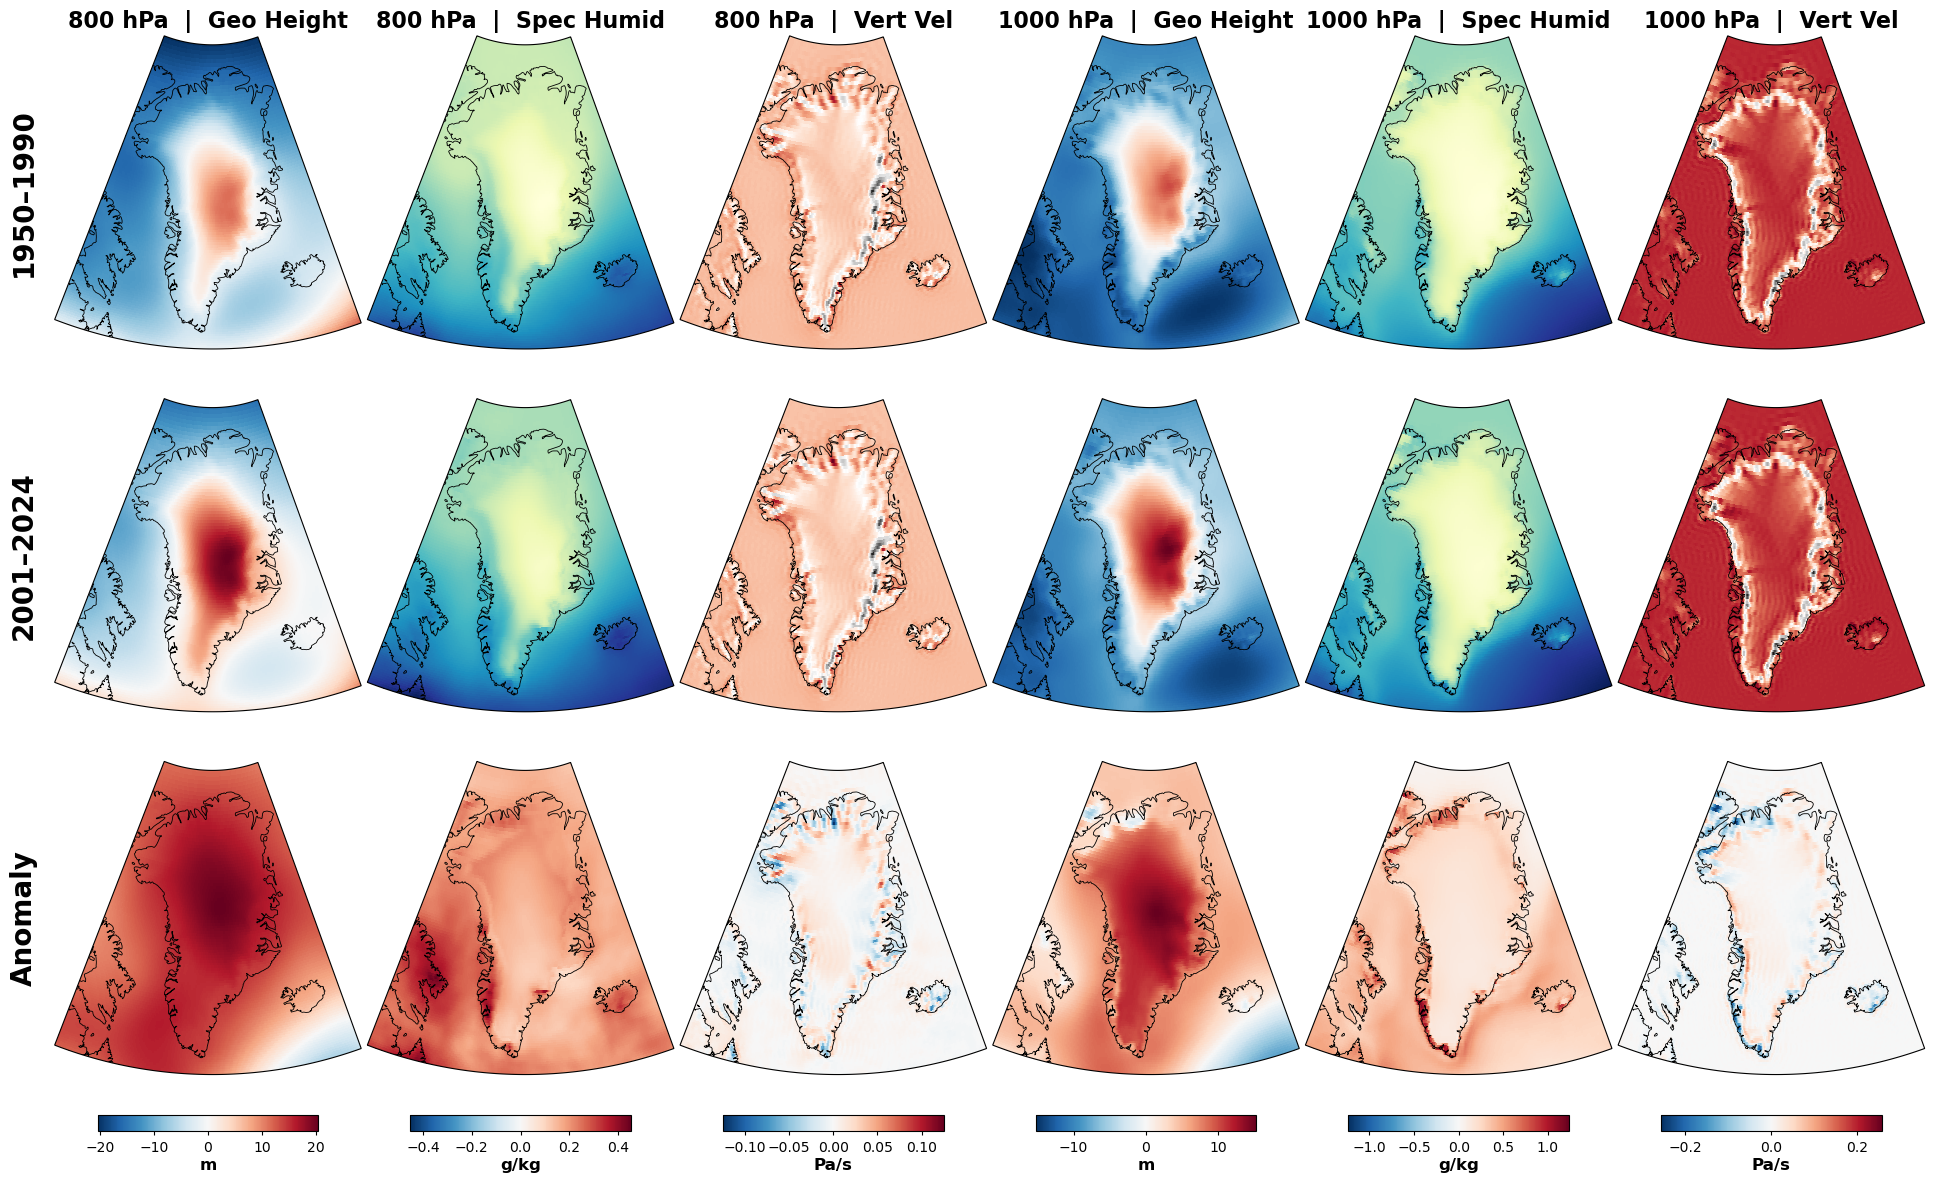

In [28]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.gridspec import GridSpec
from matplotlib.path import Path

# ===================== 投影与显示范围（关键：放大extent） =====================
proj = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
pc   = ccrs.PlateCarree()

# ★把范围放大：保证西北/东北不被切
# 经验上格陵兰完整显示建议至少覆盖：lon [-75, -10], lat [58, 85]
extent = [-75, -10, 58.0, 85.0]  # [lonW, lonE, latS, latN]

# ===================== 用Matplotlib Path裁剪（不依赖shapely） =====================
def clip_to_extent(ax, extent, crs, n=240):
    lon0, lon1, lat0, lat1 = extent
    lons = np.linspace(lon0, lon1, n)
    lats = np.linspace(lat0, lat1, n)

    bottom = np.column_stack([lons, np.full_like(lons, lat0)])
    right  = np.column_stack([np.full_like(lats, lon1), lats])
    top    = np.column_stack([lons[::-1], np.full_like(lons, lat1)])
    left   = np.column_stack([np.full_like(lats, lon0), lats[::-1]])

    ring = np.vstack([bottom, right, top, left])
    path = Path(ring)
    ax.set_boundary(path, transform=crs)

# ===================== 数据读取与预处理 =====================
def get_processed_data(path, levels, extent):
    ds = xr.open_dataset(path)

    rename_map = {}
    if 'lat' in ds.coords: rename_map['lat'] = 'latitude'
    if 'lon' in ds.coords: rename_map['lon'] = 'longitude'
    if 'level' in ds.coords: rename_map['level'] = 'pressure_level'
    if 'plev' in ds.coords: rename_map['plev'] = 'pressure_level'
    if 'valid_time' in ds.coords: rename_map['valid_time'] = 'time'
    ds = ds.rename(rename_map)

    # 经度若是0–360，转为-180–180
    if ds.longitude.max() > 180:
        ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180))
        ds = ds.sortby("longitude")

    lonW, lonE, latS, latN = extent

    # 纬度升/降序都能切
    if ds.latitude[0] > ds.latitude[-1]:
        lat_slice = slice(latN, latS)
    else:
        lat_slice = slice(latS, latN)

    ds = ds.sel(
        latitude=lat_slice,
        longitude=slice(lonW, lonE),
        pressure_level=levels
    )

    if 'z' in ds:
        ds['z'] = ds['z'] / 9.80665  # geopotential -> meters

    return ds

def jja_mean(ds, start, end):
    sub = ds.sel(time=slice(start, end))
    sub = sub.sel(time=sub.time.dt.month.isin([6, 7, 8]))
    return sub.mean("time").compute()

# ===================== 配置 =====================
LEVELS = [800, 1000]
PATH = r"C:\Users\11823\Downloads\new.nc"

variables = [
    {"code":"z","name":"Geo Height","unit":"m",    "cmap":"RdBu_r","scale":1},
    {"code":"q","name":"Spec Humid","unit":"g/kg", "cmap":"YlGnBu","scale":1e3},
    {"code":"w","name":"Vert Vel",  "unit":"Pa/s", "cmap":"RdGy",  "scale":1},
]

# ===================== 读数据、算均值与异常 =====================
ds   = get_processed_data(PATH, LEVELS, extent)
m1   = jja_mean(ds, "1950-01-01", "1990-12-31")
m2   = jja_mean(ds, "2001-01-01", "2024-12-31")
anom = m2 - m1

# ===================== 统一色标范围 =====================
mean_range = {}
anom_range = {}

for lev in LEVELS:
    for v in variables:
        c = v["code"]; s = v["scale"]
        d1 = (m1[c].sel(pressure_level=lev) * s)
        d2 = (m2[c].sel(pressure_level=lev) * s)
        da = (anom[c].sel(pressure_level=lev) * s)

        vmin = float(np.nanmin([d1.min(), d2.min()]))
        vmax = float(np.nanmax([d1.max(), d2.max()]))
        amax = float(np.nanmax(np.abs(da)))

        mean_range[(lev, c)] = (vmin, vmax, v["cmap"])
        anom_range[(lev, c)] = (-amax, amax, "RdBu_r")

# ===================== 绘图 =====================
plt.rcParams.update({"font.size": 16, "axes.titlesize": 20})

fig = plt.figure(figsize=(20, 13))
gs = GridSpec(
    nrows=4, ncols=6, figure=fig,
    height_ratios=[1, 1, 1, 0.05],
    hspace=0.12, wspace=0.02,
    left=0.06, right=0.995, top=0.95, bottom=0.10
)

def draw_map(ax, da, vmin, vmax, cmap):
    ax.set_extent(extent, crs=pc)
    clip_to_extent(ax, extent, pc, n=260)  # 边界更密一点更贴合
    ax.add_feature(cfeature.COASTLINE, lw=0.6)
    im = ax.pcolormesh(
        da.longitude, da.latitude, da,
        transform=pc, cmap=cmap,
        vmin=vmin, vmax=vmax, shading="auto"
    )
    return im

col_defs = [(800,'z'),(800,'q'),(800,'w'),
            (1000,'z'),(1000,'q'),(1000,'w')]
row_data   = [m1, m2, anom]
row_titles = ["1950–1990", "2001–2024", "Anomaly"]

col_mappables = [None] * 6
col_units = [next(v for v in variables if v["code"] == code)["unit"] for (_, code) in col_defs]

for r in range(3):
    for c in range(6):
        lev, code = col_defs[c]
        var = next(v for v in variables if v["code"] == code)
        s = var["scale"]

        da = row_data[r][code].sel(pressure_level=lev) * s

        if r < 2:
            vmin, vmax, cmap = mean_range[(lev, code)]
        else:
            vmin, vmax, cmap = anom_range[(lev, code)]

        ax = fig.add_subplot(gs[r, c], projection=proj)
        im = draw_map(ax, da, vmin, vmax, cmap)

        if r == 0:
            ax.set_title(f"{lev} hPa  |  {var['name']}", fontsize=16, weight="bold", pad=6)

        if c == 0:
            ax.text(-0.10, 0.5, row_titles[r],
                    transform=ax.transAxes, rotation=90,
                    ha="center", va="center",
                    fontsize=20, weight="bold")

        col_mappables[c] = im

for c in range(6):
    cax = fig.add_subplot(gs[3, c])
    pos = cax.get_position()
    shrink = 0.72
    xpad = (1 - shrink) / 2
    cax.set_position([pos.x0 + pos.width * xpad, pos.y0, pos.width * shrink, pos.height])

    cb = plt.colorbar(col_mappables[c], cax=cax, orientation="horizontal")
    cb.ax.tick_params(labelsize=10, length=3)
    cb.set_label(col_units[c], fontsize=12, weight="bold", labelpad=2)

plt.show()


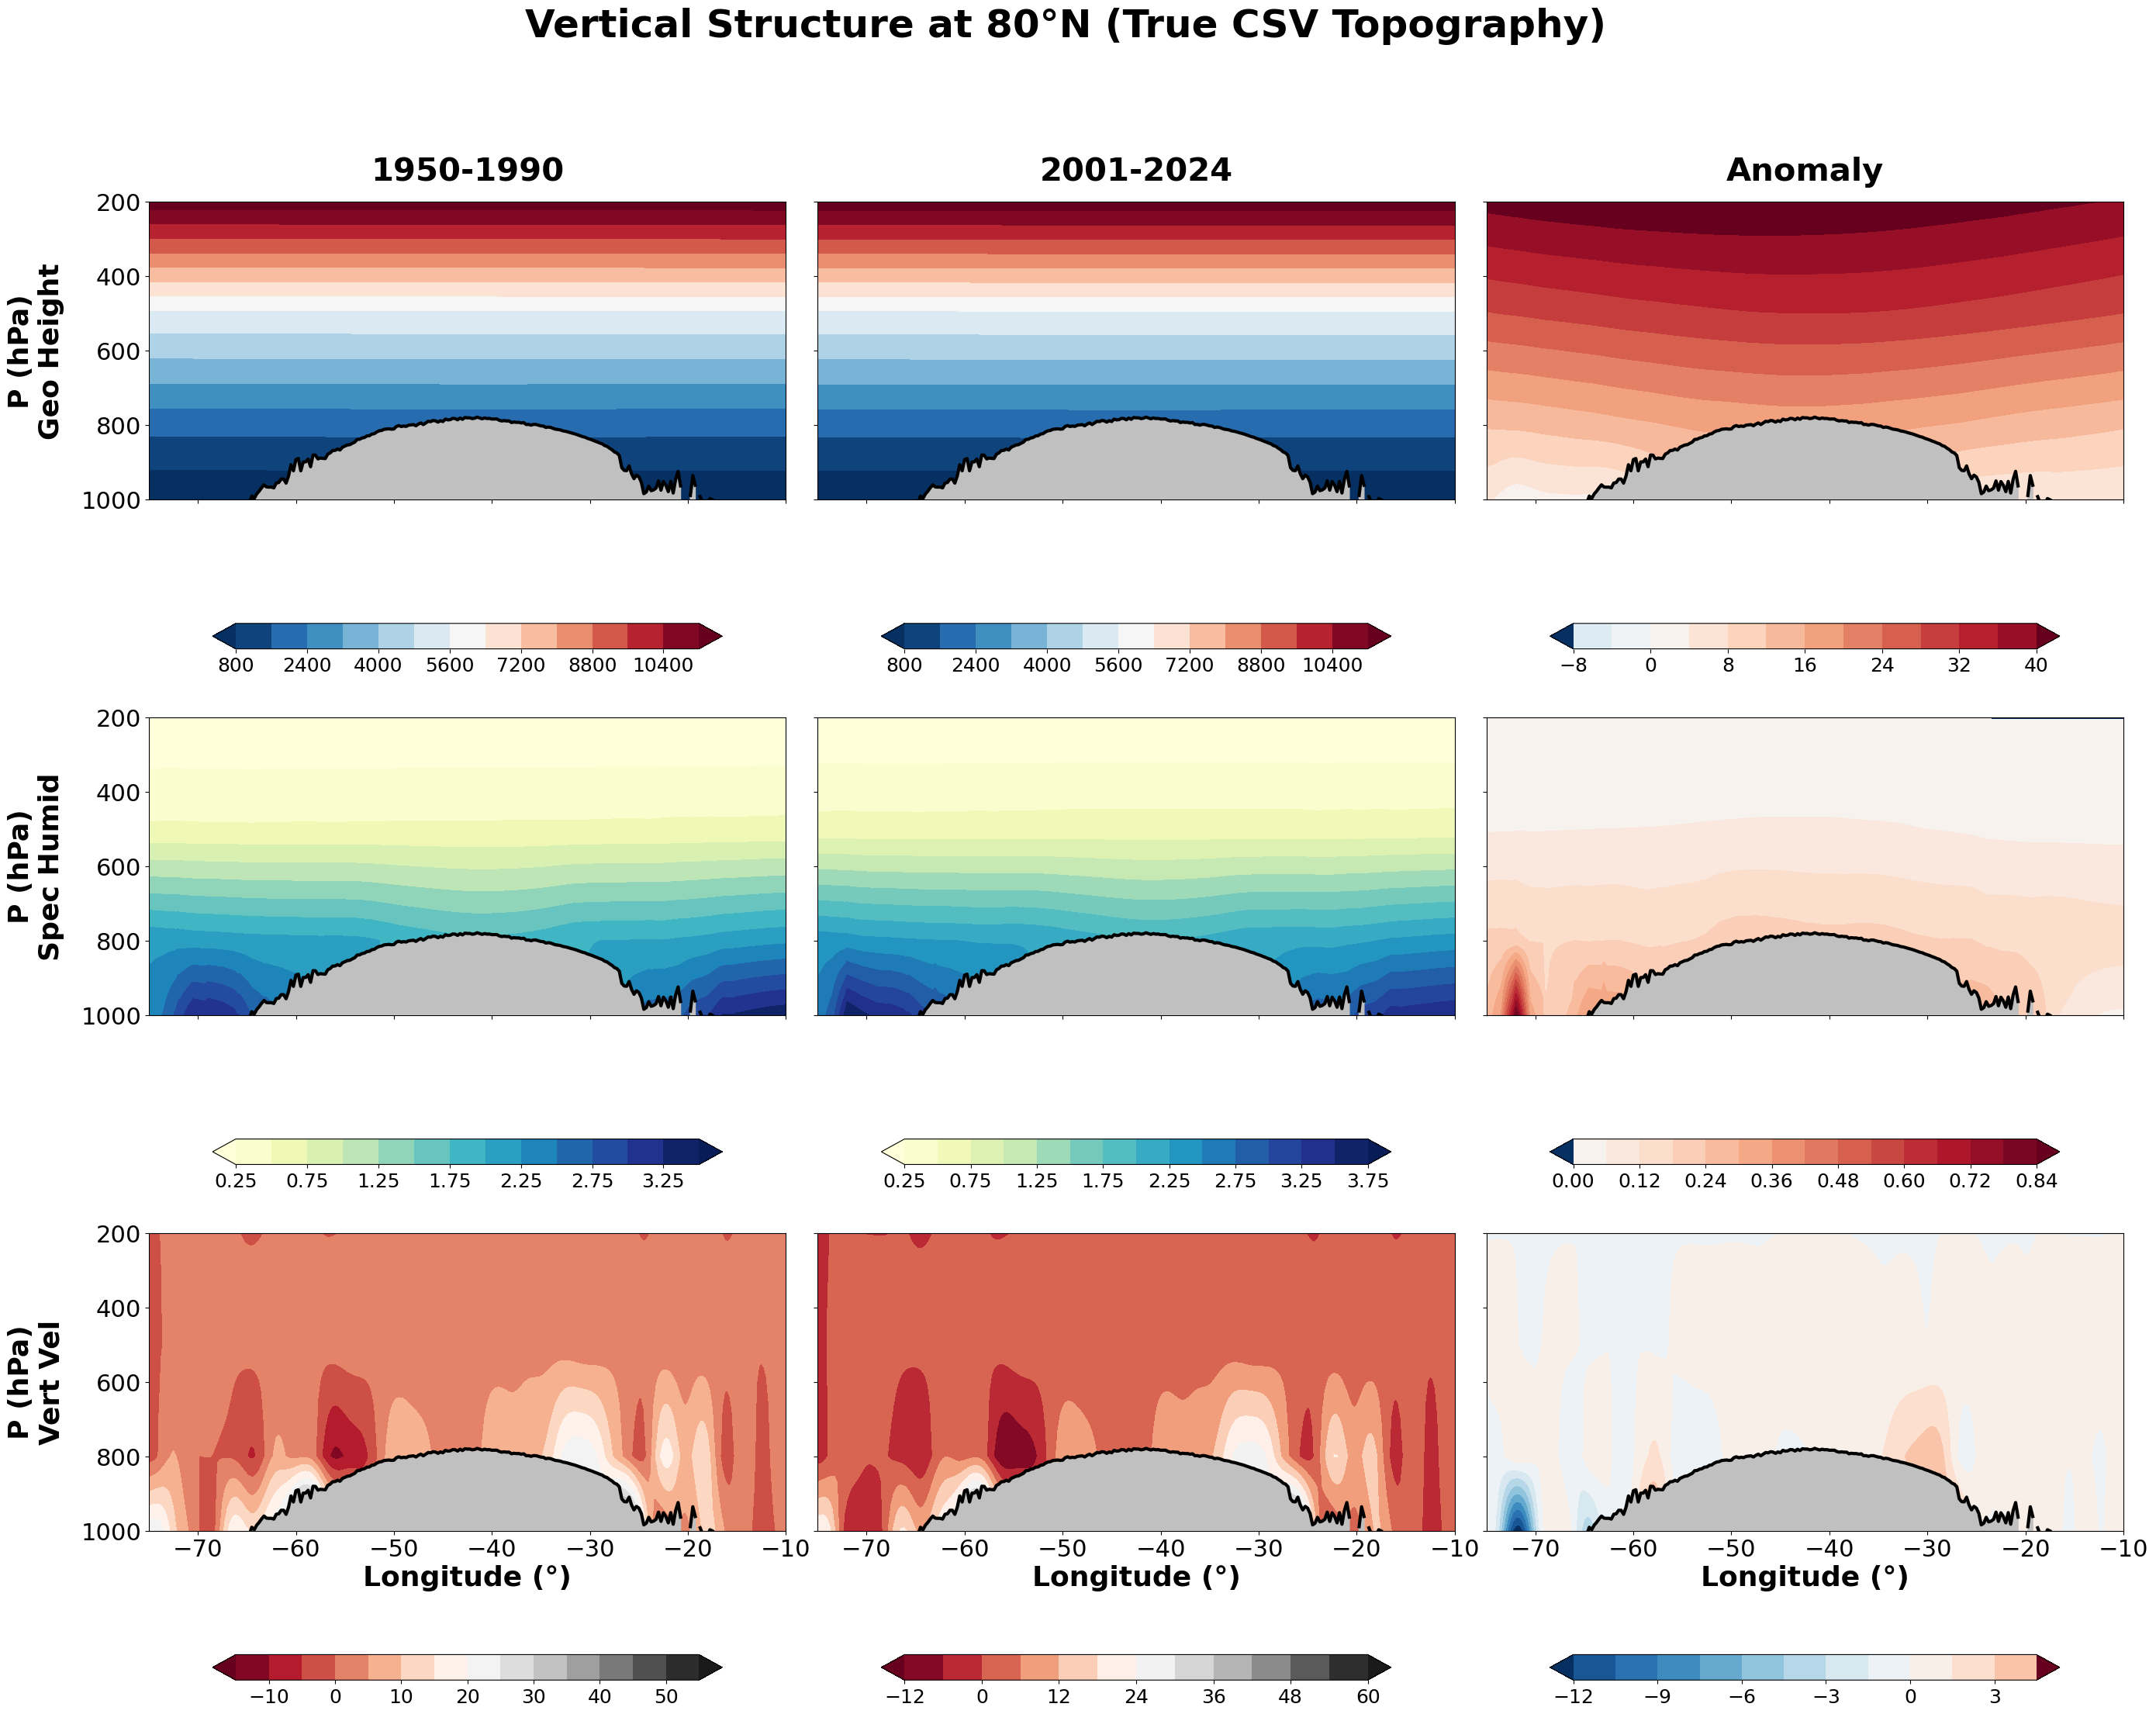

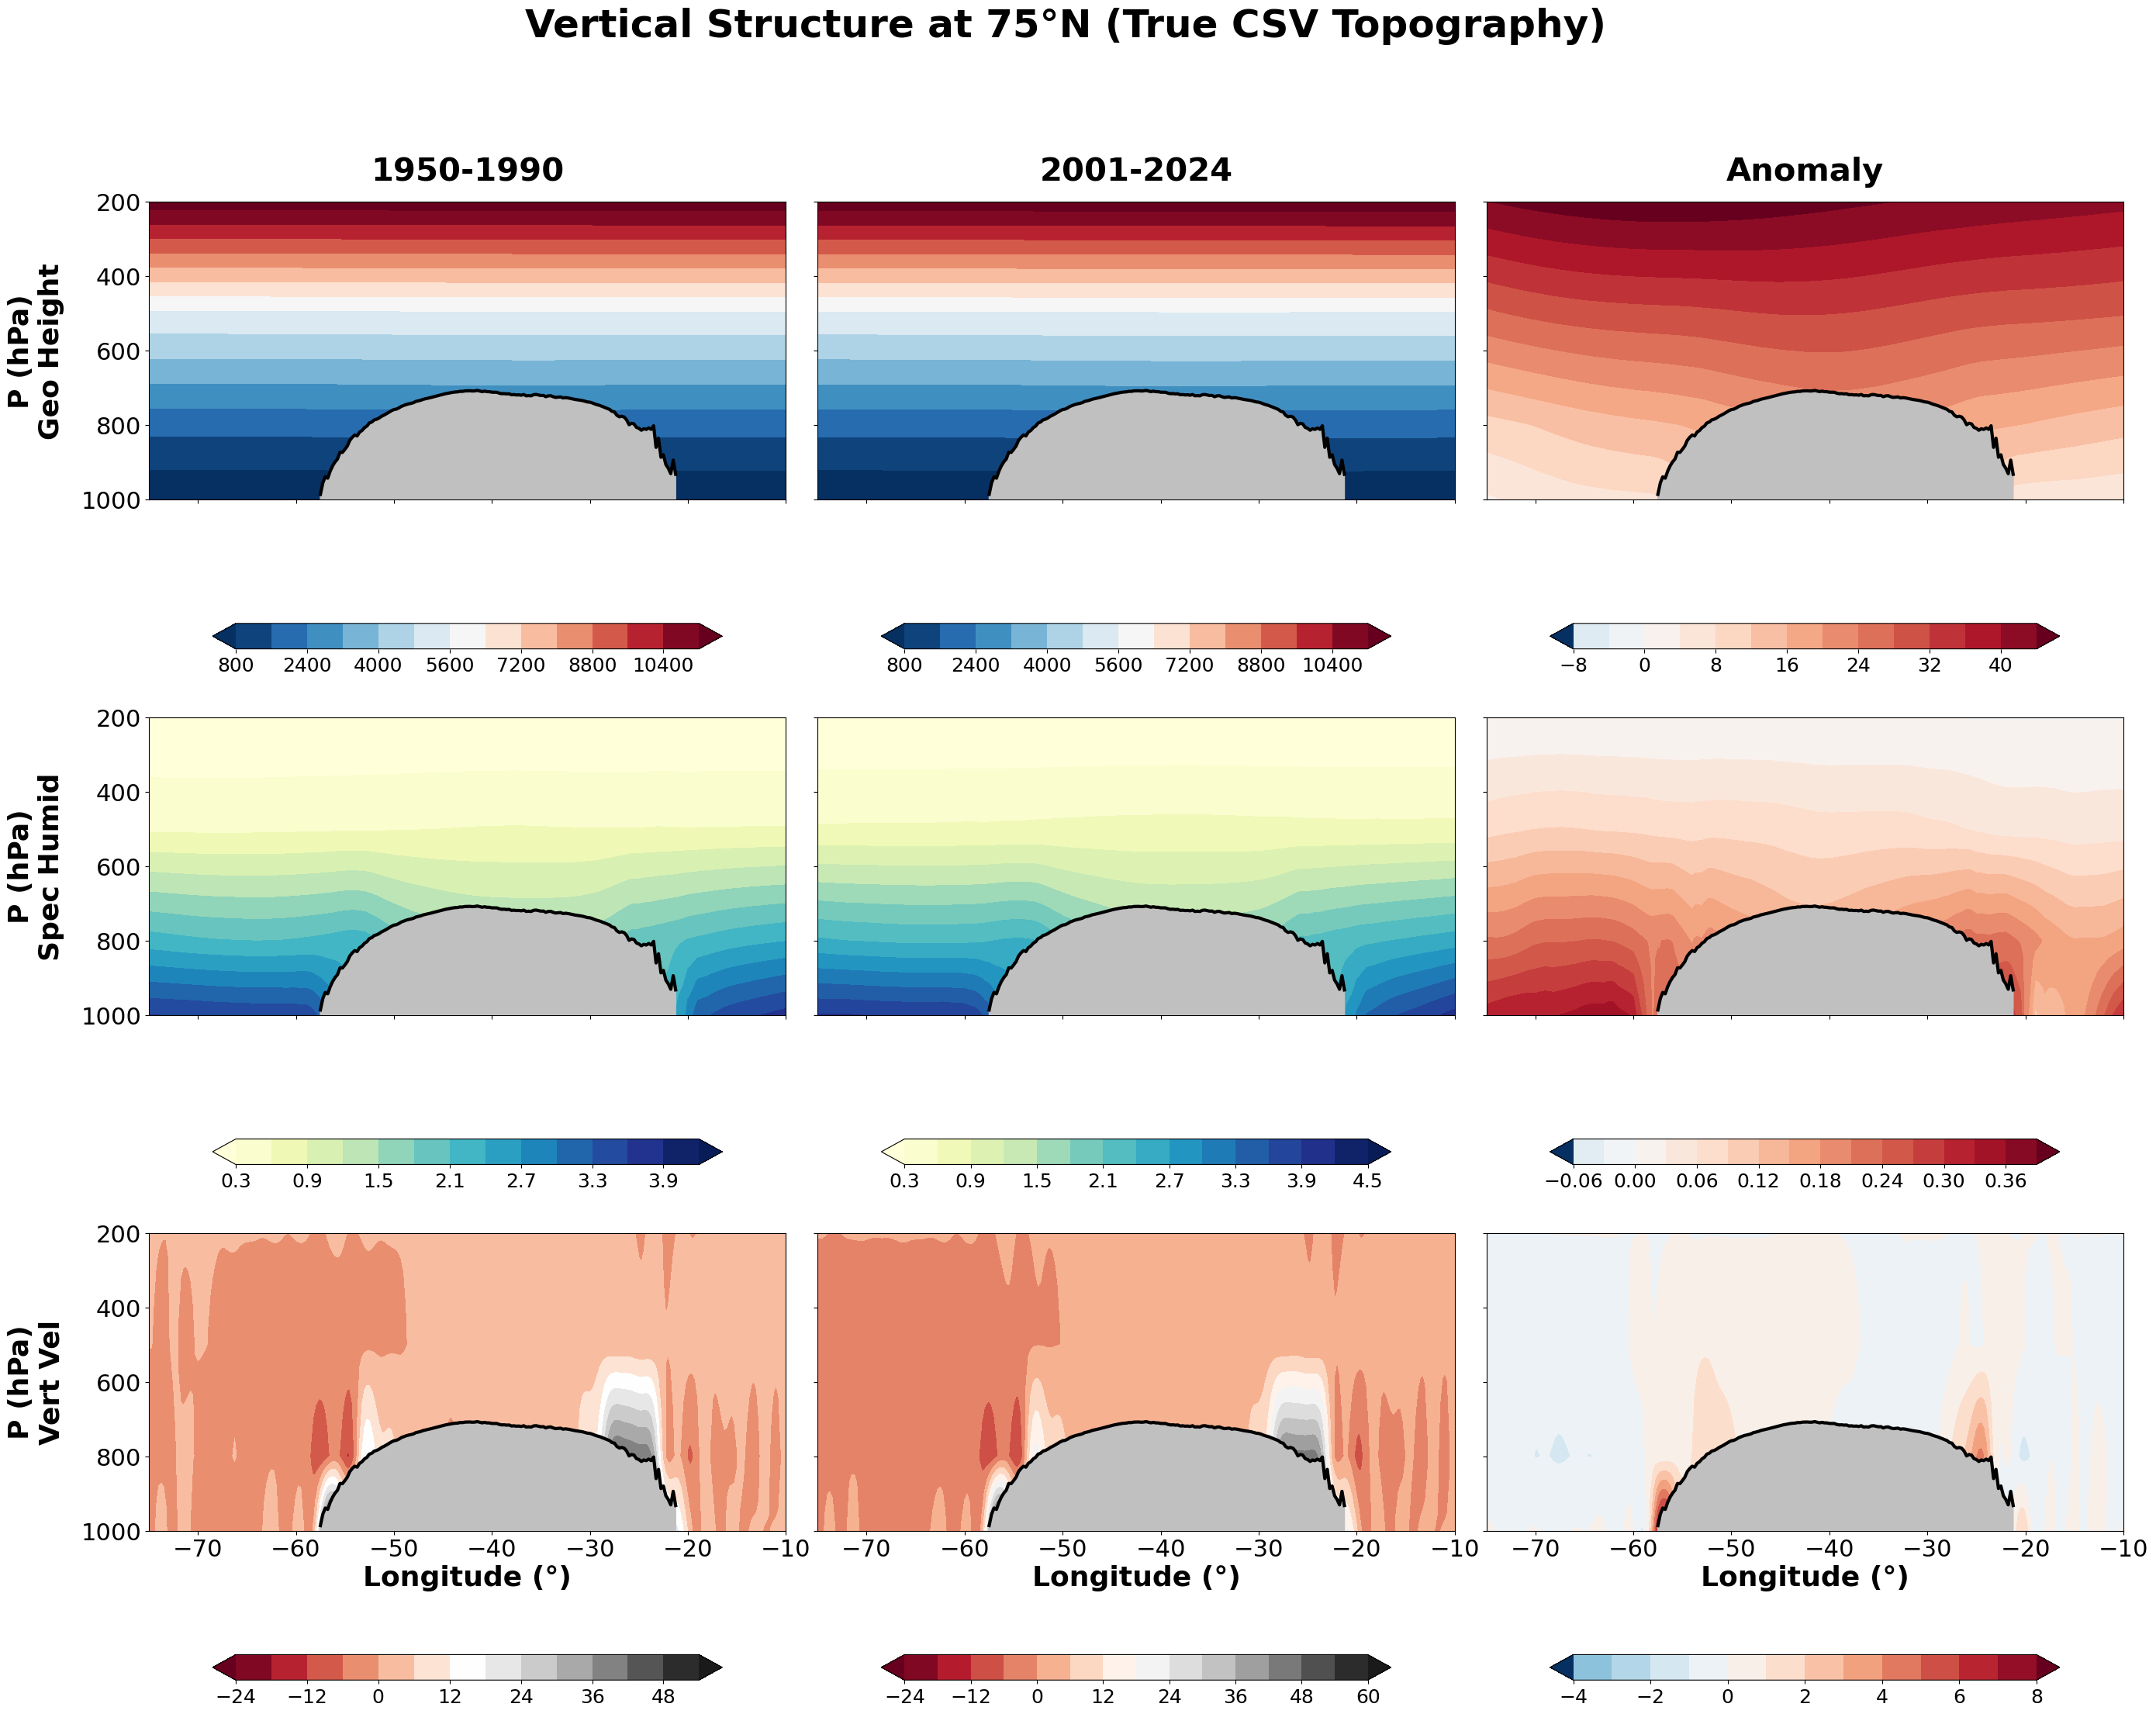

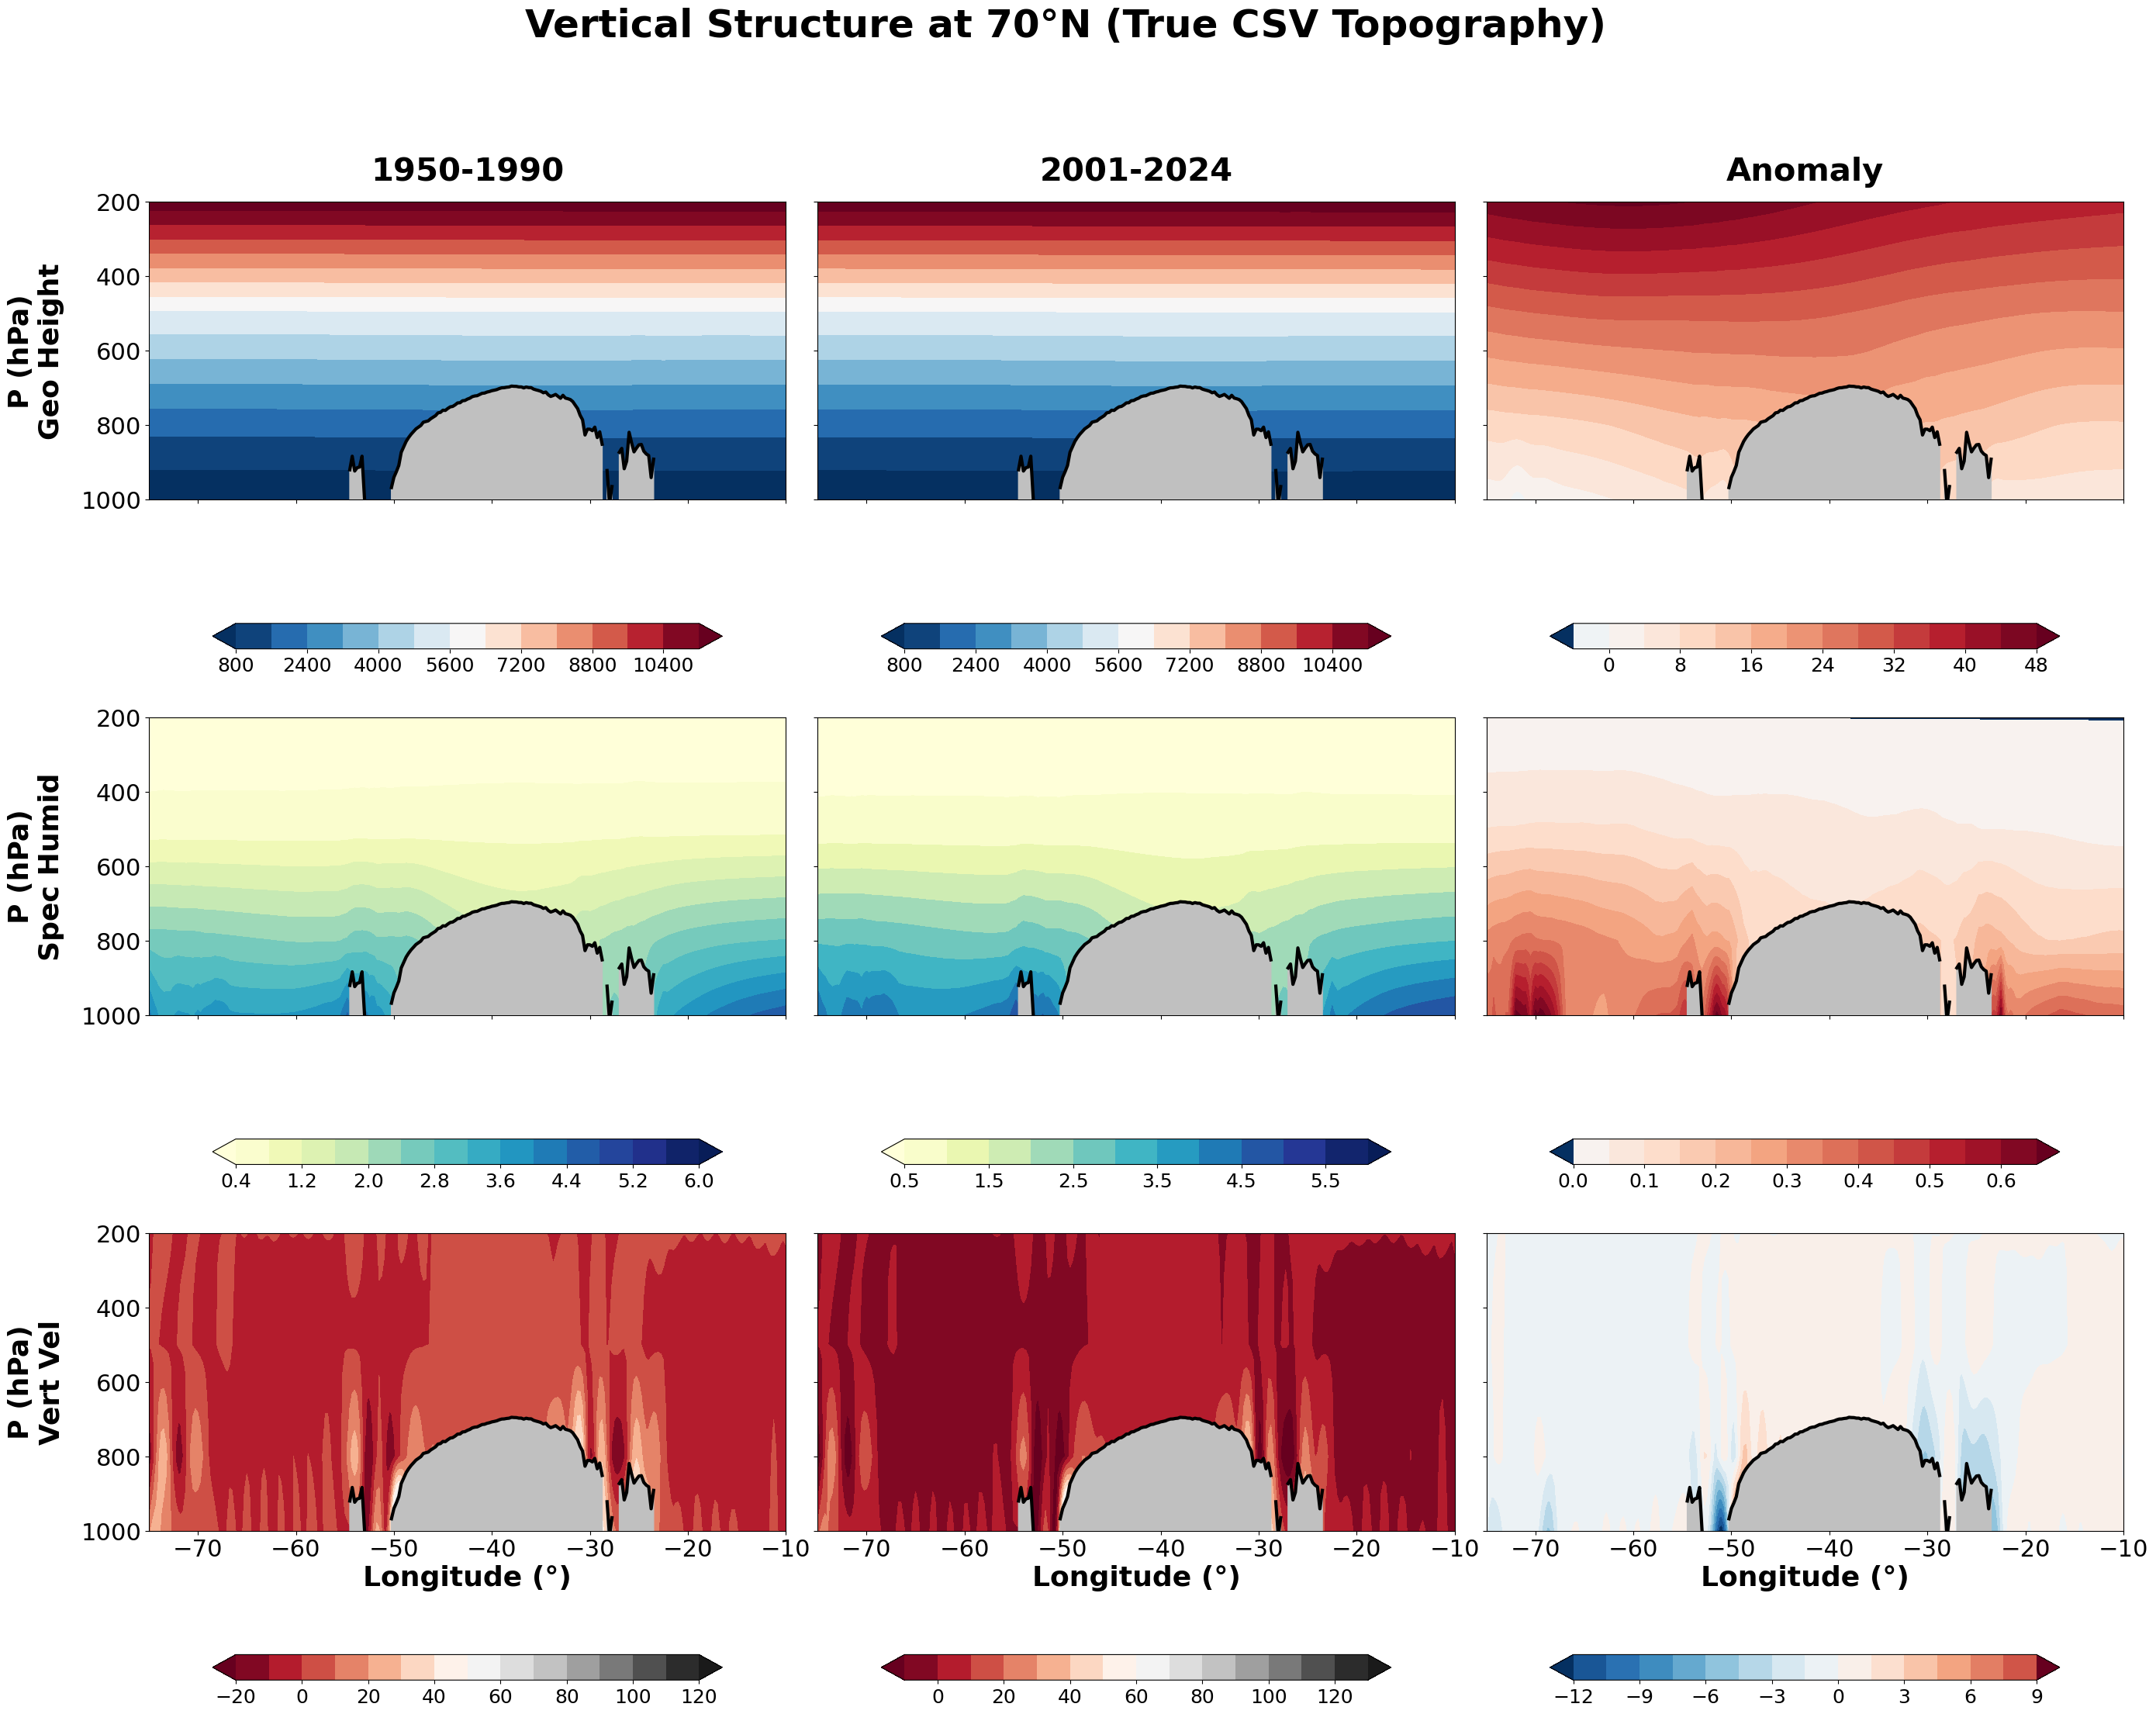

In [10]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import interp1d

# ===================== 1. 路径与全局配置 =====================
NC_FILE = r"C:\Users\11823\Downloads\Geopotential, Specific humidity, Vertical velocity.nc"
CSV_PATH = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\2025678allfeature.csv"

TARGET_LATS = [80, 75, 70]  # 目标纬度（北纬）

plt.rcParams.update({
    'font.size': 24,
    'axes.titlesize': 30,
    'axes.labelsize': 26,
    'xtick.labelsize': 22,
    'ytick.labelsize': 22,
    'legend.fontsize': 22,
    'figure.titlesize': 36
})

# ===================== 2. 数据处理：时间切片与均值 =====================
ds = xr.open_dataset(NC_FILE)
T_DIM = 'valid_time'
Z_DIM = 'pressure_level'

m1 = ds.sel({T_DIM: slice('1950', '1990')}).mean(T_DIM)
m2 = ds.sel({T_DIM: slice('2001', '2024')}).mean(T_DIM)
anom = m2 - m1

VARIABLES = [
    {'code': 'z', 'name': 'Geo Height', 'cmap': 'RdBu_r', 'unit': 'm', 'scale': 1/9.80665},
    {'code': 'q', 'name': 'Spec Humid', 'cmap': 'YlGnBu', 'unit': 'g/kg', 'scale': 1e3},
    {'code': 'w', 'name': 'Vert Vel', 'cmap': 'RdGy', 'unit': 'Pa/s*100', 'scale': 100}
]

LEVELS_VALS = ds[Z_DIM].values
LONS = ds.longitude.values  # 横轴改成经度

# ===================== 3. CSV 地形：固定纬度，沿经度插值→换算 hPa =====================
def get_csv_terrain_hPa_along_lon(lons_target, target_lat):
    """
    固定一个纬度 target_lat：
    1) 从CSV找最接近该纬度的行
    2) 沿经度插值海拔(m)到 lons_target
    3) 海拔->地面气压(hPa)，用于遮罩
    """
    df = pd.read_csv(CSV_PATH)

    # 匹配纬度（容差可按你的CSV网格调整）
    mask = np.isclose(df['latitude'], target_lat, atol=0.1)
    df_lat = df[mask].copy()

    if df_lat.empty:
        print(f"警告：CSV 中找不到纬度 {target_lat} 附近的数据")
        return np.full_like(lons_target, 1013.25, dtype=float)

    # 排序并去重（按经度）
    df_lat = df_lat.sort_values('longitude').drop_duplicates('longitude')

    # 沿经度插值海拔
    f_interp = interp1d(df_lat['longitude'], df_lat['altitude'],
                        kind='linear', bounds_error=False, fill_value="extrapolate")
    topo_m = f_interp(lons_target)

    # 海拔(m) -> 气压(hPa)
    topo_hPa = 1013.25 * (1 - 2.25577e-5 * topo_m)**5.25588
    topo_hPa = np.clip(topo_hPa, 200, 1013.25)
    return topo_hPa

# ===================== 4. 绘图循环：固定纬度剖面 =====================
for lat in TARGET_LATS:
    fig, axes = plt.subplots(3, 3, figsize=(28, 24), sharex=True, sharey=True)

    topo_hPa = get_csv_terrain_hPa_along_lon(LONS, lat)

    for r, var in enumerate(VARIABLES):
        v_code = var['code']
        factor = var.get('scale', 1.0)

        # 沿纬度切片：固定纬度
        d1 = m1[v_code].sel(latitude=lat, method='nearest').compute() * factor
        d2 = m2[v_code].sel(latitude=lat, method='nearest').compute() * factor
        da = anom[v_code].sel(latitude=lat, method='nearest').compute() * factor

        plot_list = [d1, d2, da]

        for c in range(3):
            ax = axes[r, c]
            curr_data = plot_list[c]

            cmap = var['cmap'] if c < 2 else 'RdBu_r'
            if c == 2:
                vmax = float(np.nanmax(np.abs(curr_data.values)))
                vmin, vmax = -vmax, vmax
            else:
                vmin, vmax = None, None

            # 注意：此时 curr_data 维度应是 (pressure_level, longitude)
            im = ax.contourf(LONS, LEVELS_VALS, curr_data, levels=15,
                             cmap=cmap, vmin=vmin, vmax=vmax, extend='both')

            # 真实地形遮罩（地表气压到图底）
            ax.fill_between(LONS, topo_hPa, 1100, color='silver', zorder=10)
            ax.plot(LONS, topo_hPa, color='black', linewidth=3, zorder=11)

            ax.set_ylim(1000, 200)

            # 这里经度范围按你格陵兰裁剪范围改；如果NC里是0-360，也可先转成-180~180
            ax.set_xlim(-75, -10)

            if r == 0:
                ax.set_title(['1950-1990', '2001-2024', 'Anomaly'][c], weight='bold', pad=20)
            if c == 0:
                ax.set_ylabel(f"P (hPa)\n{var['name']}", weight='bold', labelpad=15)
            if r == 2:
                ax.set_xlabel("Longitude (°)", weight='bold')

            cb = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.25, shrink=0.8)
            cb.ax.tick_params(labelsize=18)

    plt.suptitle(f"Vertical Structure at {lat}°N (True CSV Topography)", weight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0.05, 1, 0.96])
    plt.show()


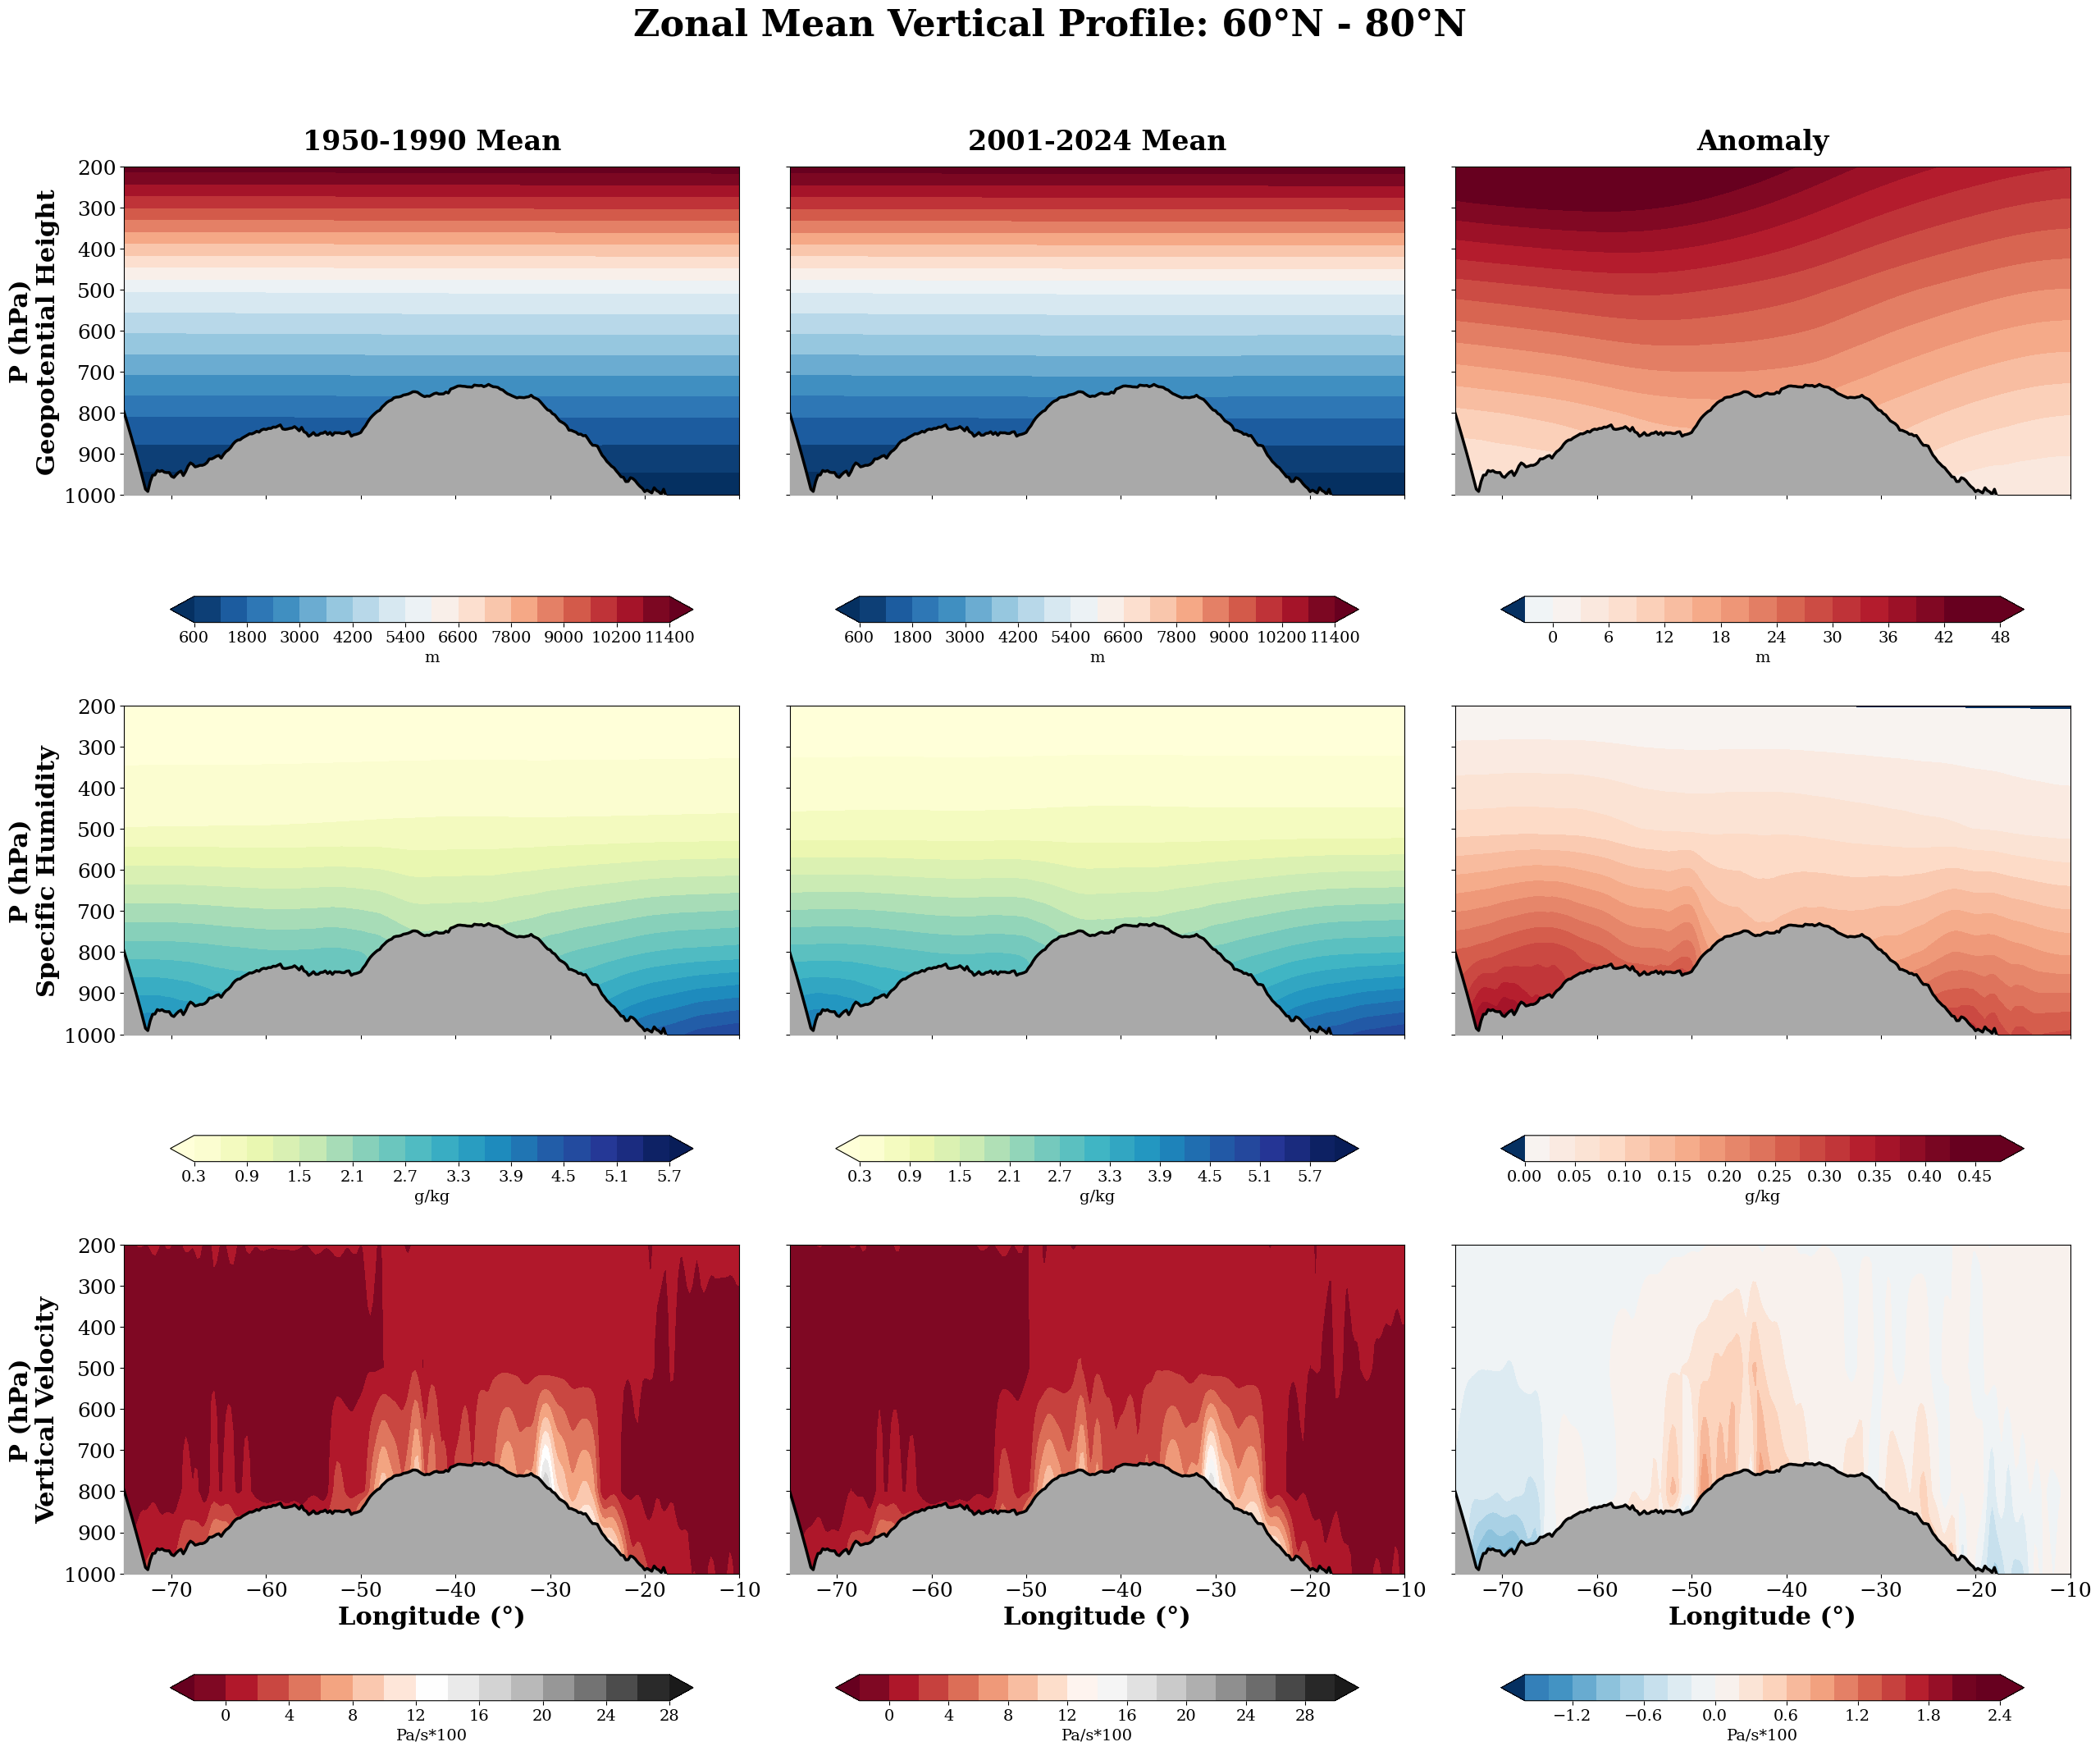

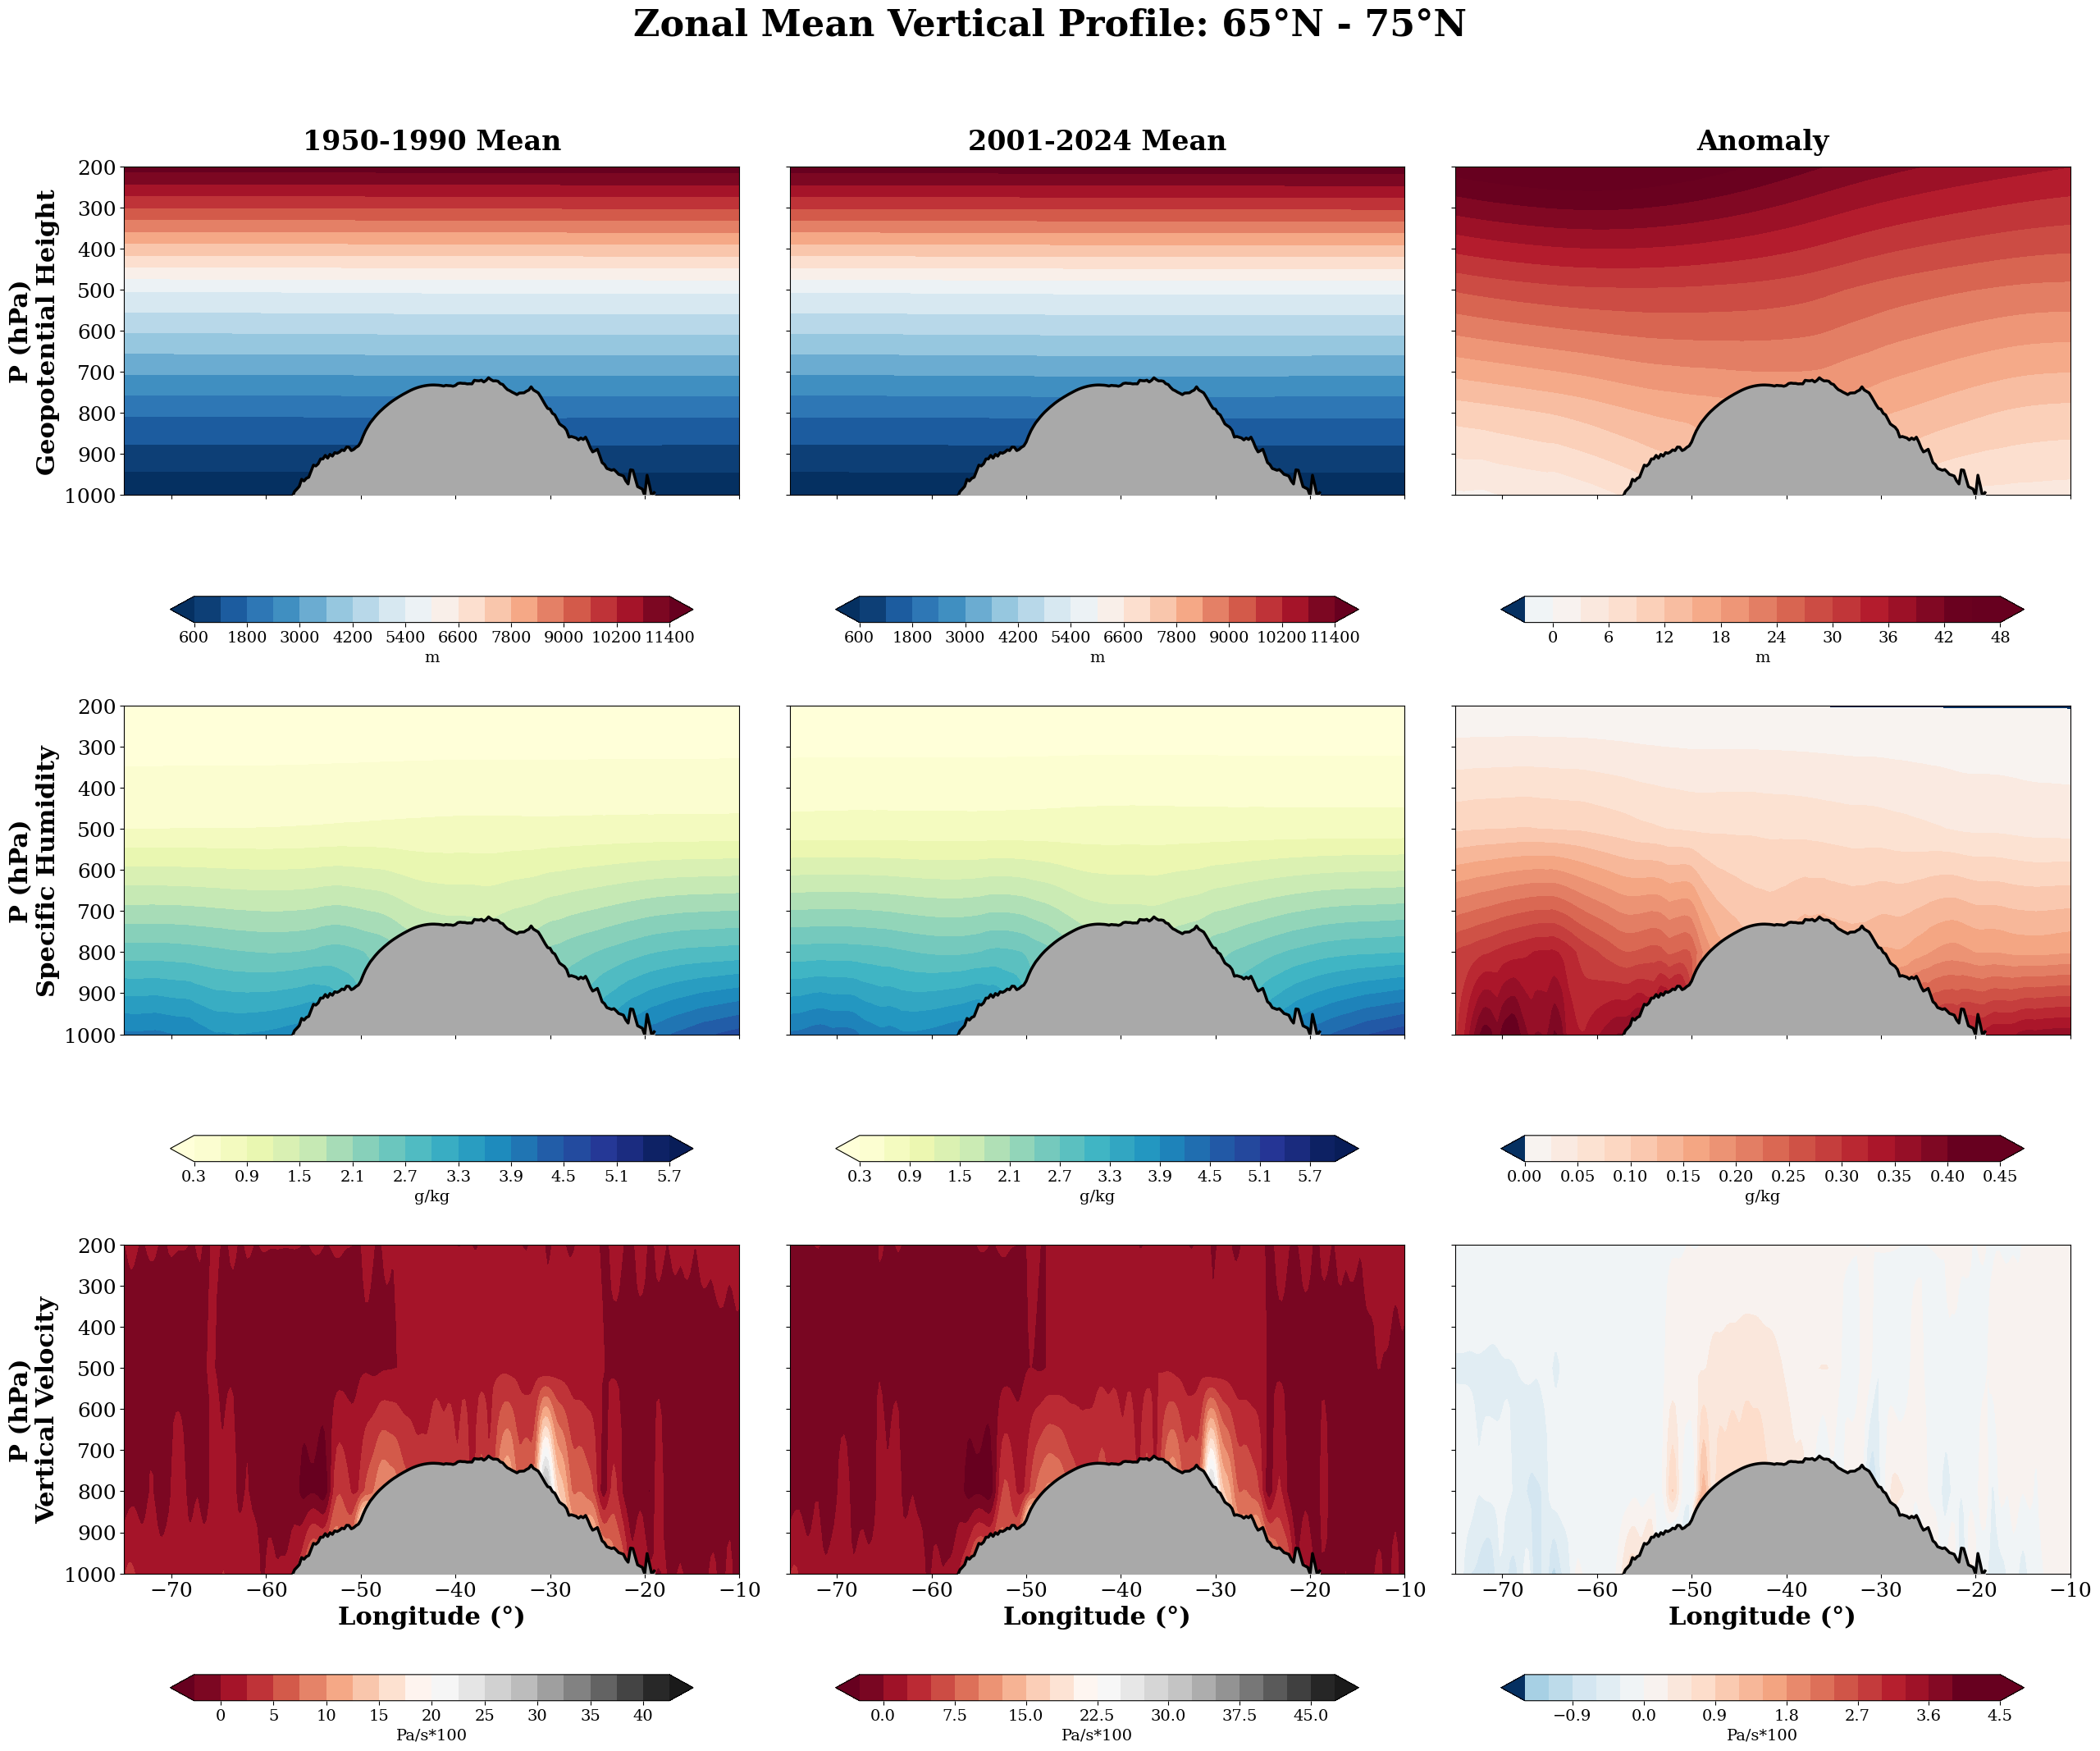

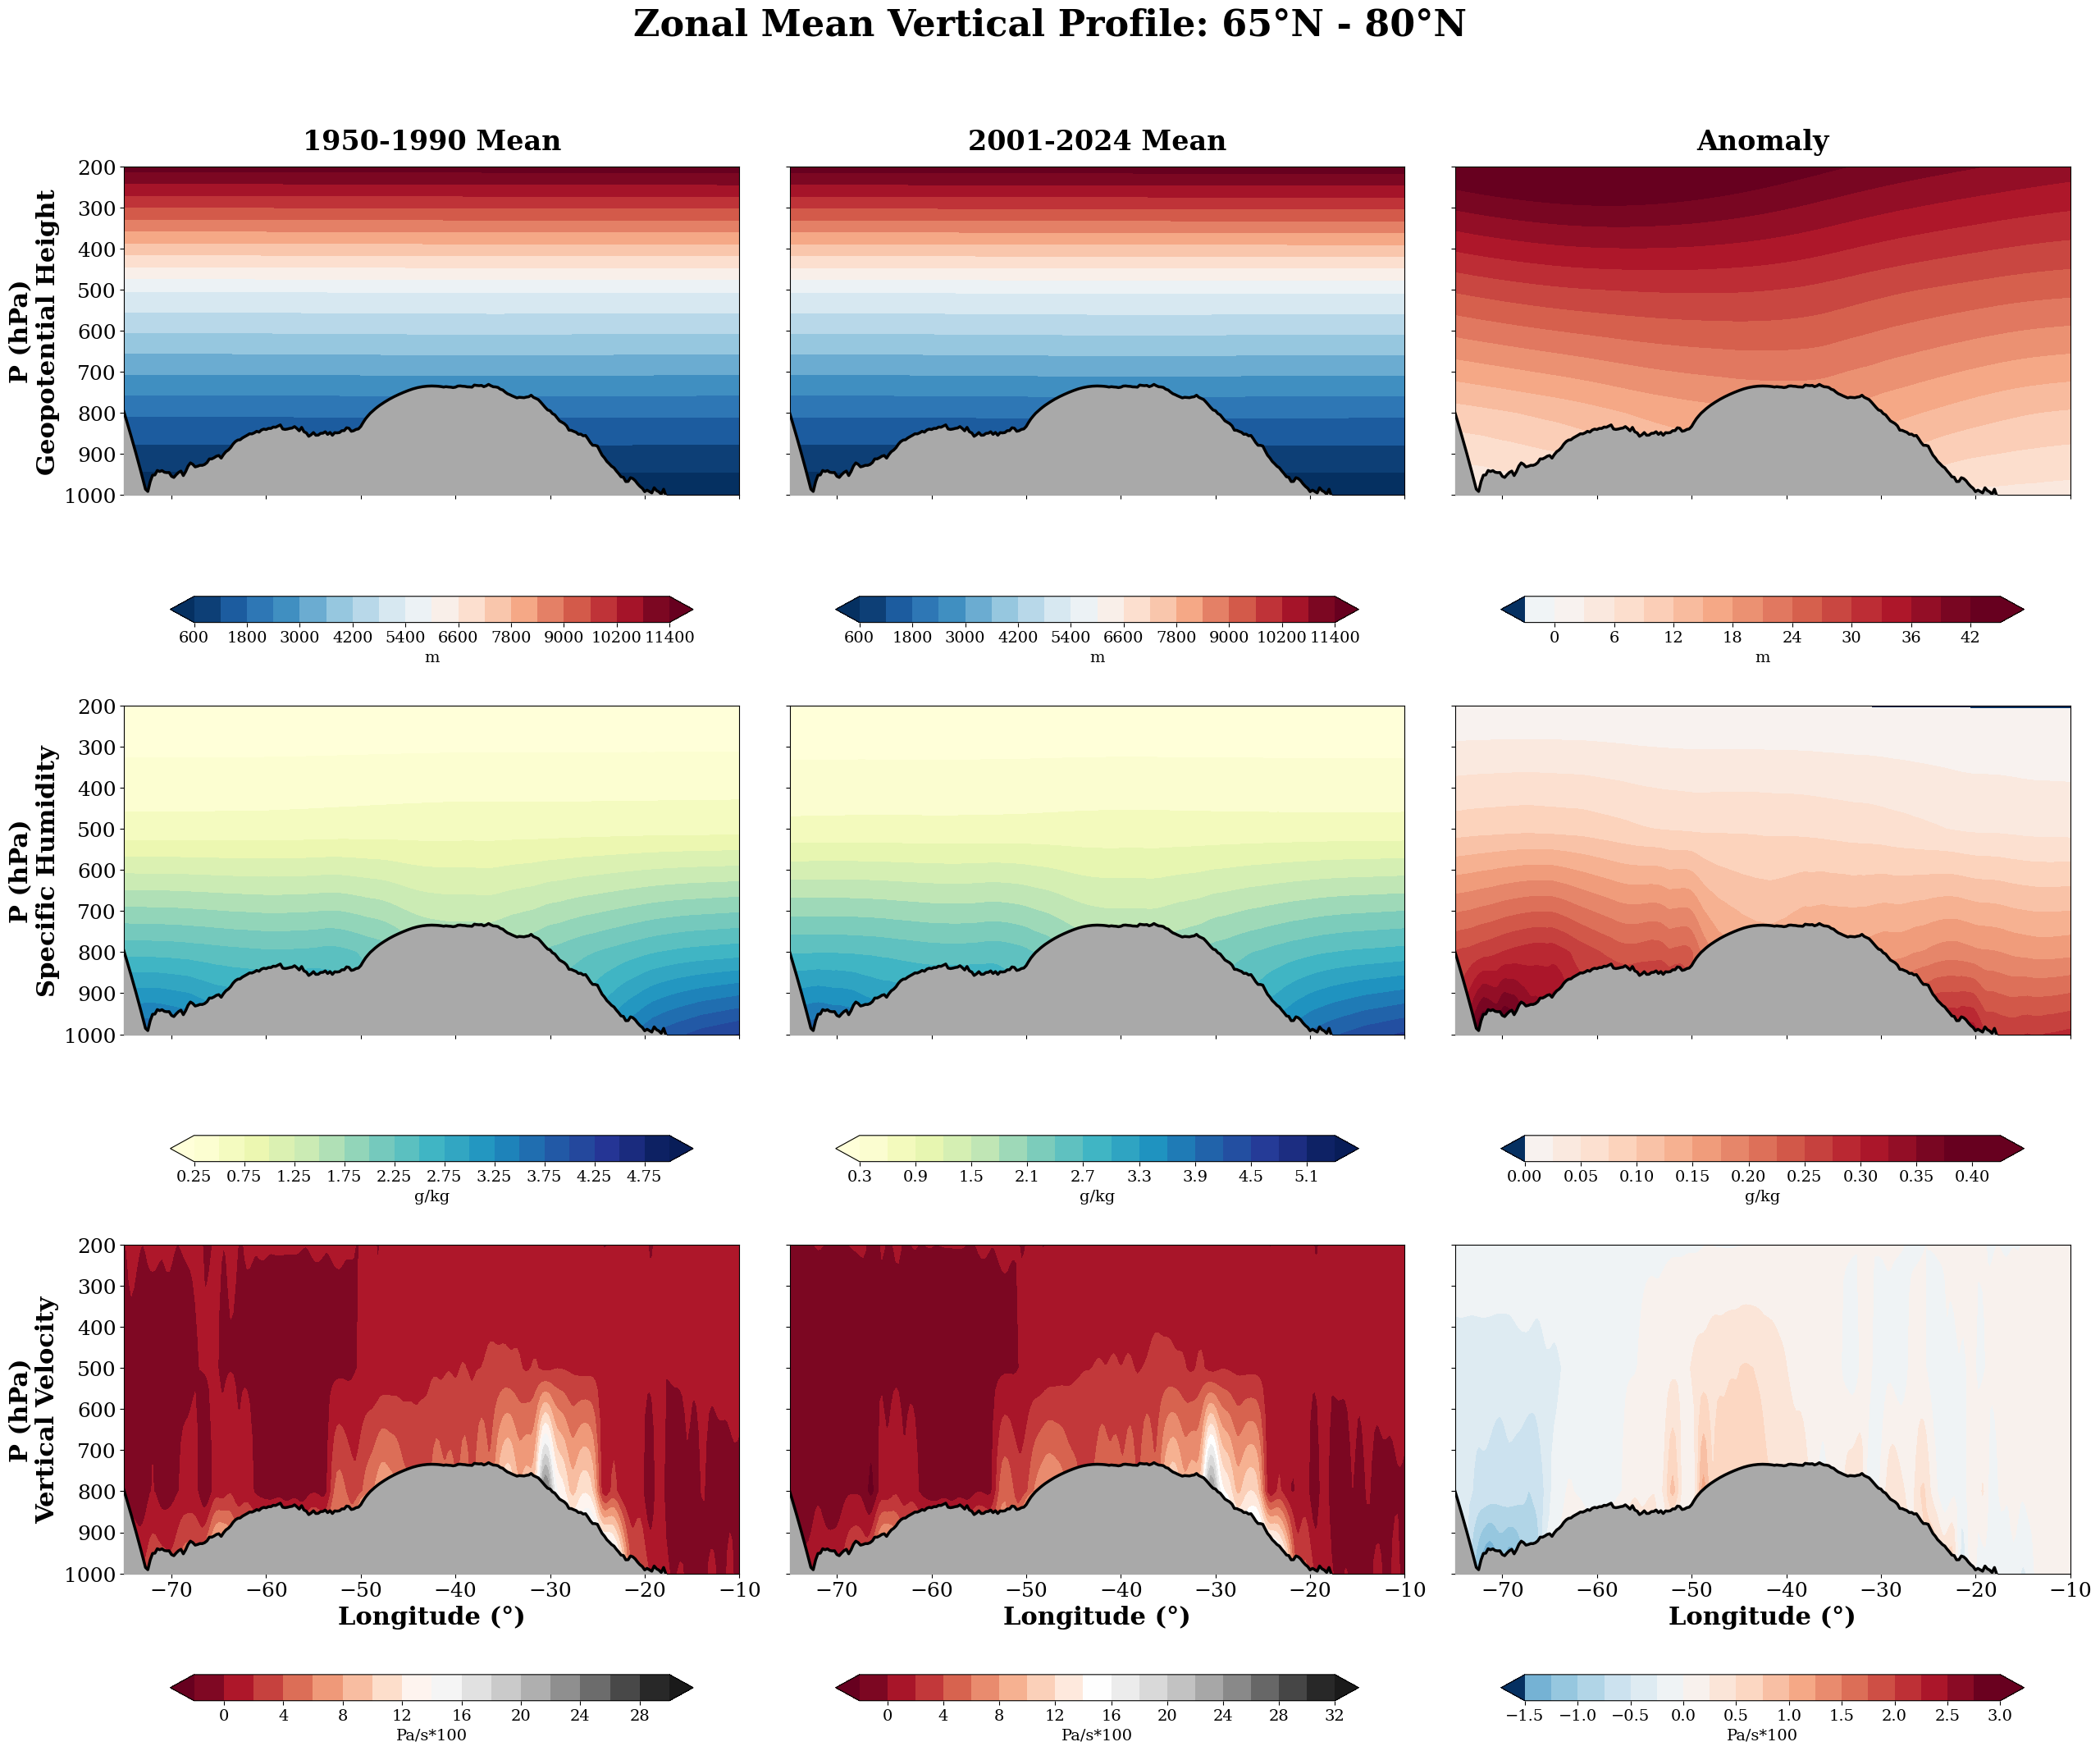

所有剖面图均生成完成。


In [12]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import interp1d

# ===================== 1. 路径与全局配置 =====================
NC_FILE = r"C:\Users\11823\Downloads\Geopotential, Specific humidity, Vertical velocity.nc"
CSV_PATH = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\2025678allfeature.csv"

# 你指定的三个研究区间
TARGET_LAT_BANDS = [
    (60, 80), 
    (65, 75), 
    (65, 80)
]

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 24,
    'axes.labelsize': 22,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 18,
    'figure.titlesize': 30,
    'font.family': 'serif'
})

# ===================== 2. 数据处理：时间平均与距平 =====================
ds = xr.open_dataset(NC_FILE)
# 自动识别维度名称，增强兼容性
T_DIM = 'valid_time' if 'valid_time' in ds.dims else 'time'
Z_DIM = 'pressure_level' if 'pressure_level' in ds.dims else 'level'

# 计算 1950-1990 与 2001-2024 的均值
m1 = ds.sel({T_DIM: slice('1950', '1990')}).mean(T_DIM)
m2 = ds.sel({T_DIM: slice('2001', '2024')}).mean(T_DIM)
anom = m2 - m1

VARIABLES = [
    {'code': 'z', 'name': 'Geopotential Height', 'cmap': 'RdBu_r', 'unit': 'm', 'scale': 1/9.80665},
    {'code': 'q', 'name': 'Specific Humidity', 'cmap': 'YlGnBu', 'unit': 'g/kg', 'scale': 1e3},
    {'code': 'w', 'name': 'Vertical Velocity', 'cmap': 'RdGy', 'unit': 'Pa/s*100', 'scale': 100}
]

LEVELS_VALS = ds[Z_DIM].values
LONS = ds.longitude.values

# ===================== 3. 绘图循环：纬度带均值剖面 =====================
for lat_start, lat_end in TARGET_LAT_BANDS:
    # 创建 3x3 画布：行代表变量，列代表 (m1, m2, anomaly)
    fig, axes = plt.subplots(3, 3, figsize=(26, 22), sharex=True, sharey=True)
    
    # --- A. 获取该纬度带的平均地形气压遮罩 ---
    df = pd.read_csv(CSV_PATH)
    # 筛选研究带内的数据
    df_band = df[(df['latitude'] >= lat_start) & (df['latitude'] <= lat_end)].copy()
    # 先按经度分组求平均海拔，确保地形与大气场在空间上匹配
    df_topo_avg = df_band.groupby('longitude')['altitude'].mean().reset_index()
    
    f_interp = interp1d(df_topo_avg['longitude'], df_topo_avg['altitude'],
                        kind='linear', bounds_error=False, fill_value="extrapolate")
    topo_m_avg = f_interp(LONS)
    # 气压公式：P = P0 * (1 - L*h/T0)^5.255
    topo_hPa_avg = 1013.25 * (1 - 2.25577e-5 * topo_m_avg)**5.25588
    topo_hPa_avg = np.clip(topo_hPa_avg, 200, 1013.25)

    # --- B. 变量绘图 ---
    for r, var in enumerate(VARIABLES):
        v_code = var['code']
        factor = var.get('scale', 1.0)

        # 在指定的纬度区间内取均值 (注意 slice 需根据你 NC 文件的 lat 顺序调整)
        # 如果 lat 是从北向南，用 slice(lat_end, lat_start)；反之亦然
        try:
            d1_band = m1[v_code].sel(latitude=slice(lat_end, lat_start)).mean('latitude').compute() * factor
            d2_band = m2[v_code].sel(latitude=slice(lat_end, lat_start)).mean('latitude').compute() * factor
            da_band = anom[v_code].sel(latitude=slice(lat_end, lat_start)).mean('latitude').compute() * factor
        except:
            # 容错：如果 slice 顺序不对，尝试反过来
            d1_band = m1[v_code].sel(latitude=slice(lat_start, lat_end)).mean('latitude').compute() * factor
            d2_band = m2[v_code].sel(latitude=slice(lat_start, lat_end)).mean('latitude').compute() * factor
            da_band = anom[v_code].sel(latitude=slice(lat_start, lat_end)).mean('latitude').compute() * factor

        plots = [d1_band, d2_band, da_band]

        for c in range(3):
            ax = axes[r, c]
            data_to_plot = plots[c]
            
            # 设置色阶
            if c == 2: # Anomaly 
                cmap = 'RdBu_r'
                # 距平图建议使用对称量程
                v_limit = float(np.nanmax(np.abs(data_to_plot.values))) * 0.9
                vmin, vmax = -v_limit, v_limit
            else: # Mean states
                cmap = var['cmap']
                vmin, vmax = None, None

            # 绘制等值线填充
            cf = ax.contourf(LONS, LEVELS_VALS, data_to_plot, levels=20,
                             cmap=cmap, vmin=vmin, vmax=vmax, extend='both')

            # --- C. 地形遮罩与修饰 ---
            # 银灰色填充代表陆地地形
            ax.fill_between(LONS, topo_hPa_avg, 1100, color='darkgray', zorder=10)
            ax.plot(LONS, topo_hPa_avg, color='black', linewidth=2.5, zorder=11)

            # 设置气压坐标轴（对流层范围）
            ax.set_ylim(1000, 200)
            ax.set_xlim(-75, -10) # 格陵兰主要经度区间

            # 标注处理
            if r == 0:
                titles = ['1950-1990 Mean', '2001-2024 Mean', 'Anomaly']
                ax.set_title(titles[c], weight='bold', pad=15)
            if c == 0:
                ax.set_ylabel(f"P (hPa)\n{var['name']}", weight='bold')
            if r == 2:
                ax.set_xlabel("Longitude (°)", weight='bold')

            # 颜色条
            cb = plt.colorbar(cf, ax=ax, orientation='horizontal', pad=0.2, shrink=0.85)
            cb.set_label(var['unit'], fontsize=14)
            cb.ax.tick_params(labelsize=14)

    plt.suptitle(f"Zonal Mean Vertical Profile: {lat_start}°N - {lat_end}°N", 
                 weight='bold', fontsize=32, y=0.98)
    
    # 保存或显示
    # plt.savefig(f"Vertical_Profile_{lat_start}_{lat_end}.png", dpi=300, bbox_inches='tight')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

print("所有剖面图均生成完成。")

In [4]:
import geopandas as gpd
import os

# ============================================================
# 路径配置
# ============================================================
base_path = r"C:\greenland\Greenland_shp"
boundary_path = os.path.join(base_path, "Gboundry.shp")
basin_folder = os.path.join(base_path, "流域冰盖")

# 8个流域的文件名（按你的命名规则）
basin_files = [
    "North.shp",
    "EastNorth.shp",
    "East.shp",
    "EastSouth.shp",
    "South.shp",
    "WestSouth.shp",
    "West.shp",
    "WestNorth.shp",
]

# ============================================================
# 读取数据
# ============================================================
print("=" * 60)
print("读取 Greenland 总边界...")
gris = gpd.read_file(boundary_path)
print(f"  CRS: {gris.crs}")
print(f"  几何体数量: {len(gris)}")

# 如果总边界有多个几何体，合并为一个
if len(gris) > 1:
    gris_merged = gris.dissolve().reset_index(drop=True)
else:
    gris_merged = gris.copy()

print("\n" + "=" * 60)
print("读取8个流域...")
basins = {}
for f in basin_files:
    fpath = os.path.join(basin_folder, f)
    if os.path.exists(fpath):
        gdf = gpd.read_file(fpath)
        name = os.path.splitext(f)[0]
        basins[name] = gdf
        print(f"  ✓ {name}: {len(gdf)} 个几何体, CRS: {gdf.crs}")
    else:
        print(f"  ✗ 未找到: {f}")

# ============================================================
# 统一 CRS（如果不一致会报错提示）
# ============================================================
target_crs = gris_merged.crs
for name, gdf in basins.items():
    if gdf.crs != target_crs:
        print(f"\n⚠ CRS 不一致，正在将 {name} 转换为: {target_crs}")
        basins[name] = gdf.to_crs(target_crs)

# ============================================================
# 面积计算（需要投影坐标系才能算 km²）
# ============================================================
# 如果当前是经纬度坐标，先转到适合格陵兰的投影
if gris_merged.crs and gris_merged.crs.is_geographic:
    proj_crs = "EPSG:3413"  # NSIDC Sea Ice Polar Stereographic North
    print(f"\n当前是经纬度坐标，转换到 {proj_crs} 以计算面积...")
    gris_proj = gris_merged.to_crs(proj_crs)
    basins_proj = {name: gdf.to_crs(proj_crs) for name, gdf in basins.items()}
else:
    gris_proj = gris_merged.copy()
    basins_proj = basins.copy()

# 总面积
total_area_m2 = gris_proj.geometry.area.sum()
total_area_km2 = total_area_m2 / 1e6

print("\n" + "=" * 60)
print("面积计算结果")
print("=" * 60)
print(f"\n格陵兰总边界面积: {total_area_km2:,.1f} km²")
print(f"\n{'流域':<15} {'面积 (km²)':>15} {'占总面积 (%)':>15}")
print("-" * 47)

basin_total = 0
for name, gdf in basins_proj.items():
    area = gdf.geometry.area.sum() / 1e6
    basin_total += area
    pct = area / total_area_km2 * 100
    print(f"{name:<15} {area:>15,.1f} {pct:>14.2f}%")

print("-" * 47)
pct_total = basin_total / total_area_km2 * 100
print(f"{'8流域合计':<15} {basin_total:>15,.1f} {pct_total:>14.2f}%")

peripheral_area = total_area_km2 - basin_total
pct_peripheral = peripheral_area / total_area_km2 * 100
print(f"{'外围区域':<15} {peripheral_area:>15,.1f} {pct_peripheral:>14.2f}%")
print("=" * 60)

# ============================================================
# 生成外围区域 shp（总边界 - 8流域的并集）
# ============================================================
print("\n正在生成外围区域 shp 文件...")

# 合并8个流域为一个几何体
all_basins = []
for name, gdf in basins_proj.items():
    # 每个流域也可能有多个几何体，先合并
    merged = gdf.dissolve().reset_index(drop=True)
    all_basins.append(merged.geometry.iloc[0])

from shapely.ops import unary_union
basins_union = unary_union(all_basins)

# 总边界几何体
gris_geom = gris_proj.geometry.iloc[0]

# difference = 外围
peripheral_geom = gris_geom.difference(basins_union)

# 保存
peripheral_gdf = gpd.GeoDataFrame(
    {"name": ["peripheral"]},
    geometry=[peripheral_geom],
    crs=gris_proj.crs
)
output_path = os.path.join(base_path, "peripheral.shp")
peripheral_gdf.to_file(output_path)
print(f"  ✓ 已保存到: {output_path}")
print(f"  外围区域面积: {peripheral_geom.area / 1e6:,.1f} km²")

print("\n完成！请把上面的计算结果发给我。")

读取 Greenland 总边界...
  CRS: EPSG:4326
  几何体数量: 1

读取8个流域...
  ✓ North: 1 个几何体, CRS: EPSG:4326
  ✓ EastNorth: 1 个几何体, CRS: EPSG:4326
  ✓ East: 1 个几何体, CRS: EPSG:4326
  ✓ EastSouth: 1 个几何体, CRS: EPSG:4326
  ✓ South: 1 个几何体, CRS: EPSG:4326
  ✓ WestSouth: 1 个几何体, CRS: EPSG:4326
  ✓ West: 1 个几何体, CRS: EPSG:4326
  ✓ WestNorth: 1 个几何体, CRS: EPSG:4326

当前是经纬度坐标，转换到 EPSG:3413 以计算面积...

面积计算结果

格陵兰总边界面积: 2,143,693.9 km²

流域                     面积 (km²)        占总面积 (%)
-----------------------------------------------
North                 265,626.1          12.39%
EastNorth             309,062.8          14.42%
East                  274,562.1          12.81%
EastSouth             154,991.4           7.23%
South                  55,001.0           2.57%
WestSouth             192,268.4           8.97%
West                  225,787.1          10.53%
WestNorth             266,666.2          12.44%
-----------------------------------------------
8流域合计               1,743,965.2          81.35%
外围区域      

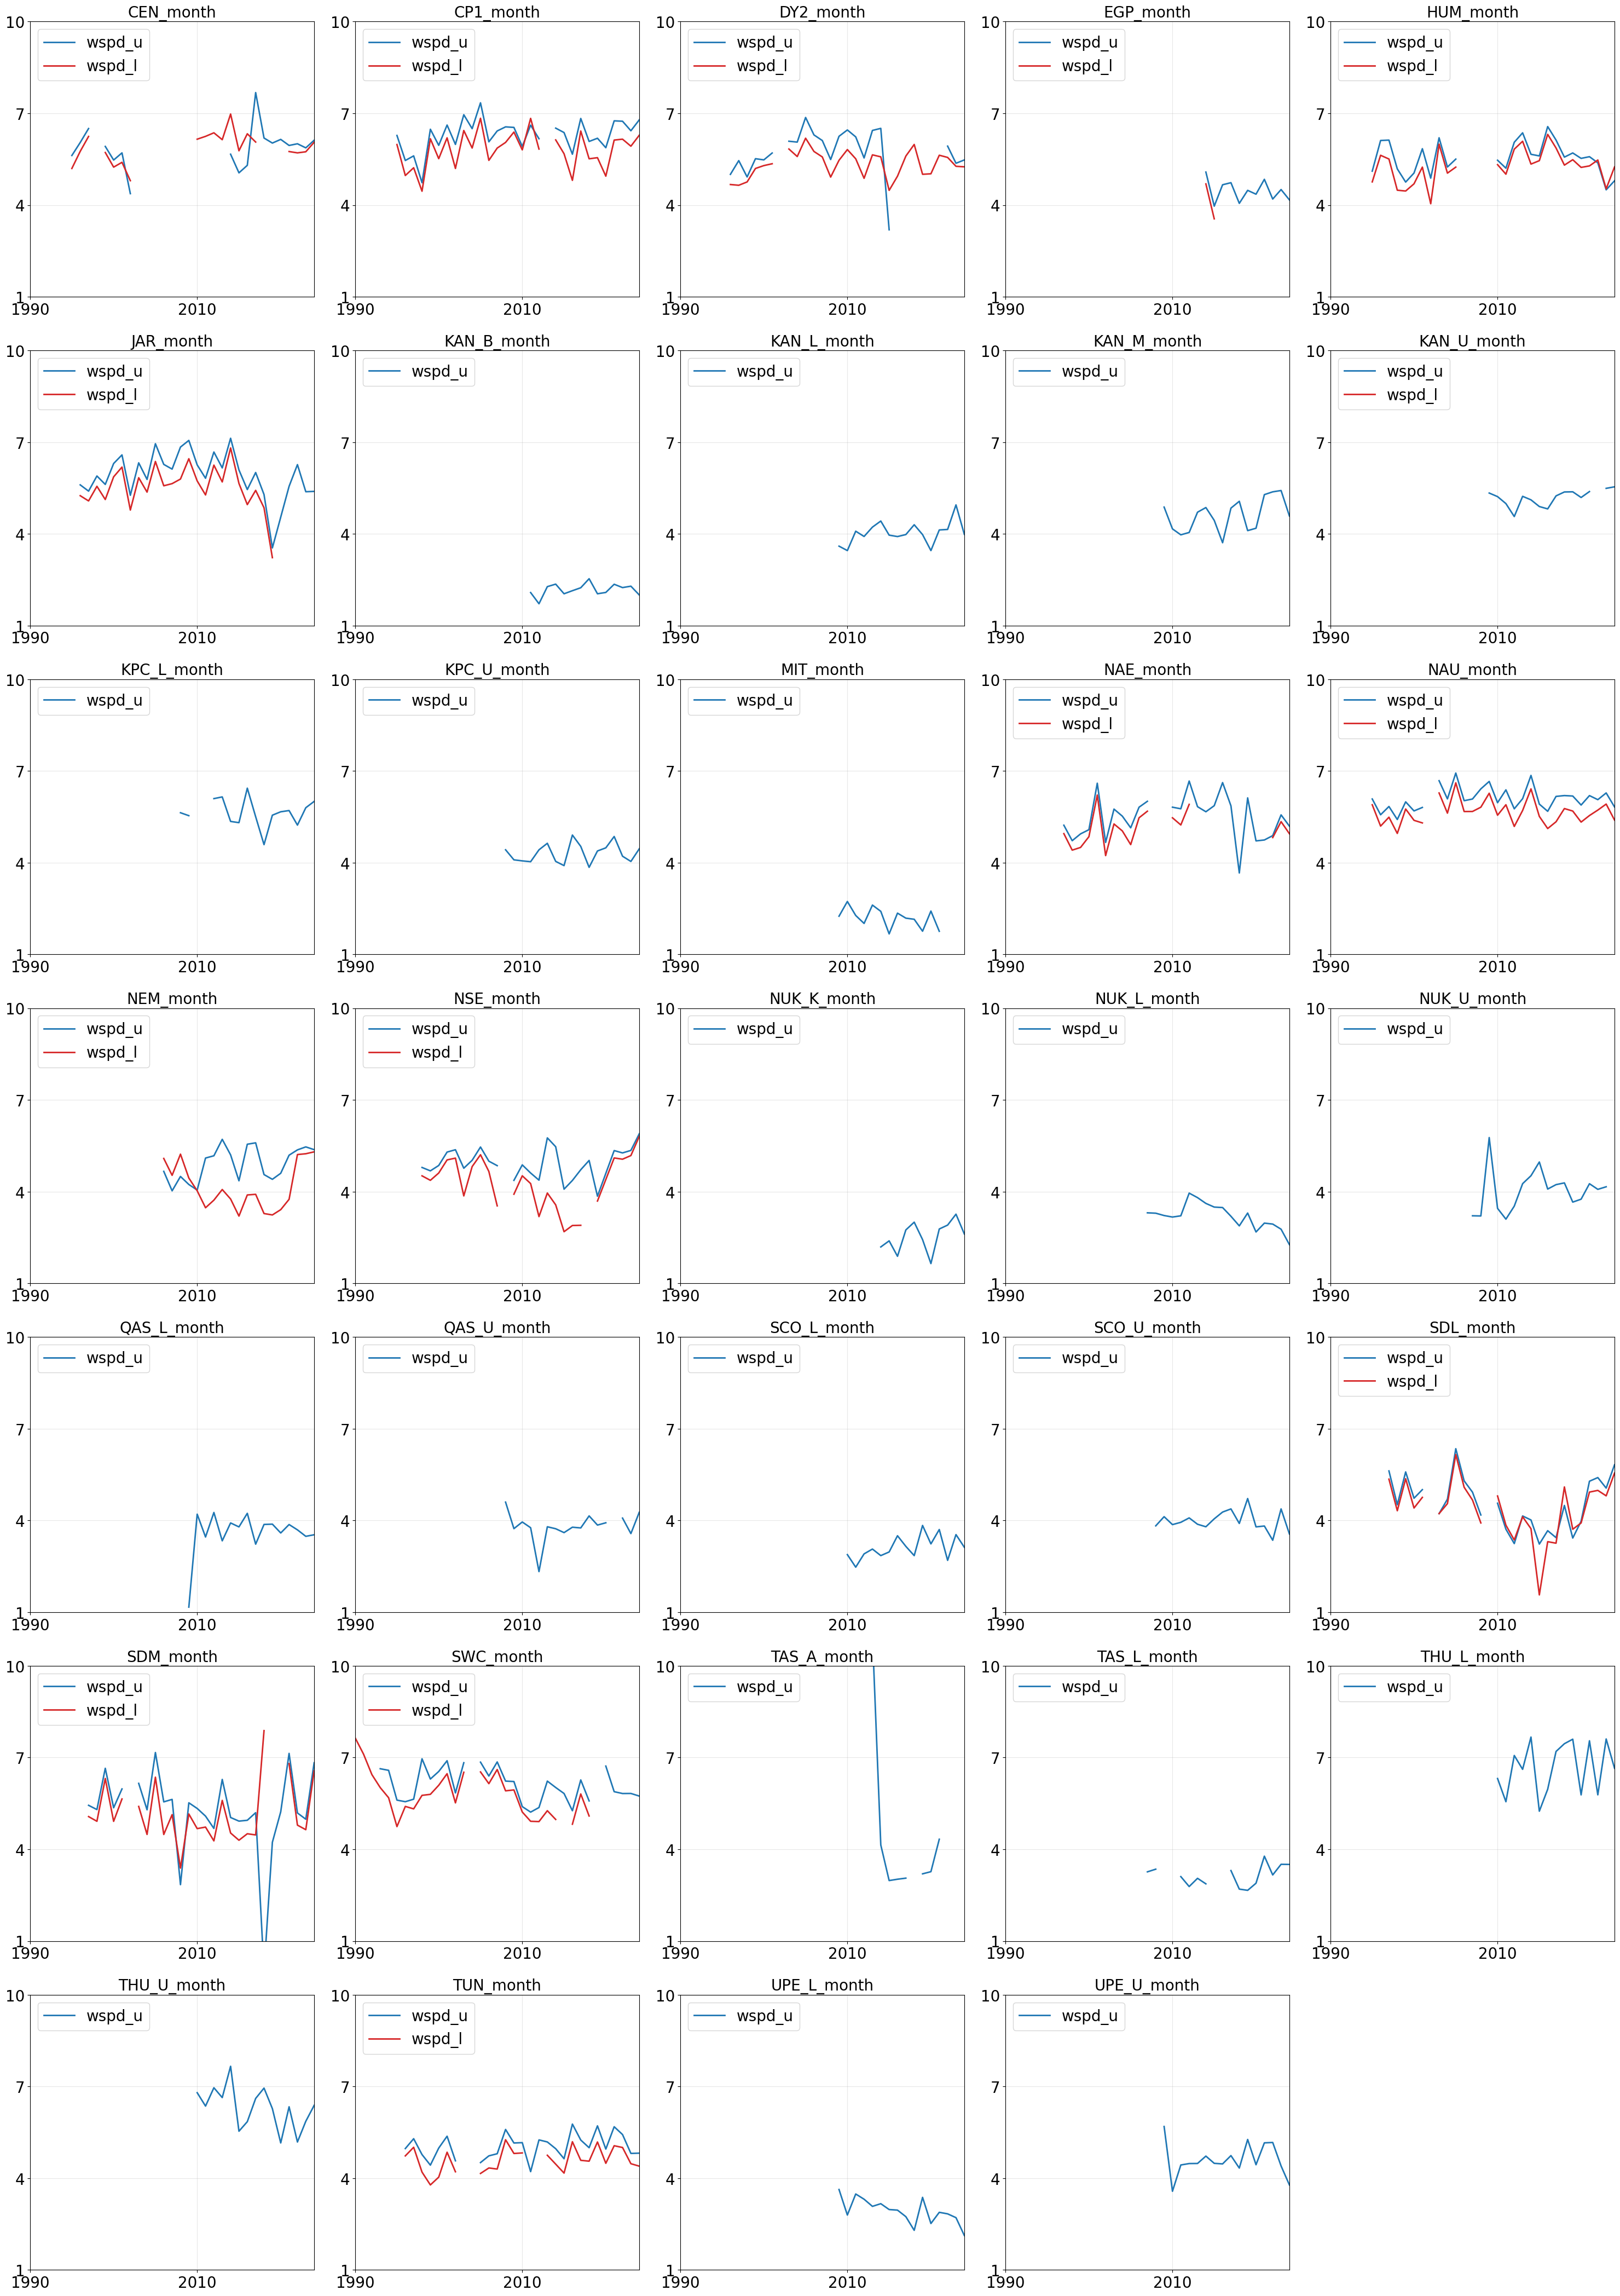


⚠️ 有明显变化趋势的站点（|斜率| ≥ 0.02 m/s/yr）：
 ➤ TAS_A_month



In [ ]:
# -*- coding: utf-8 -*-===================站点====月平均风速=======================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# ===================== 参数 =====================
BASE_DIR = r"C:\Users\greenlandProject\ERA5LAND\dataverse_files\month"

START_YEAR = 1990
END_YEAR   = 2024

TREND_THRESHOLD = 0.1  # 斜率变化阈值 (m/s 每年)

# 全局大字号
plt.rcParams["font.size"] = 20
plt.rcParams["axes.titlesize"] = 20
plt.rcParams["axes.labelsize"] = 20
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["legend.fontsize"] = 20

COLORS = {"wspd_u": "tab:blue", "wspd_l": "tab:red"}

# ===================== 扫描文件 =====================
files = [f for f in os.listdir(BASE_DIR) if f.endswith(".csv") and "month" in f.lower()]
files = sorted(files)

# ===================== 画布布局 =====================
n = len(files)
cols = 5
rows = (n // cols) + (1 if n % cols else 0)

fig, axes = plt.subplots(rows, cols, figsize=(30, 6 * rows))
axes = axes.flatten()

trend_stations = []  # 存储趋势明显的站点名称
plot_idx = 0

# ===================== 趋势函数 =====================
def calc_trend(series):
    """对单站点单变量 series 做线性趋势，自动 dropna()，出错返回 None"""
    s = series.dropna()
    if len(s) < 5:  # 少于 5 年不计算趋势
        return None
    
    x = np.array(s.index).reshape(-1, 1)
    y = s.values.reshape(-1, 1)
    
    try:
        model = LinearRegression().fit(x, y)
        return model.coef_[0][0]  # slope (m/s per year)
    except:
        return None

# ===================== 主循环 =====================
for file in files:
    path = os.path.join(BASE_DIR, file)
    df = pd.read_csv(path)
    station = file.replace(".csv", "")

    # 时间列检查
    if "time" not in df.columns:
        continue

    df["time"] = pd.to_datetime(df["time"], errors="coerce")
    df = df.dropna(subset=["time"])

    df = df[(df["time"].dt.year >= START_YEAR) & (df["time"].dt.year <= END_YEAR)]
    if df.empty:
        continue

    df["year"] = df["time"].dt.year
    df["month"] = df["time"].dt.month

    # 只取 JJA
    df_jja = df[df["month"].isin([6, 7, 8])]
    if df_jja.empty:
        continue

    # 聚合年均
    series_u = df_jja.groupby("year")["wspd_u"].mean() if "wspd_u" in df_jja.columns else None
    series_l = df_jja.groupby("year")["wspd_l"].mean() if "wspd_l" in df_jja.columns else None

    # wspd_u/l 都没有 → 跳过
    if (series_u is None) and (series_l is None):
        continue

    # 有效年份过滤（≥10 年）
    valid_years = set()
    if series_u is not None: valid_years |= set(series_u.index)
    if series_l is not None: valid_years |= set(series_l.index)

    if len(valid_years) < 10:
        continue

    # ===================== 趋势计算 =====================
    slope = None

    if series_u is not None:
        slope = calc_trend(series_u)

    if slope is None and series_l is not None:
        slope = calc_trend(series_l)

    trend_flag = False
    if slope is not None and abs(slope) >= TREND_THRESHOLD:
        trend_flag = True
        trend_stations.append(station)

    # ===================== 开始画图 =====================
    ax = axes[plot_idx]

    if series_u is not None:
        ax.plot(series_u.index, series_u.values, label="wspd_u",
                color=COLORS["wspd_u"], linewidth=2)

    if series_l is not None:
        ax.plot(series_l.index, series_l.values, label="wspd_l",
                color=COLORS["wspd_l"], linewidth=2)

    ax.set_title(station)
    ax.grid(alpha=0.3)

    # ---- x 轴 ----
    ax.set_xticks([1990, 2010])
    ax.set_xlim(1990, 2024)

    # ---- y 轴统一 ----
    ax.set_ylim(1, 10)
    ax.set_yticks([1, 4, 7, 10])

    ax.legend(loc="upper left")

    plot_idx += 1

# ==== 删除多余空子图 ====
for j in range(plot_idx, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# ===================== 输出明显趋势站点 =====================
print("\n==============================")
print("⚠️ 有明显变化趋势的站点（|斜率| ≥ 0.02 m/s/yr）：")
for s in trend_stations:
    print(" ➤", s)
print("==============================\n")


In [ ]:
# -*- coding: utf-8 -*-===================看站点日降雪得，缺测太多没用==============================
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ===================== 0) 路径设置 =====================
# 你给的是某个站点文件路径，这里取它的目录并扫描所有 csv
ONE_FILE = r"C:\Users\greenlandProject\ERA5LAND\dataverse_files\day\CEN_day.csv"
DATA_DIR = os.path.dirname(ONE_FILE)
OUT_DIR = os.path.join(DATA_DIR, "plots_JJA_1990_2025")
os.makedirs(OUT_DIR, exist_ok=True)

# 年份范围
Y0, Y1 = 1990, 2025

# JJA 92天：6月(30)+7月(31)+8月(31)=92
JJA_MONTHS = (6, 7, 8)

# ===================== 1) 工具函数 =====================
def find_time_col(df: pd.DataFrame) -> str:
    """尽量自动识别时间列"""
    candidates = ["date", "time", "datetime", "valid_time", "validtime", "day", "DATE", "Time"]
    for c in candidates:
        if c in df.columns:
            return c
    # 兜底：找任何看起来像日期的列
    for c in df.columns:
        if "date" in c.lower() or "time" in c.lower():
            return c
    raise ValueError("找不到时间列（常见列名 date/time/valid_time）。请检查CSV表头。")

def ensure_celsius(series: pd.Series) -> pd.Series:
    """
    若 t_u 看起来是 Kelvin(大多在 200-320)，转为 ℃；
    否则假定已经是 ℃
    """
    s = pd.to_numeric(series, errors="coerce")
    med = np.nanmedian(s.values)
    if np.isfinite(med) and med > 120:  # 极粗略判断：>120基本可认为K
        return s - 273.15
    return s

def station_name_from_file(fp: str) -> str:
    base = os.path.basename(fp)
    # 例如 CEN_day.csv -> CEN
    name = base.replace(".csv", "")
    name = name.replace("_day", "")
    return name

def build_jja_grid(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    返回：
      Tgrid: index=year, columns=1..92, 值=温度(℃)
      Pgrid: index=year, columns=1..92, 值=precip_u_cor
      Type : index=year, columns=1..92, 值=0(无降水)/1(雨)/2(雪)/NaN(缺测)
    """
    time_col = find_time_col(df)

    # 统一列名检查
    need_cols = ["t_u", "precip_u_cor"]
    missing = [c for c in need_cols if c not in df.columns]
    if missing:
        raise ValueError(f"缺少列：{missing}. 现有列：{list(df.columns)[:30]}...")

    d = df[[time_col, "t_u", "precip_u_cor"]].copy()
    d[time_col] = pd.to_datetime(d[time_col], errors="coerce")
    d = d.dropna(subset=[time_col])
    d = d.sort_values(time_col)

    d["year"] = d[time_col].dt.year
    d["month"] = d[time_col].dt.month
    d["day"] = d[time_col].dt.day

    # 筛选年份 + JJA
    d = d[(d["year"] >= Y0) & (d["year"] <= Y1) & (d["month"].isin(JJA_MONTHS))].copy()

    # 若同一天多条记录（理论上day数据应只有1条），取日均/日和
    d["t_c"] = ensure_celsius(d["t_u"])
    d["p"] = pd.to_numeric(d["precip_u_cor"], errors="coerce")

    d["date"] = d[time_col].dt.floor("D")
    g = d.groupby("date", as_index=False).agg(
        year=("year", "first"),
        month=("month", "first"),
        day=("day", "first"),
        t_c=("t_c", "mean"),
        p=("p", "sum"),
    )

    # 计算 JJA day index: 6月1日=1 ... 8月31日=92
    # 先算每条记录在其年的JJA起点的天序
    g["jja_day"] = (
        (pd.to_datetime(dict(year=g["year"], month=g["month"], day=g["day"])) -
         pd.to_datetime(dict(year=g["year"], month=6, day=1))).dt.days + 1
    )

    # 只保留 1..92
    g = g[(g["jja_day"] >= 1) & (g["jja_day"] <= 92)].copy()

    years = np.arange(Y0, Y1 + 1)
    cols = np.arange(1, 93)

    # 构造完整网格（缺测留 NaN）
    Tgrid = pd.DataFrame(index=years, columns=cols, dtype=float)
    Pgrid = pd.DataFrame(index=years, columns=cols, dtype=float)
    Type  = pd.DataFrame(index=years, columns=cols, dtype=float)

    for _, r in g.iterrows():
        y = int(r["year"])
        c = int(r["jja_day"])
        Tgrid.loc[y, c] = r["t_c"]
        Pgrid.loc[y, c] = r["p"]

        if pd.notna(r["p"]) and r["p"] > 0:
            # 有降水：用温度判雨雪
            if pd.notna(r["t_c"]) and r["t_c"] <= 0:
                Type.loc[y, c] = 2  # snow
            elif pd.notna(r["t_c"]):
                Type.loc[y, c] = 1  # rain
            else:
                # 有降水但温度缺测：先标记为 0.5，后面用灰点表示
                Type.loc[y, c] = 0.5

    return Tgrid, Pgrid, Type

def plot_station(Tgrid: pd.DataFrame, Type: pd.DataFrame, station: str, out_png: str):
    """
    温度热图 + 降水叠加：
      - 雨：圆点
      - 雪：三角
      - 有降水但温度缺测：灰色 x
    """
    years = Tgrid.index.values
    nY = len(years)

    Z = Tgrid.values.astype(float)  # nY x 92

    plt.figure(figsize=(14, 6))
    ax = plt.gca()

    # 温度底图（缺测会透明）
    cmap = plt.get_cmap("coolwarm").copy()
    cmap.set_bad(alpha=0.0)  # 缺测透明
    im = ax.imshow(
        np.ma.masked_invalid(Z),
        aspect="auto",
        origin="lower",
        interpolation="none",
    )

    # y 轴为年份
    ax.set_yticks(np.arange(0, nY, 5))
    ax.set_yticklabels(years[::5])
    ax.set_ylabel("Year")

    # x 轴为 JJA 天序，标注每月起点
    ax.set_xlabel("JJA day (Jun 1 = 1 ... Aug 31 = 92)")
    ax.set_xticks([1-1, 31-1, 62-1, 92-1])  # imshow列从0开始
    ax.set_xticklabels(["Jun 1", "Jul 1", "Aug 1", "Aug 31"])

    ax.set_title(f"{station} | t_u (°C) with precipitation days (1990–2025, JJA)")

    # 叠加降水类型
    Ty = Type.values.astype(float)

    # rain (1)
    ry, rx = np.where(Ty == 1)
    ax.scatter(rx, ry, s=10, marker="o", linewidths=0, label="Rain (precip>0 & T>0°C)")

    # snow (2)
    sy, sx = np.where(Ty == 2)
    ax.scatter(sx, sy, s=14, marker="^", linewidths=0, label="Snow (precip>0 & T≤0°C)")

    # precip but temp missing (0.5)
    my, mx = np.where(Ty == 0.5)
    ax.scatter(mx, my, s=16, marker="x", label="Precip>0 but T missing")

    # 色标
    cbar = plt.colorbar(im, ax=ax, pad=0.01)
    cbar.set_label("Temperature (°C)")

    ax.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.savefig(out_png, dpi=200)
    plt.close()

# ===================== 2) 主流程：扫描并绘图 =====================
csv_files = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
print(f"Found {len(csv_files)} CSV files under: {DATA_DIR}")

ok, fail = 0, 0
for fp in csv_files:
    station = station_name_from_file(fp)
    try:
        df = pd.read_csv(fp)
        Tgrid, Pgrid, Type = build_jja_grid(df)

        out_png = os.path.join(OUT_DIR, f"{station}_JJA_T_and_Precip_1990_2025.png")
        plot_station(Tgrid, Type, station, out_png)

        ok += 1
        print(f"[OK] {station}: {os.path.basename(fp)} -> {os.path.basename(out_png)}")
    except Exception as e:
        fail += 1
        print(f"[FAIL] {station}: {os.path.basename(fp)} | {repr(e)}")

print(f"Done. OK={ok}, FAIL={fail}. Output dir: {OUT_DIR}")


Found 51 CSV files under: C:\Users\greenlandProject\ERA5LAND\dataverse_files\day
[OK] CEN: CEN_day.csv -> CEN_JJA_T_and_Precip_1990_2025.png
[OK] CP1: CP1_day.csv -> CP1_JJA_T_and_Precip_1990_2025.png
[OK] DY2: DY2_day.csv -> DY2_JJA_T_and_Precip_1990_2025.png
[OK] EGP: EGP_day.csv -> EGP_JJA_T_and_Precip_1990_2025.png
[FAIL] FRE: FRE_day.csv | ValueError("缺少列：['precip_u_cor']. 现有列：['time', 'p_u', 't_u', 'rh_u', 'rh_u_wrt_ice_or_water', 'qh_u', 'wspd_u', 'wdir_u', 'wspd_x_u', 'wspd_y_u', 'dsr', 'dsr_cor', 'usr', 'usr_cor', 'albedo', 'dlr', 'ulr', 'cc', 't_surf', 'dlhf_u', 'dshf_u', 'z_boom_u', 'z_stake', 'z_pt', 'z_pt_cor', 'z_surf_combined', 'z_ice_surf', 'snow_height', 't_i_1', 't_i_2']...")
[OK] HUM: HUM_day.csv -> HUM_JJA_T_and_Precip_1990_2025.png
[OK] JAR: JAR_day.csv -> JAR_JJA_T_and_Precip_1990_2025.png
[FAIL] KAN_B: KAN_B_day.csv | ValueError("缺少列：['precip_u_cor']. 现有列：['time', 'p_u', 't_u', 'rh_u', 'rh_u_wrt_ice_or_water', 'qh_u', 'wspd_u', 'wdir_u', 'wspd_x_u', 'wspd_y_u', '

<xarray.Dataset> Size: 194MB
Dimensions:     (valid_time: 92, latitude: 251, longitude: 701)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 736B 2025-06-01 ... 2025-08-31
  * latitude    (latitude) float64 2kB 85.0 84.9 84.8 84.7 ... 60.2 60.1 60.0
  * longitude   (longitude) float64 6kB -80.0 -79.9 -79.8 ... -10.2 -10.1 -10.0
    expver      (valid_time) <U4 1kB ...
Data variables:
    sf          (valid_time, latitude, longitude) float32 65MB ...
    tp          (valid_time, latitude, longitude) float32 65MB ...
    t2m         (valid_time, latitude, longitude) float32 65MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-02-03T12:08 GRIB to CDM+CF via cfgrib-0.9.1...


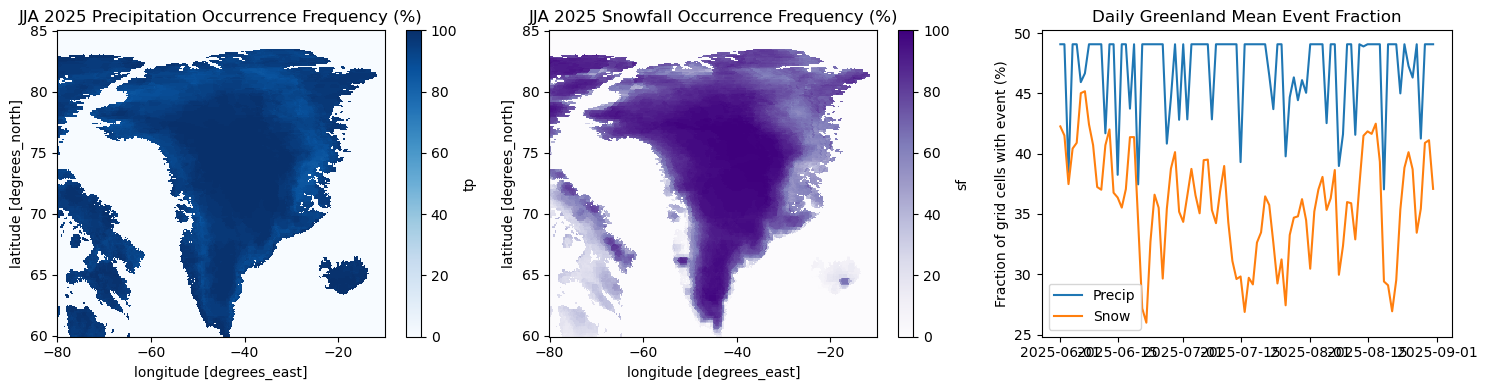

In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. 打开数据
# =========================
path = r"C:\Users\11823\Downloads\2025sftp.nc"
ds = xr.open_dataset(path)

print(ds)

# -------------------------
# 自动找时间维
# -------------------------
time_dim = "time"
if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})

# -------------------------
# 变量名（按你文件实际情况可能要改）
# -------------------------
TP_VAR = "tp"      # total precipitation
SNOW_VAR = "sf"   # snowfall (如果不是sf，用print(ds.data_vars)查看)

tp = ds[TP_VAR]
snow = ds[SNOW_VAR]

# =========================
# 2. 只取 JJA
# =========================
jja = ds.sel(time=ds.time.dt.month.isin([6,7,8]))
tp = jja[TP_VAR]
snow = jja[SNOW_VAR]

# =========================
# 3. 当日是否有降水 (0/1)
# =========================
tp_event   = (tp > 0)
snow_event = (snow > 0)

# =========================
# 4. 每个格点：发生频率
# =========================
tp_freq   = tp_event.mean("time") * 100
snow_freq = snow_event.mean("time") * 100

# =========================
# 5. 全区平均：每天有降水格点比例
# =========================
daily_tp_ratio = tp_event.mean(dim=("latitude","longitude")) * 100
daily_snow_ratio = snow_event.mean(dim=("latitude","longitude")) * 100

# =========================
# 6. 作图
# =========================
fig, axes = plt.subplots(1,3, figsize=(15,4))

# (a) 降水频率
tp_freq.plot(ax=axes[0], cmap="Blues")
axes[0].set_title("JJA 2025 Precipitation Occurrence Frequency (%)")

# (b) 降雪频率
snow_freq.plot(ax=axes[1], cmap="Purples")
axes[1].set_title("JJA 2025 Snowfall Occurrence Frequency (%)")

# (c) 时间序列
axes[2].plot(daily_tp_ratio.time, daily_tp_ratio, label="Precip")
axes[2].plot(daily_snow_ratio.time, daily_snow_ratio, label="Snow")
axes[2].set_ylabel("Fraction of grid cells with event (%)")
axes[2].set_title("Daily Greenland Mean Event Fraction")
axes[2].legend()

plt.tight_layout()
plt.show()


=== 2025 JJA (Jun–Aug) Max consecutive no-snow days (binned) ===
Valid grid cells: 86345
Domain max no-snow run: 92 days
Fractions (unweighted, by grid-cell count):
   0 :   3.83%
   1 :   8.25%
   2 :  17.02%
   3 :  11.64%
   4 :   7.93%
   5 :   8.69%
   6 :   6.25%
   7 :  11.44%
  10 :   5.59%
  15 :   3.07%
  20 :   6.41%
  30 :   9.87%
Note: White areas on the map = missing data (NaN), not classified.
      Gray (0) = JJA期间每天都有雪（最长无雪=0天）。


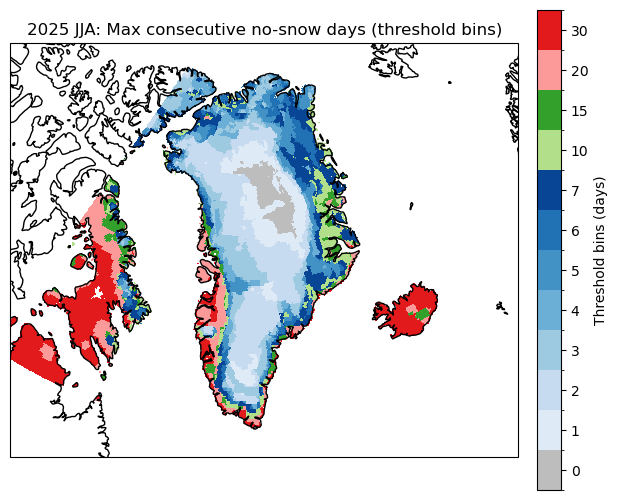

In [6]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.colors import ListedColormap, BoundaryNorm

# =========================
# 0) 配置
# =========================
path = r"C:\Users\11823\Downloads\2025sftp.nc"
SNOW_VAR = "sf"  # 降雪变量名（如报 KeyError：先 print(ds.data_vars) 再改）

# 连续无雪阈值（按你要求显示这些“档位”）
THRESH_LABELS = [0, 1, 2, 3, 4, 5, 6, 7, 10, 15, 20, 30]  # 显示在色标上
# 对应的“>=阈值”分档边界（用于分类编码）
THRESH = [1, 2, 3, 4, 5, 6, 7, 10, 15, 20, 30]

# 北极投影：让格陵兰更“正”的观感（0°经线朝上 + 视窗聚焦格陵兰）
proj = ccrs.NorthPolarStereo(central_longitude=-45)
pc = ccrs.PlateCarree()
extent = [-75, -10, 58, 85]  # Greenland box

# 颜色（12档：0 + 其余11档）
colors = [
    "#bdbdbd",  # 0
    "#deebf7",  # 1
    "#c6dbef",  # 2
    "#9ecae1",  # 3
    "#6baed6",  # 4
    "#4292c6",  # 5
    "#2171b5",  # 6
    "#084594",  # 7
    "#b2df8a",  # 10
    "#33a02c",  # 15
    "#fb9a99",  # 20
    "#e31a1c",  # 30
]
cmap = ListedColormap(colors)
# 类别编码是 0..11
bounds = np.arange(-0.5, 11.6, 1.0)
norm = BoundaryNorm(bounds, cmap.N)

# =========================
# 1) 读取数据
# =========================
ds = xr.open_dataset(path)

# 统一时间维
if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})

# 取 2025 JJA
ds_jja = ds.sel(time=ds.time.dt.month.isin([6, 7, 8]))
snow = ds_jja[SNOW_VAR]

# 经纬度名兼容
lat_name = "latitude" if "latitude" in ds_jja.coords else ("lat" if "lat" in ds_jja.coords else None)
lon_name = "longitude" if "longitude" in ds_jja.coords else ("lon" if "lon" in ds_jja.coords else None)
if lat_name is None or lon_name is None:
    raise ValueError("找不到 latitude/longitude 或 lat/lon 坐标，请先 print(ds.coords) 查看。")

lat = ds_jja[lat_name]
lon = ds_jja[lon_name]

# 若经纬度是1D，转2D（更稳）
if lat.ndim == 1 and lon.ndim == 1:
    lon2d, lat2d = np.meshgrid(lon.values, lat.values)
else:
    lon2d, lat2d = lon.values, lat.values

# =========================
# 2) 连续无雪：最长连续天数
# =========================
# 有雪日（snow>0）
snow_event = (snow > 0)

# 1=无雪, 0=有雪；缺测会保留为 False/True? -> 这里用 where 保证缺测维持 NaN
nosnow = xr.where(np.isfinite(snow), (~snow_event).astype(np.int8), np.nan)

def max_consecutive_ones(arr1d):
    # arr1d: 1D array with values 0/1 or nan
    if np.all(np.isnan(arr1d)):
        return np.nan
    maxlen = 0
    curlen = 0
    for v in arr1d:
        if np.isnan(v):
            # 遇到缺测：直接断开
            curlen = 0
            continue
        if int(v) == 1:
            curlen += 1
            if curlen > maxlen:
                maxlen = curlen
        else:
            curlen = 0
    return maxlen

max_nosnow = xr.apply_ufunc(
    max_consecutive_ones,
    nosnow,
    input_core_dims=[["time"]],
    vectorize=True,
    output_dtypes=[np.float32],
)

# =========================
# 3) 按阈值分类：0,1,2,3,4,5,6,7,10,15,20,30
#    编码 0..11；NaN=白色（缺测/无数据）
# =========================
cat = xr.full_like(max_nosnow, fill_value=np.nan, dtype=np.float32)

# 先把 max==0 的格点标为 0（注意 max_nosnow 可能是浮点）
cat = xr.where(np.isfinite(max_nosnow) & (max_nosnow == 0), 0, cat)

# 逐级覆盖（>=阈值就升级到更高编码）
# 编码映射：1->1,2->2,3->3,4->4,5->5,6->6,7->7,10->8,15->9,20->10,30->11
code_map = {1:1, 2:2, 3:3, 4:4, 5:5, 6:6, 7:7, 10:8, 15:9, 20:10, 30:11}
for t in THRESH:
    cat = xr.where(np.isfinite(max_nosnow) & (max_nosnow >= t), code_map[t], cat)

# =========================
# 4) Print 统计（未加权：按格点数）
# =========================
v = cat.values
valid = np.isfinite(v)
total = valid.sum()

print("=== 2025 JJA (Jun–Aug) Max consecutive no-snow days (binned) ===")
print(f"Valid grid cells: {int(total)}")
print(f"Domain max no-snow run: {int(np.nanmax(max_nosnow.values))} days")
print("Fractions (unweighted, by grid-cell count):")

for code, lab in enumerate(THRESH_LABELS):
    frac = 100.0 * np.sum(valid & (v == code)) / total if total else np.nan
    print(f"  {str(lab).rjust(2)} : {frac:6.2f}%")

print("Note: White areas on the map = missing data (NaN), not classified.\n"
      "      Gray (0) = JJA期间每天都有雪（最长无雪=0天）。")

# =========================
# 5) Plot（北极投影，聚焦格陵兰）
# =========================
fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=proj)
ax.coastlines()
ax.set_extent(extent, crs=pc)

im = ax.pcolormesh(
    lon2d, lat2d, cat.values,
    transform=pc,
    cmap=cmap, norm=norm,
    shading="auto"
)

cbar = plt.colorbar(im, ax=ax, shrink=0.78, pad=0.03)
cbar.set_ticks(np.arange(len(THRESH_LABELS)))
cbar.set_ticklabels([str(x) for x in THRESH_LABELS])
cbar.set_label("Threshold bins (days)")

ax.set_title("2025 JJA: Max consecutive no-snow days (threshold bins)")
plt.show()


In [11]:
# -*- coding: utf-8 -*-
import os
import glob
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.colors import ListedColormap, BoundaryNorm

# =========================
# 0) 配置
# =========================
# 目录里包含 ERA5L_Daily_Total_1950.nc ... 2024.nc
IN_FILE = r"C:\Users\11823\ERA5_Land_Daily\ERA5L_Daily_Total_1950.nc"
DATA_DIR = os.path.dirname(IN_FILE)

# 输出同目录
OUT_DIR = DATA_DIR

# 阈值标签（色标显示）
THRESH_LABELS = [0, 1, 2, 3, 4, 5, 6, 7, 10, 15, 20, 30]
THRESH = [1, 2, 3, 4, 5, 6, 7, 10, 15, 20, 30]
code_map = {1:1, 2:2, 3:3, 4:4, 5:5, 6:6, 7:7, 10:8, 15:9, 20:10, 30:11}

# 北极投影 + Greenland视窗
proj = ccrs.NorthPolarStereo(central_longitude=-45)
pc = ccrs.PlateCarree()
extent = [-75, -10, 58, 85]  # Greenland box

# 颜色（12档：0 + 其余11档）
colors = [
    "#bdbdbd",  # 0
    "#deebf7",  # 1
    "#c6dbef",  # 2
    "#9ecae1",  # 3
    "#6baed6",  # 4
    "#4292c6",  # 5
    "#2171b5",  # 6
    "#084594",  # 7
    "#b2df8a",  # 10
    "#33a02c",  # 15
    "#fb9a99",  # 20
    "#e31a1c",  # 30
]
cmap = ListedColormap(colors)
bounds = np.arange(-0.5, 11.6, 1.0)  # 类别编码 0..11
norm = BoundaryNorm(bounds, cmap.N)

# 降雪变量候选名（按需自行加）
SNOW_CANDIDATES = ["sf", "snowfall", "snow", "snowf", "sft", "snowfall_amount"]

# =========================
# 1) 工具函数
# =========================
def pick_snow_var(ds: xr.Dataset) -> str:
    """自动挑一个最像“降雪/降雪量”的变量名"""
    vars_lower = {v.lower(): v for v in ds.data_vars}
    for c in SNOW_CANDIDATES:
        if c.lower() in vars_lower:
            return vars_lower[c.lower()]
    # 再兜底：包含 snow/sf 字样
    for v in ds.data_vars:
        vl = v.lower()
        if ("snow" in vl) or (vl == "sf") or (vl.endswith("_sf")):
            return v
    raise KeyError(
        f"找不到降雪变量。请在文件里确认降雪变量名（当前 data_vars={list(ds.data_vars)[:30]} ...），"
        f"然后把 SNOW_CANDIDATES 或直接 SNOW_VAR 改成正确名字。"
    )

def get_lat_lon(ds: xr.Dataset):
    """兼容 latitude/longitude 或 lat/lon；返回( lat, lon, lat_name, lon_name )"""
    if "latitude" in ds.coords:
        lat_name = "latitude"
    elif "lat" in ds.coords:
        lat_name = "lat"
    else:
        raise KeyError("找不到纬度坐标(latitude/lat)。")

    if "longitude" in ds.coords:
        lon_name = "longitude"
    elif "lon" in ds.coords:
        lon_name = "lon"
    else:
        raise KeyError("找不到经度坐标(longitude/lon)。")

    return ds[lat_name], ds[lon_name], lat_name, lon_name

def unify_time_dim(ds: xr.Dataset) -> xr.Dataset:
    if "valid_time" in ds.dims and "time" not in ds.dims:
        ds = ds.rename({"valid_time": "time"})
    return ds

def max_consecutive_ones(arr1d):
    """arr1d: 1D array of 0/1 or nan; return max run of 1s"""
    if np.all(np.isnan(arr1d)):
        return np.nan
    maxlen = 0
    curlen = 0
    for v in arr1d:
        if np.isnan(v):
            curlen = 0
            continue
        if int(v) == 1:
            curlen += 1
            if curlen > maxlen:
                maxlen = curlen
        else:
            curlen = 0
    return maxlen

def compute_cat_for_file(nc_path: str):
    """读取单个nc -> 计算JJA最长连续无雪 -> 分类cat(0..11, NaN缺测) + lon2d/lat2d"""
    ds = xr.open_dataset(nc_path)
    ds = unify_time_dim(ds)

    # 取JJA
    if "time" not in ds.dims:
        raise KeyError("找不到时间维(time/valid_time)。")
    ds_jja = ds.sel(time=ds["time"].dt.month.isin([6, 7, 8]))

    # 变量
    snow_var = pick_snow_var(ds_jja)
    snow = ds_jja[snow_var]

    # 经纬度
    lat, lon, lat_name, lon_name = get_lat_lon(ds_jja)
    if lat.ndim == 1 and lon.ndim == 1:
        lon2d, lat2d = np.meshgrid(lon.values, lat.values)
    else:
        lon2d, lat2d = lon.values, lat.values

    # 有雪日：snow > 0
    snow_event = (snow > 0)
    nosnow = xr.where(np.isfinite(snow), (~snow_event).astype(np.int8), np.nan)

    max_nosnow = xr.apply_ufunc(
        max_consecutive_ones,
        nosnow,
        input_core_dims=[["time"]],
        vectorize=True,
        output_dtypes=[np.float32],
    )

    # 分类：0..11
    cat = xr.full_like(max_nosnow, fill_value=np.nan, dtype=np.float32)
    cat = xr.where(np.isfinite(max_nosnow) & (max_nosnow == 0), 0, cat)
    for t in THRESH:
        cat = xr.where(np.isfinite(max_nosnow) & (max_nosnow >= t), code_map[t], cat)

    return cat.values, lon2d, lat2d, snow_var

def save_map(cat, lon2d, lat2d, year, out_png):
    fig = plt.figure(figsize=(8, 8))
    ax = plt.axes(projection=proj)
    ax.coastlines()
    ax.set_extent(extent, crs=pc)

    im = ax.pcolormesh(
        lon2d, lat2d, cat,
        transform=pc,
        cmap=cmap, norm=norm,
        shading="auto",
    )

    cbar = plt.colorbar(im, ax=ax, shrink=0.78, pad=0.03)
    cbar.set_ticks(np.arange(len(THRESH_LABELS)))
    cbar.set_ticklabels([str(x) for x in THRESH_LABELS])
    cbar.set_label("Threshold bins (days)")

    ax.set_title(f"{year} JJA: Max consecutive no-snow days (threshold bins)")
    plt.tight_layout()
    plt.savefig(out_png, dpi=200)
    plt.close(fig)

# =========================
# 2) 批量处理：1950-2024（共75张）
# =========================
# 匹配同目录下所有 ERA5L_Daily_Total_*.nc
nc_files = sorted(glob.glob(os.path.join(DATA_DIR, "ERA5L_Daily_Total_*.nc")))

# 若你文件命名不同，把上面 pattern 改一下即可
for fp in nc_files:
    base = os.path.basename(fp)
    # 从文件名里抓年份（假设最后的_YYYY.nc）
    try:
        year = int(os.path.splitext(base)[0].split("_")[-1])
    except Exception:
        # 抓不到就跳过
        continue

    # 计算分类并保存
    cat, lon2d, lat2d, snow_var_used = compute_cat_for_file(fp)
    out_png = os.path.join(OUT_DIR, f"NoSnowMaxRun_Bins_{year}.png")
    save_map(cat, lon2d, lat2d, year, out_png)


然后对裁剪后的75个nc文件计算，输出csv，每年一行，依次对应不同天数占比

In [14]:
# -*- coding: utf-8 -*-
import os
import glob
import re
import numpy as np
import pandas as pd
import xarray as xr

# =========================
# 配置
# =========================
IN_DIR  = r"C:\Users\11823\ERA5_Land_Daily\clipped"
OUT_CSV = os.path.join(IN_DIR, "NoSnowMaxRun_Bins_1950_2024.csv")

# 色标/档位（与你之前一致）
THRESH_LABELS = [0, 1, 2, 3, 4, 5, 6, 7, 10, 15, 20, 30]
THRESH = [1, 2, 3, 4, 5, 6, 7, 10, 15, 20, 30]
code_map = {1:1, 2:2, 3:3, 4:4, 5:5, 6:6, 7:7, 10:8, 15:9, 20:10, 30:11}

# 降雪变量候选名（按需自行加）
SNOW_CANDIDATES = ["sf", "snowfall", "snow", "snowf", "sft", "snowfall_amount"]

# =========================
# 工具函数
# =========================
def unify_time_dim(ds: xr.Dataset) -> xr.Dataset:
    if "valid_time" in ds.dims and "time" not in ds.dims:
        ds = ds.rename({"valid_time": "time"})
    return ds

def pick_snow_var(ds: xr.Dataset) -> str:
    vars_lower = {v.lower(): v for v in ds.data_vars}
    for c in SNOW_CANDIDATES:
        if c.lower() in vars_lower:
            return vars_lower[c.lower()]
    for v in ds.data_vars:
        vl = v.lower()
        if ("snow" in vl) or (vl == "sf") or (vl.endswith("_sf")):
            return v
    raise KeyError(f"找不到降雪变量。data_vars={list(ds.data_vars)}")

def max_consecutive_ones(arr1d):
    """arr1d: 1D array of 0/1 or nan; return max run of 1s (nan if all nan)"""
    if np.all(np.isnan(arr1d)):
        return np.nan
    maxlen = 0
    curlen = 0
    for v in arr1d:
        if np.isnan(v):
            curlen = 0
            continue
        if int(v) == 1:
            curlen += 1
            if curlen > maxlen:
                maxlen = curlen
        else:
            curlen = 0
    return maxlen

def year_from_filename(fp: str) -> int:
    # 支持 ..._1950_Greenland.nc 或 ..._1950.nc 等
    m = re.search(r"(19[0-9]{2}|20[0-9]{2})", os.path.basename(fp))
    if not m:
        raise ValueError(f"无法从文件名提取年份: {fp}")
    return int(m.group(1))

def compute_year_fractions(nc_path: str):
    ds = xr.open_dataset(nc_path)
    ds = unify_time_dim(ds)

    if "time" not in ds.dims:
        raise KeyError("缺少 time 维度（或 valid_time）。")

    # 取 JJA
    ds_jja = ds.sel(time=ds["time"].dt.month.isin([6, 7, 8]))

    snow_var = pick_snow_var(ds_jja)
    snow = ds_jja[snow_var]

    # 有雪日：snow > 0；nosnow=1(无雪) /0(有雪)，缺测保持 NaN
    snow_event = (snow > 0)
    nosnow = xr.where(np.isfinite(snow), (~snow_event).astype(np.int8), np.nan)

    # 每格点：最长连续无雪天数
    max_nosnow = xr.apply_ufunc(
        max_consecutive_ones,
        nosnow,
        input_core_dims=[["time"]],
        vectorize=True,
        output_dtypes=[np.float32],
    )

    # 分类编码 0..11（NaN缺测不参与统计）
    cat = xr.full_like(max_nosnow, fill_value=np.nan, dtype=np.float32)
    cat = xr.where(np.isfinite(max_nosnow) & (max_nosnow == 0), 0, cat)
    for t in THRESH:
        cat = xr.where(np.isfinite(max_nosnow) & (max_nosnow >= t), code_map[t], cat)

    v = cat.values
    valid = np.isfinite(v)
    total = valid.sum()

    # 输出每档百分比（%）
    fracs = []
    if total == 0:
        fracs = [np.nan] * len(THRESH_LABELS)
    else:
        for code in range(len(THRESH_LABELS)):
            fracs.append(100.0 * np.sum(valid & (v == code)) / total)

    ds.close()
    return fracs, snow_var

# =========================
# 主流程：批量计算 -> CSV
# =========================
nc_files = sorted(glob.glob(os.path.join(IN_DIR, "*.nc")))

rows = []
for fp in nc_files:
    try:
        y = year_from_filename(fp)
        fracs, snow_var_used = compute_year_fractions(fp)

        row = {"year": y}
        # 列名用 d0,d1,d2,...,d30（对应THRESH_LABELS）
        for lab, val in zip(THRESH_LABELS, fracs):
            row[f"d{lab}"] = val
        rows.append(row)

    except Exception as e:
        # 出错也不中断：你想严格就把 try/except 去掉
        print(f"[FAIL] {os.path.basename(fp)} -> {repr(e)}")

# 排序并保存
df = pd.DataFrame(rows).sort_values("year")

# 保留两位小数（可改）
for c in df.columns:
    if c != "year":
        df[c] = df[c].round(2)

df.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
print(f"[OK] Saved: {OUT_CSV}")


[OK] Saved: C:\Users\11823\ERA5_Land_Daily\clipped\NoSnowMaxRun_Bins_1950_2024.csv


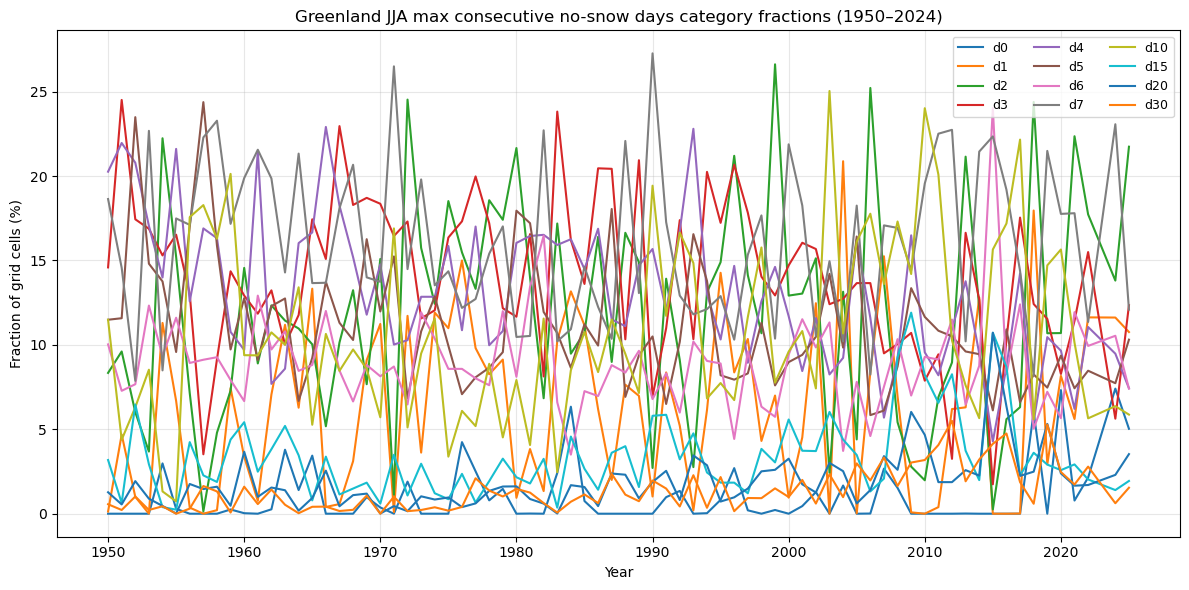

In [15]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 路径
# =========================
CSV_PATH = r"C:\Users\11823\ERA5_Land_Daily\clipped\NoSnowMaxRun_Bins_1950_2024.csv"

# =========================
# 读取数据
# =========================
df = pd.read_csv(CSV_PATH)

years = df["year"]

# 所有百分比列
cols = [c for c in df.columns if c != "year"]

# =========================
# 画图
# =========================
plt.figure(figsize=(12, 6))

for c in cols:
    plt.plot(years, df[c], label=c)

plt.xlabel("Year")
plt.ylabel("Fraction of grid cells (%)")
plt.title("Greenland JJA max consecutive no-snow days category fractions (1950–2024)")

plt.legend(ncol=3, fontsize=9)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [16]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
from scipy.stats import linregress
import pymannkendall as mk

# =========================
# 路径
# =========================
IN_CSV  = r"C:\Users\11823\ERA5_Land_Daily\clipped\NoSnowMaxRun_Bins_1950_2024.csv"
OUT_CSV = r"C:\Users\11823\ERA5_Land_Daily\clipped\NoSnowMaxRun_Trends.csv"

# =========================
# 读取
# =========================
df = pd.read_csv(IN_CSV)

years = df["year"].values
cols = [c for c in df.columns if c != "year"]

records = []

for c in cols:
    y = df[c].values

    # 去掉缺测
    mask = np.isfinite(y)
    x = years[mask]
    v = y[mask]

    if len(v) < 10:
        slope_decade = np.nan
        p_mk = np.nan
    else:
        # 线性趋势
        lr = linregress(x, v)
        slope_year = lr.slope              # % / year
        slope_decade = slope_year * 10.0   # % / decade

        # Mann-Kendall
        mk_res = mk.original_test(v)
        p_mk = mk_res.p

    records.append({
        "category": c,
        "trend_%_per_decade": slope_decade,
        "MK_p_value": p_mk
    })

out = pd.DataFrame(records)
out.to_csv(OUT_CSV, index=False)
print("Saved:", OUT_CSV)


Saved: C:\Users\11823\ERA5_Land_Daily\clipped\NoSnowMaxRun_Trends.csv


In [19]:
"""
简化版 - JJA无雪天数档位变化桑基图
直接运行即可生成交互式HTML图表
"""

import pandas as pd
import plotly.graph_objects as go

# ========== 配置 ==========
CSV_PATH = r"C:\Users\11823\ERA5_Land_Daily\clipped\NoSnowMaxRun_Bins_1950_2024.csv"
OUTPUT_HTML = "snow_bins_sankey.html"

# ========== 读取数据 ==========
df = pd.read_csv(CSV_PATH)
bins = ['d0', 'd1', 'd2', 'd3', 'd4', 'd5', 'd6', 'd7', 'd10', 'd15', 'd20', 'd30']

# 计算两个时期的平均百分比
period1 = df[df['year'].between(1950, 1990)][bins].mean()
period2 = df[df['year'].between(2001, 2024)][bins].mean()

print("时代1 (1950-1990):", period1.to_dict())
print("时代2 (2001-2024):", period2.to_dict())

# ========== 构建桑基图数据 ==========
labels = [f"{b}\n1950-1990" for b in bins] + [f"{b}\n2001-2024" for b in bins]

sources, targets, values = [], [], []

# 假设按比例转换
for i, bin1 in enumerate(bins):
    for j, bin2 in enumerate(bins):
        flow = period1[bin1] * (period2[bin2] / period2.sum())
        if flow > 0.2:  # 过滤小流量
            sources.append(i)
            targets.append(len(bins) + j)
            values.append(flow)

# ========== 颜色方案 ==========
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b',
          '#e377c2', '#7f7f7f', '#bcbd22', '#17becf', '#aec7e8', '#ffbb78']

node_colors = colors + colors  # 左右两侧用相同颜色
link_colors = [colors[s].replace('1', '0.3') for s in sources]  # 半透明连线

# ========== 创建图表 ==========
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels,
        color=node_colors
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color='rgba(150,150,150,0.2)'
    )
)])

fig.update_layout(
    title={
        'text': "<b>JJA最长连续无雪天数档位变化</b><br><sub>1950-1990 → 2001-2024</sub>",
        'x': 0.5,
        'xanchor': 'center',
        'font': {'size': 20}
    },
    font=dict(size=11),
    height=800,
    width=1400
)

# ========== 保存 ==========
fig.write_html(OUTPUT_HTML)
print(f"\n✅ 已生成: {OUTPUT_HTML}")
print("📊 用浏览器打开即可查看交互式图表")

# ========== 统计摘要 ==========
print("\n档位变化:")
for b in bins:
    change = period2[b] - period1[b]
    print(f"{b}: {period1[b]:.1f}% → {period2[b]:.1f}% ({change:+.1f}%)")

时代1 (1950-1990): {'d0': 0.8343902439024389, 'd1': 5.9331707317073175, 'd2': 11.724390243902441, 'd3': 15.255121951219513, 'd4': 14.911951219512195, 'd5': 12.186829268292682, 'd6': 9.102682926829267, 'd7': 16.36268292682927, 'd10': 9.236341463414634, 'd15': 2.5675609756097564, 'd20': 1.1243902439024391, 'd30': 0.7602439024390243}
时代2 (2001-2024): {'d0': 1.3604347826086958, 'd1': 6.615217391304348, 'd2': 11.234347826086957, 'd3': 11.249130434782607, 'd4': 9.925217391304347, 'd5': 9.513478260869565, 'd6': 9.299130434782608, 'd7': 16.561739130434784, 'd10': 13.63869565217391, 'd15': 4.861304347826087, 'd20': 3.0873913043478263, 'd30': 2.6513043478260867}

✅ 已生成: snow_bins_sankey.html
📊 用浏览器打开即可查看交互式图表

档位变化:
d0: 0.8% → 1.4% (+0.5%)
d1: 5.9% → 6.6% (+0.7%)
d2: 11.7% → 11.2% (-0.5%)
d3: 15.3% → 11.2% (-4.0%)
d4: 14.9% → 9.9% (-5.0%)
d5: 12.2% → 9.5% (-2.7%)
d6: 9.1% → 9.3% (+0.2%)
d7: 16.4% → 16.6% (+0.2%)
d10: 9.2% → 13.6% (+4.4%)
d15: 2.6% → 4.9% (+2.3%)
d20: 1.1% → 3.1% (+2.0%)
d30: 0.8% 

In [2]:
# -*- coding: utf-8 -*-
import os, glob, re
import numpy as np
import xarray as xr

# =========================
# 路径
# =========================
DATA_DIR = r"C:\Users\11823\ERA5_Land_Daily\clipped"
OUT_DIR  = DATA_DIR

START1, END1 = 1950, 1990
START2, END2 = 2001, 2024

# =========================
# 工具
# =========================
def extract_year(fp):
    return int(re.findall(r"\d{4}", os.path.basename(fp))[0])

def unify_time(ds):
    if "valid_time" in ds.dims and "time" not in ds.dims:
        ds = ds.rename({"valid_time":"time"})
    return ds

def pick_snow_var(ds):
    for v in ds.data_vars:
        if "sf" == v.lower() or "snow" in v.lower():
            return v
    raise ValueError("Snow variable not found")

def max_consecutive(arr):
    maxlen=0; cur=0
    for v in arr:
        if np.isnan(v):
            cur=0
        elif v==1:
            cur+=1; maxlen=max(maxlen,cur)
        else:
            cur=0
    return maxlen

def yearly_max_nosnow(fp):
    ds = xr.open_dataset(fp)
    ds = unify_time(ds)
    ds = ds.sel(time=ds.time.dt.month.isin([6,7,8]))

    snowvar = pick_snow_var(ds)
    snow = ds[snowvar]

    nosnow = xr.where(np.isfinite(snow), (snow<=0).astype(int), np.nan)

    out = xr.apply_ufunc(
        max_consecutive,
        nosnow,
        input_core_dims=[["time"]],
        vectorize=True,
        output_dtypes=[np.float32]
    )
    ds.close()
    return out

# =========================
# 扫描文件
# =========================
files = sorted(glob.glob(os.path.join(DATA_DIR,"ERA5L_Daily_Total_*_Greenland.nc")))

era1_list=[]
era2_list=[]

for f in files:
    y = extract_year(f)
    print("Processing", y)

    field = yearly_max_nosnow(f)

    if START1<=y<=END1:
        era1_list.append(field)
    if START2<=y<=END2:
        era2_list.append(field)

# =========================
# 时代平均
# =========================
era1_mean = xr.concat(era1_list, dim="year").mean("year")
era2_mean = xr.concat(era2_list, dim="year").mean("year")
delta = era2_mean - era1_mean

# =========================
# 保存
# =========================
era1_mean.to_netcdf(os.path.join(OUT_DIR,"Era1_MaxNoSnow_1950_1990.nc"))
era2_mean.to_netcdf(os.path.join(OUT_DIR,"Era2_MaxNoSnow_2001_2024.nc"))
delta.to_netcdf(os.path.join(OUT_DIR,"Delta_MaxNoSnow_Era2_minus_Era1.nc"))

# =========================
# 全格陵兰平均变化
# =========================
mean_change = float(delta.mean().values)

print("=================================")
print("Greenland mean change (days):")
print("Era2 - Era1 =", round(mean_change,2),"days")
print("=================================")


Processing 1950
Processing 1951
Processing 1952
Processing 1953
Processing 1954
Processing 1955
Processing 1956
Processing 1957
Processing 1958
Processing 1959
Processing 1960
Processing 1961
Processing 1962
Processing 1963
Processing 1964
Processing 1965
Processing 1966
Processing 1967
Processing 1968
Processing 1969
Processing 1970
Processing 1971
Processing 1972
Processing 1973
Processing 1974
Processing 1975
Processing 1976
Processing 1977
Processing 1978
Processing 1979
Processing 1980
Processing 1981
Processing 1982
Processing 1983
Processing 1984
Processing 1985
Processing 1986
Processing 1987
Processing 1988
Processing 1989
Processing 1990
Processing 1991
Processing 1992
Processing 1993
Processing 1994
Processing 1995
Processing 1996
Processing 1997
Processing 1998
Processing 1999
Processing 2000
Processing 2001
Processing 2002
Processing 2003
Processing 2004
Processing 2005
Processing 2006
Processing 2007
Processing 2008
Processing 2009
Processing 2010
Processing 2011
Processi

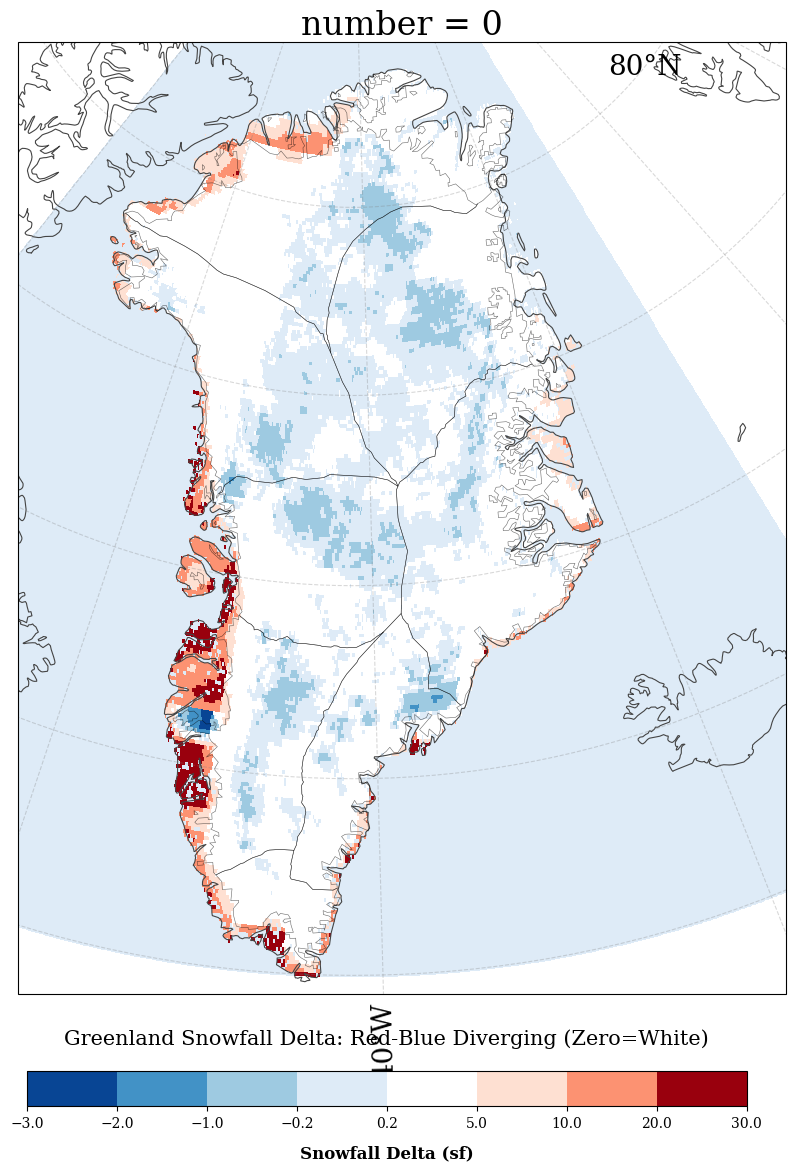

In [32]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import cartopy.crs as ccrs
import geopandas as gpd
import os

# 1. 配置路径
nc_path = r"C:\Users\11823\ERA5_Land_Daily\clipped\Delta_MaxNoSnow_Era2_minus_Era1.nc"
shp_dir = r"C:\greenland\Greenland_shp\流域冰盖"

# 2. 读取数据
ds = xr.open_dataset(nc_path)
data = ds['sf'].isel(time=0) if 'time' in ds['sf'].dims else ds['sf']

# 3. 核心改进：自定义分段色带
# 确保 0 附近是一个独立的区间（白色）
boundaries = [-3.0, -2.0, -1.0, -0.2, 0.2, 5, 10, 20, 30]

# 手动指定颜色：4个蓝色系，1个白色（中间），4个红色系
# 颜色选择符合学术期刊习惯，由浅入深
custom_colors = [
    '#084594', '#4292c6', '#9ecae1', '#deebf7', # 负值：深蓝到浅蓝
    '#ffffff',                                 # 0值：纯白
    '#fee0d2', '#fc9272', '#ef3b2c', '#99000d'  # 正值：浅红到深红
]
cmap = colors.ListedColormap(custom_colors)
norm = colors.BoundaryNorm(boundaries, cmap.N)

# 4. 设置投影
projection = ccrs.NorthPolarStereo(central_longitude=-41.5)
fig = plt.figure(figsize=(12, 14))
ax = plt.axes(projection=projection)
ax.set_extent([-58, -20, 59, 84], crs=ccrs.PlateCarree())

# 5. 绘图
im = data.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    add_colorbar=False,
    zorder=1
)

# 6. 叠加流域边界
if os.path.exists(shp_dir):
    for file in os.listdir(shp_dir):
        if file.endswith(".shp"):
            gdf = gpd.read_file(os.path.join(shp_dir, file))
            if gdf.crs is None: gdf.set_crs("EPSG:4326", inplace=True)
            gdf.to_crs(projection).plot(
                ax=ax, edgecolor='black', lw=0.4, facecolor='none', alpha=0.6, zorder=5
            )

# 7. 修饰与间距调整
ax.coastlines(resolution='50m', color='#444444', linewidth=0.8)
gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3, color='gray')
gl.top_labels = False
gl.right_labels = False

# 调整主图位置，为底部色标留出空间
plt.subplots_adjust(bottom=0.2)

# 8. 底部横向等距色条
# [left, bottom, width, height]
cbar_ax = fig.add_axes([0.2, 0.12, 0.6, 0.025]) 
cbar = fig.colorbar(
    im, 
    cax=cbar_ax, 
    orientation='horizontal', 
    spacing='uniform', # 关键：让不等距的 boundaries 在图上等宽显示
    extend='neither'
)

cbar.set_label('Snowfall Delta (sf)', fontsize=12, weight='bold', labelpad=10)
cbar.set_ticks(boundaries)
cbar.ax.tick_params(labelsize=10)

plt.title("Greenland Snowfall Delta: Red-Blue Diverging (Zero=White)", fontsize=15, pad=20)
plt.show()

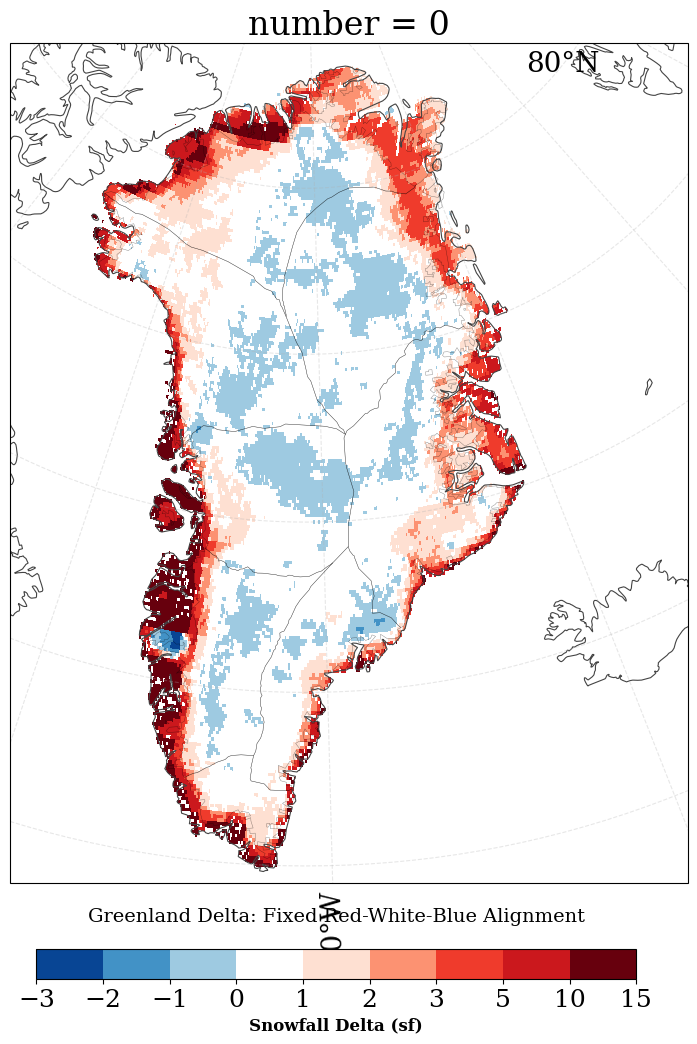

In [38]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import cartopy.crs as ccrs
import geopandas as gpd
import os

# 1. 配置路径
nc_path = r"C:\Users\11823\ERA5_Land_Daily\clipped\Delta_MaxNoSnow_Era2_minus_Era1.nc"
shp_dir = r"C:\greenland\Greenland_shp\流域冰盖"

# 2. 读取数据
ds = xr.open_dataset(nc_path)
data = ds['sf'].isel(time=0) if 'time' in ds['sf'].dims else ds['sf']

# 3. 严格对齐：10个边界点 = 9个区间 = 9个颜色
# 区间如下：
# 1: [-3.0, -2.0]  -> 深蓝
# 2: [-2.0, -1.0]  -> 中蓝
# 3: [-1.0, -0.2]  -> 浅蓝
# 4: [-0.2, 0.2]   -> 纯白 (这是你的 0 值中心)
# 5: [0.2, 5.0]    -> 浅红 (确保这里不再是白色)
# 6: [5.0, 10.0]   -> 中浅红
# 7: [10.0, 20.0]  -> 中红
# 8: [20.0, 30.0]  -> 大红
# 9: [30.0, 45.0]  -> 深红

boundaries = [-3.0, -2.0, -1.0, 0, 1,2,3, 5, 10, 15]

# 严格按顺序排列的 9 个颜色
custom_colors = [
    '#084594', '#4292c6', '#9ecae1',  # 负值区 (蓝色)
    '#ffffff',                        # 零值中心 (白色)
    '#fcbba1', '#fc9272', '#fb6a4a', '#de2d26', '#a50f15' # 正值区 (红色)
]

# 注意：如果颜色给多了或少了都会导致偏移。
# 我们只需要 9 个颜色。检查 custom_colors 长度：
custom_colors = [
    '#084594', '#4292c6', '#9ecae1', # 3个蓝色
    '#ffffff',                       # 1个白色
    '#fee0d2', '#fc9272', '#ef3b2c', '#cb181d', '#67000d' # 5个红色
]
# 此时长度正好为 3+1+5 = 9

cmap = colors.ListedColormap(custom_colors)
norm = colors.BoundaryNorm(boundaries, ncolors=len(custom_colors))

# 4. 设置投影
projection = ccrs.NorthPolarStereo(central_longitude=-41.5)
fig = plt.figure(figsize=(10, 12))
ax = plt.axes(projection=projection)
ax.set_extent([-58, -20, 59, 84], crs=ccrs.PlateCarree())

# 5. 绘图
im = data.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    add_colorbar=False,
    zorder=1
)

# 6. 叠加流域边界
if os.path.exists(shp_dir):
    for file in os.listdir(shp_dir):
        if file.endswith(".shp"):
            gdf = gpd.read_file(os.path.join(shp_dir, file))
            if gdf.crs is None: gdf.set_crs("EPSG:4326", inplace=True)
            gdf.to_crs(projection).plot(ax=ax, edgecolor='black', lw=0.3, facecolor='none', alpha=0.5, zorder=5)

# 7. 修饰
ax.coastlines(resolution='50m', color='#444444', linewidth=0.8)
gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)
gl.top_labels = False
gl.right_labels = False

# 8. 底部横向等距色带
plt.subplots_adjust(bottom=0.18)
cbar_ax = fig.add_axes([0.2, 0.1, 0.6, 0.025]) 
cbar = fig.colorbar(
    im, 
    cax=cbar_ax, 
    orientation='horizontal', 
    spacing='uniform', 
    extend='neither'
)

cbar.set_ticks(boundaries)
cbar.set_label('Snowfall Delta (sf)', fontsize=12, weight='bold')

plt.title("Greenland Delta: Fixed Red-White-Blue Alignment", fontsize=14, pad=20)
plt.show()

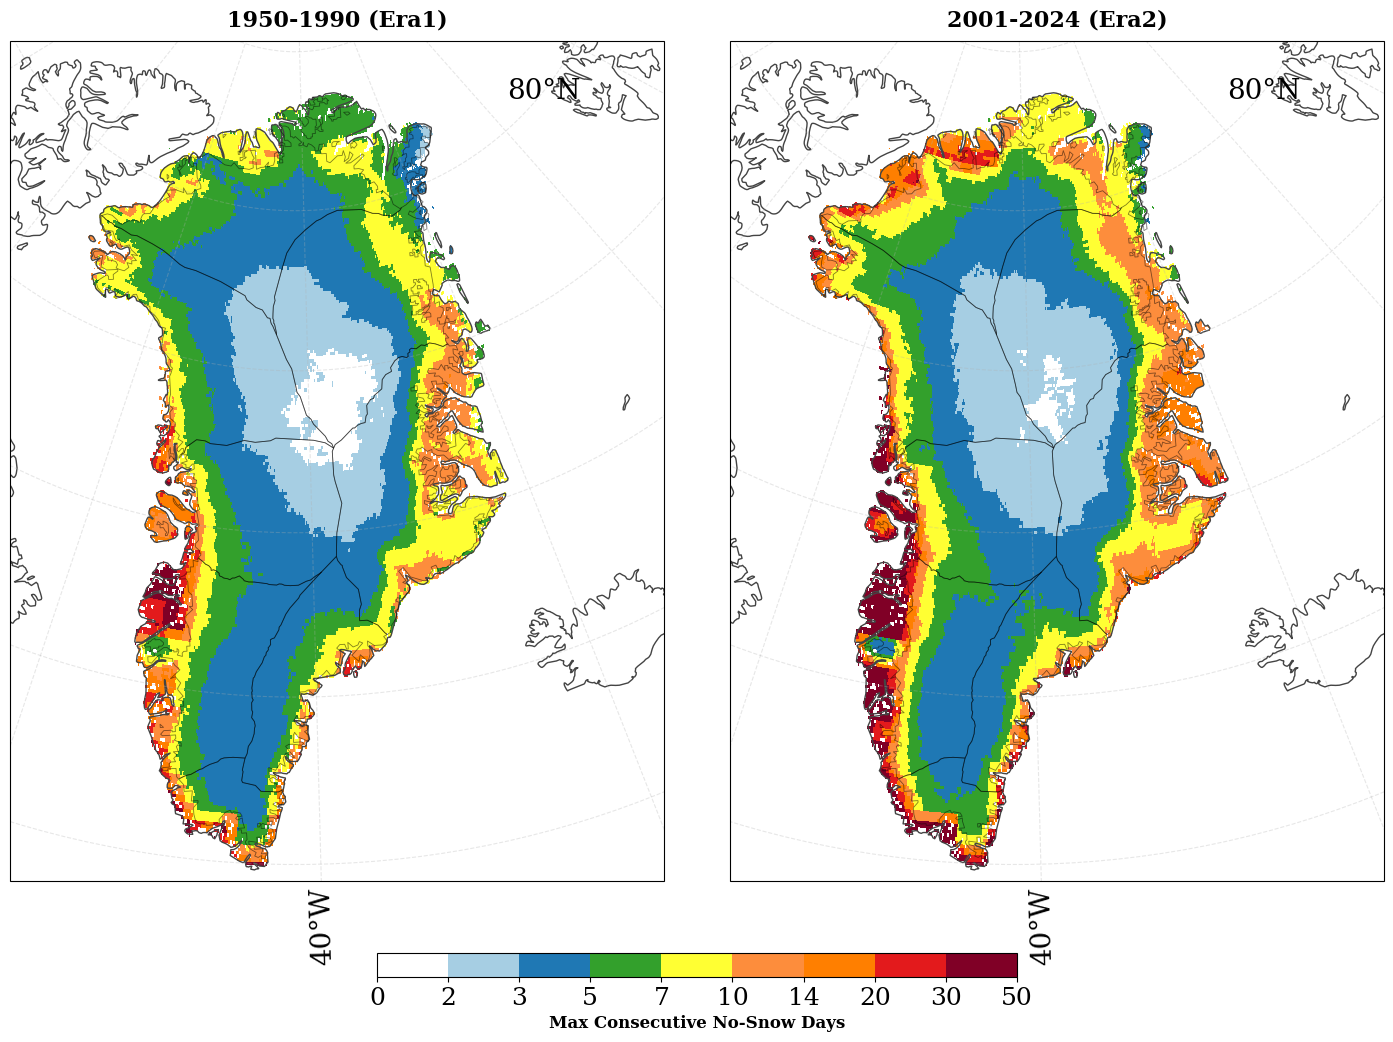

In [27]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cartopy.crs as ccrs
import geopandas as gpd
import os

# 1. 绘图配置
projection = ccrs.NorthPolarStereo(central_longitude=-41.5)
# 调整 figsize，去掉 wspace 后可以适当收窄宽度
fig, axes = plt.subplots(1, 2, figsize=(16, 12), subplot_kw={'projection': projection})
titles = ['1950-1990 (Era1)', '2001-2024 (Era2)']

# 2. 色板与等距设置
boundaries = [0, 2, 3, 5, 7, 10, 14, 20, 30, 50]
custom_map = ['#ffffff', '#a6cee3', '#1f78b4', '#33a02c', '#ffff33', '#fd8d3c', '#ff7f00', '#e31a1c', '#800026']
cmap = colors.ListedColormap(custom_map)
norm = colors.BoundaryNorm(boundaries, cmap.N)

for i, ax in enumerate(axes):
    ax.set_extent([-58, -20, 59, 85], crs=ccrs.PlateCarree())
    
    # 核心：确保纵横比一致，防止 wspace=0 时产生缝隙
    ax.set_aspect('auto') 
    
    im = data_list[i].plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        norm=norm,
        add_colorbar=False,
        zorder=1
    )
    
    # 叠加流域边界
    if os.path.exists(shp_dir):
        for file in os.listdir(shp_dir):
            if file.endswith(".shp"):
                gdf = gpd.read_file(os.path.join(shp_dir, file))
                gdf.to_crs(projection).plot(ax=ax, edgecolor='black', lw=0.6, facecolor='none', alpha=0.5, zorder=5)
    
    ax.coastlines(resolution='50m', color='#444444', linewidth=1)
    
    # 坐标网格
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)
    gl.top_labels = False
    gl.right_labels = False
    # 只有左图显示左侧刻度，右图隐藏
    if i == 1: 
        gl.left_labels = False
    
    ax.set_title(titles[i], fontsize=16, weight='bold', pad=10)

# 3. 彻底消除间距
# left, right 控制整体在画布中的水平占比
# wspace=0 消除子图间距
plt.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.2, wspace=0)

# 4. 底部横向等距色标
# 参数：[左起始, 底高度, 宽度, 高度]
cbar_ax = fig.add_axes([0.3, 0.12, 0.4, 0.02]) 
cbar = fig.colorbar(
    im, 
    cax=cbar_ax, 
    orientation='horizontal', 
    spacing='uniform' # 强制色块等宽
)
cbar.set_label('Max Consecutive No-Snow Days', fontsize=12, weight='bold')
cbar.set_ticks(boundaries)

plt.show()

In [1]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import pandas as pd

PATH = r"C:\Users\11823\Downloads\netradiation4variations.nc"

def _get_units(da):
    for k in ["units", "Units", "UNIT", "unit"]:
        if k in da.attrs:
            return da.attrs[k]
    return None

ds = xr.open_dataset(PATH)

print("\n========== BASIC ==========")
print("Path:", PATH)
print("Dims:", dict(ds.dims))
print("Coords:", list(ds.coords))
print("Data vars:", list(ds.data_vars))

# 你常遇到 valid_time：这里先自动兼容
if "valid_time" in ds.coords and "time" not in ds.coords:
    ds = ds.rename({"valid_time": "time"})
    print("\n[Info] Renamed coord: valid_time -> time")

# 统一经纬度命名（有些数据是 lat/lon）
rename_map = {}
if "lat" in ds.coords and "latitude" not in ds.coords:
    rename_map["lat"] = "latitude"
if "lon" in ds.coords and "longitude" not in ds.coords:
    rename_map["lon"] = "longitude"
if rename_map:
    ds = ds.rename(rename_map)
    print("[Info] Renamed coords:", rename_map)

print("\n========== VARS DETAIL ==========")
for v in ["ssr", "str", "sshf", "slhf"]:
    if v in ds.data_vars:
        da = ds[v]
        print(f"\n--- {v} ---")
        print("dims:", da.dims)
        print("shape:", da.shape)
        print("dtype:", da.dtype)
        print("units:", _get_units(da))
        # 打印少量关键attrs（避免太长）
        keys = [k for k in da.attrs.keys() if k.lower() in ["long_name","standard_name","description","units"]]
        if keys:
            print("attrs:", {k: da.attrs[k] for k in keys})
    else:
        print(f"\n[Warn] variable '{v}' not found in this file.")

print("\n========== TIME CHECK ==========")
if "time" in ds.coords:
    t = pd.to_datetime(ds["time"].values)
    print("time length:", len(t))
    print("time start:", t[0], " end:", t[-1])

    if len(t) >= 3:
        dt = np.diff(t.values).astype("timedelta64[s]").astype(np.int64)
        print("unique Δt (seconds):", np.unique(dt))
        # 常见时间步长提示
        common = int(pd.Series(dt).mode().iloc[0])
        print("most common Δt:", common, "sec  (≈", common/3600, "hours )")
    else:
        print("[Warn] Too few time points to infer time step.")
else:
    print("[Warn] No 'time' coord found.")

print("\n========== GRID CHECK ==========")
for c in ["latitude", "longitude"]:
    if c in ds.coords:
        arr = ds[c].values
        print(f"{c}: size={arr.size}, min={np.nanmin(arr):.3f}, max={np.nanmax(arr):.3f}, descending={arr[0]>arr[-1]}")
    else:
        print(f"[Warn] No coord '{c}' found.")

ds.close()
print("\nDone.")



========== BASIC ==========
Path: C:\Users\11823\Downloads\netradiation4variations.nc
Dims: {'valid_time': 456, 'latitude': 311, 'longitude': 701}
Coords: ['number', 'valid_time', 'latitude', 'longitude', 'expver']
Data vars: ['slhf', 'ssr', 'str', 'sshf']

[Info] Renamed coord: valid_time -> time

========== VARS DETAIL ==========

--- ssr ---
dims: ('time', 'latitude', 'longitude')
shape: (456, 311, 701)
dtype: float32
units: J m**-2
attrs: {'long_name': 'Surface net short-wave (solar) radiation', 'units': 'J m**-2', 'standard_name': 'surface_net_downward_shortwave_flux'}

--- str ---
dims: ('time', 'latitude', 'longitude')
shape: (456, 311, 701)
dtype: float32
units: J m**-2
attrs: {'long_name': 'Surface net long-wave (thermal) radiation', 'units': 'J m**-2', 'standard_name': 'surface_net_upward_longwave_flux'}

--- sshf ---
dims: ('time', 'latitude', 'longitude')
shape: (456, 311, 701)
dtype: float32
units: J m**-2
attrs: {'long_name': 'Time-integrated surface sensible heat net fl

C:\Users\11823\AppData\Local\Temp\ipykernel_13664\1069791820.py:18: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("Dims:", dict(ds.dims))


In [2]:
# -*- coding: utf-8 -*-
import xarray as xr
import geopandas as gpd
import rioxarray  # noqa: F401  (只要import，xarray对象就会多出.rio接口)
import pandas as pd
import numpy as np

IN_NC  = r"C:\Users\11823\Downloads\netradiation4variations.nc"
SHAPE  = r"C:\greenland\Greenland_shp\Gboundry.shp"
OUT_NC = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\netradiation4variations_G.nc"

# 1) 读数据
ds = xr.open_dataset(IN_NC)

# 2) 统一时间维
if "valid_time" in ds.coords and "time" not in ds.coords:
    ds = ds.rename({"valid_time": "time"})

# 3) 计算每个月秒数（关键：别用time.diff）
t = pd.to_datetime(ds["time"].values)
days_in_month = pd.DatetimeIndex(t).days_in_month.astype(np.int32)
sec_in_month = xr.DataArray(
    days_in_month * 86400,
    dims=("time",),
    coords={"time": ds["time"]},
    name="seconds_in_month"
)

# 4) 计算两套方案（输出 W m-2）
Rn = (ds["ssr"] + ds["str"]) / sec_in_month
Rn.name = "Rn"
Rn.attrs.update({
    "long_name": "Surface net radiative flux (net shortwave + net longwave)",
    "units": "W m**-2",
    "note": "Computed from monthly accumulated energy (J m-2) divided by seconds_in_month"
})

SEB_star = (ds["ssr"] + ds["str"] + ds["sshf"] + ds["slhf"]) / sec_in_month
SEB_star.name = "SEB_star"
SEB_star.attrs.update({
    "long_name": "Surface energy balance (net SW + net LW + sensible + latent), no ground heat flux",
    "units": "W m**-2",
    "note": "Computed from monthly accumulated energy (J m-2) divided by seconds_in_month"
})

out = xr.Dataset({"Rn": Rn, "SEB_star": SEB_star})
out = out.assign_coords(latitude=ds["latitude"], longitude=ds["longitude"])

# 5) 裁剪：写入空间信息（经纬度是EPSG:4326）
out = out.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude", inplace=False)
out = out.rio.write_crs("EPSG:4326", inplace=False)

gdf = gpd.read_file(SHAPE).to_crs("EPSG:4326")
out_clip = out.rio.clip(gdf.geometry, gdf.crs, drop=True)

# 6) 保存
encoding = {v: {"zlib": True, "complevel": 4, "dtype": "float32"} for v in out_clip.data_vars}
out_clip.to_netcdf(OUT_NC, encoding=encoding)

print("Saved:", OUT_NC)
print(out_clip)


Saved: C:\Users\greenlandProject\ERA5LAND\ProcessFile\netradiation4variations_G.nc
<xarray.Dataset> Size: 1GB
Dimensions:      (time: 456, latitude: 239, longitude: 612)
Coordinates:
    number       int64 8B 0
  * time         (time) datetime64[ns] 4kB 1950-04-01 1950-05-01 ... 2025-09-01
    expver       (time) <U4 7kB '0001' '0001' '0001' ... '0001' '0001' '0001'
  * latitude     (latitude) float64 2kB 83.6 83.5 83.4 83.3 ... 60.0 59.9 59.8
  * longitude    (longitude) float64 5kB -72.7 -72.6 -72.5 ... -11.8 -11.7 -11.6
    spatial_ref  int64 8B 0
Data variables:
    Rn           (time, latitude, longitude) float64 534MB nan nan ... nan nan
    SEB_star     (time, latitude, longitude) float64 534MB nan nan ... nan nan


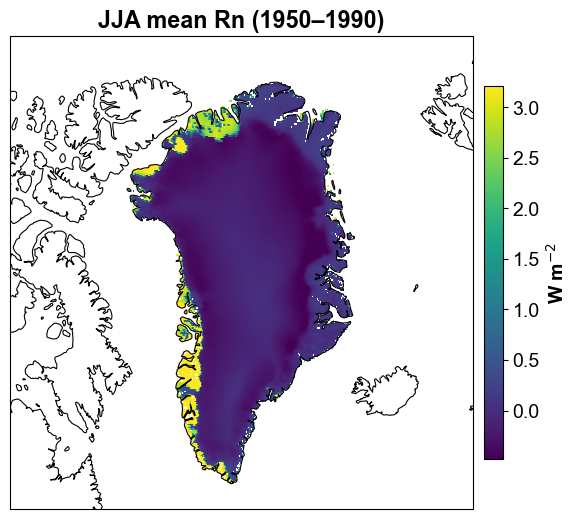

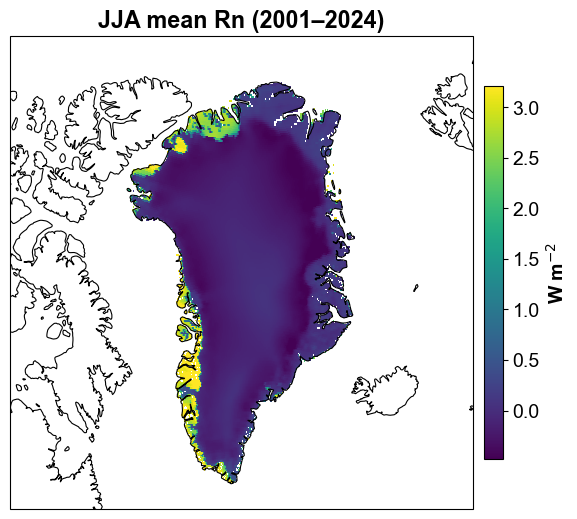

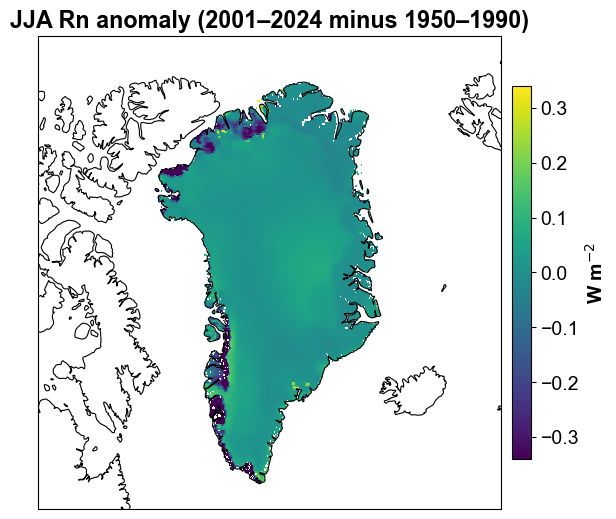

In [ ]:
# -*- coding: utf-8 -*-=================展开是3张图，两段净辐射均值===距平值======
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

NC = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\netradiation4variations_G.nc"

# ===== 1) 读数据 & 统一维度 =====
ds = xr.open_dataset(NC)

if "valid_time" in ds.coords and "time" not in ds.coords:
    ds = ds.rename({"valid_time": "time"})

# 有些文件是 lat/lon
rename_map = {}
if "lat" in ds.coords and "latitude" not in ds.coords: rename_map["lat"] = "latitude"
if "lon" in ds.coords and "longitude" not in ds.coords: rename_map["lon"] = "longitude"
if rename_map:
    ds = ds.rename(rename_map)

# ===== 2) 自动得到“净辐射 Rn（W/m2）” =====
def _units(da):
    return da.attrs.get("units", "")

def get_Rn_Wm2(ds):
    # 情况A：文件里已经有 Rn
    if "Rn" in ds.data_vars:
        da = ds["Rn"]
        u = _units(da)
        # 如果还是J m-2，转成W m-2
        if "J" in u:
            t = pd.to_datetime(ds["time"].values)
            sec = xr.DataArray(pd.DatetimeIndex(t).days_in_month.values * 86400,
                               dims=("time",), coords={"time": ds["time"]})
            da = da / sec
            da.attrs["units"] = "W m**-2"
        return da

    # 情况B：没有Rn，用 ssr+str 计算
    for v in ["ssr", "str"]:
        if v not in ds.data_vars:
            raise KeyError(f"Missing variable '{v}' in nc.")

    Rn = ds["ssr"] + ds["str"]
    u = _units(Rn) or _units(ds["ssr"])
    # ssr/str 通常是J m-2（月累计）
    if "J" in u:
        t = pd.to_datetime(ds["time"].values)
        sec = xr.DataArray(pd.DatetimeIndex(t).days_in_month.values * 86400,
                           dims=("time",), coords={"time": ds["time"]})
        Rn = Rn / sec
        Rn.attrs["units"] = "W m**-2"
    Rn.name = "Rn"
    Rn.attrs["long_name"] = "Surface net radiative flux (net shortwave + net longwave)"
    return Rn

Rn = get_Rn_Wm2(ds)

# ===== 3) 只取 6/7/8 月（JJA）并做两段均值 =====
jja = Rn.sel(time=Rn["time"].dt.month.isin([6, 7, 8]))

mean_5090  = jja.sel(time=slice("1950-01-01", "1990-12-31")).mean("time", skipna=True)
mean_0124  = jja.sel(time=slice("2001-01-01", "2024-12-31")).mean("time", skipna=True)
anom_0124m5090 = mean_0124 - mean_5090

# ===== 4) 画三张图 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 14,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

proj_map  = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
proj_data = ccrs.PlateCarree()
extent = [-75, -10, 58, 85]

def plot_map(da2d, title, vmin=None, vmax=None, center0=False):
    fig = plt.figure(figsize=(7.2, 6.2))
    ax = plt.axes(projection=proj_map)
    ax.set_extent(extent, crs=proj_data)
    ax.coastlines(linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4)

    # 用pcolormesh更稳
    lon = da2d["longitude"]
    lat = da2d["latitude"]
    # 若lat降序也没问题，pcolormesh照样画
    im = ax.pcolormesh(lon, lat, da2d, transform=proj_data,
                       shading="auto", vmin=vmin, vmax=vmax)
    cb = plt.colorbar(im, ax=ax, shrink=0.78, pad=0.02)
    cb.set_label("W m$^{-2}$")
    ax.set_title(title)
    plt.show()

# 统一色标范围：前两幅用同一范围；距平以0对称
finite = np.isfinite(np.r_[mean_5090.values.ravel(), mean_0124.values.ravel()])
vmin = np.nanpercentile(np.r_[mean_5090.values.ravel(), mean_0124.values.ravel()][finite], 2)
vmax = np.nanpercentile(np.r_[mean_5090.values.ravel(), mean_0124.values.ravel()][finite], 98)

a = anom_0124m5090.values
amax = np.nanpercentile(np.abs(a[np.isfinite(a)]), 98)

plot_map(mean_5090, "JJA mean Rn (1950–1990)", vmin=vmin, vmax=vmax)
plot_map(mean_0124, "JJA mean Rn (2001–2024)", vmin=vmin, vmax=vmax)
plot_map(anom_0124m5090, "JJA Rn anomaly (2001–2024 minus 1950–1990)", vmin=-amax, vmax=amax)


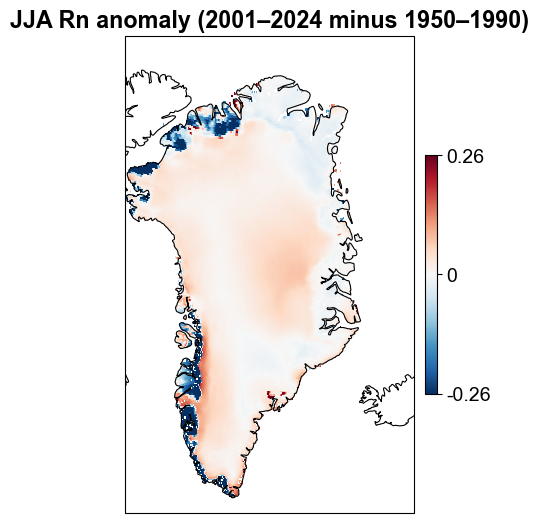

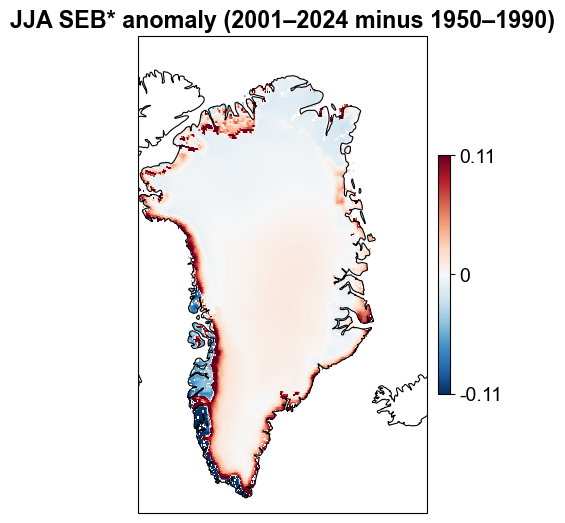

In [7]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm

NC = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\netradiation4variations_G.nc"
extent = [-58, -20, 58, 85]  # [lonW, lonE, latS, latN]

# ===== 1) 读数据 =====
ds = xr.open_dataset(NC)

if "valid_time" in ds.coords and "time" not in ds.coords:
    ds = ds.rename({"valid_time": "time"})

rename_map = {}
if "lat" in ds.coords and "latitude" not in ds.coords: rename_map["lat"] = "latitude"
if "lon" in ds.coords and "longitude" not in ds.coords: rename_map["lon"] = "longitude"
if rename_map:
    ds = ds.rename(rename_map)

Rn  = ds["Rn"]
SEB = ds["SEB_star"]

# ===== 2) JJA两段均值与距平 =====
def jja_mean(da, start, end):
    jja = da.sel(time=da["time"].dt.month.isin([6, 7, 8]))
    return jja.sel(time=slice(start, end)).mean("time", skipna=True)

Rn_anom  = jja_mean(Rn,  "2001-01-01", "2024-12-31") - jja_mean(Rn,  "1950-01-01", "1990-12-31")
SEB_anom = jja_mean(SEB, "2001-01-01", "2024-12-31") - jja_mean(SEB, "1950-01-01", "1990-12-31")

# ===== 3) 绘图样式 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 14,
    "axes.titleweight": "bold"
})

proj_map  = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
proj_data = ccrs.PlateCarree()

def robust_sym_limit(da2d, pct=97):
    """
    pct 越大越“淡”（范围更宽、颜色更浅）。
    这里用97%：减少极端值影响，同时让整体对比不过强。
    """
    v = da2d.values
    v = v[np.isfinite(v)]
    if v.size == 0:
        return 1.0
    lim = np.nanpercentile(np.abs(v), pct)
    if not np.isfinite(lim) or lim <= 0:
        lim = np.nanmax(np.abs(v))
    return float(lim) if lim > 0 else 1.0

def plot_anom(da2d, title, pct=97):
    lim = robust_sym_limit(da2d, pct=pct)
    norm = TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)

    fig = plt.figure(figsize=(7.2, 6.2))
    ax = plt.axes(projection=proj_map)
    ax.set_extent(extent, crs=proj_data)
    ax.coastlines(linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4)

    im = ax.pcolormesh(
        da2d["longitude"], da2d["latitude"], da2d,
        transform=proj_data,
        shading="auto",
        cmap="RdBu_r",   # 负蓝、0白、正红（但我们用更宽范围让它“更淡”）
        norm=norm
    )

    # 色标：只留 min / 0 / max 三个刻度
    cb = plt.colorbar(im, ax=ax, shrink=0.5, pad=0.02)
    cb.set_ticks([-lim, 0.0, lim])
    cb.set_ticklabels([f"{-lim:.2f}", "0", f"{lim:.2f}"])
    cb.set_label(da2d.attrs.get("units", ""))

    ax.set_title(title)
    plt.show()

plot_anom(Rn_anom,  "JJA Rn anomaly (2001–2024 minus 1950–1990)",  pct=97)
plot_anom(SEB_anom, "JJA SEB* anomaly (2001–2024 minus 1950–1990)", pct=97)


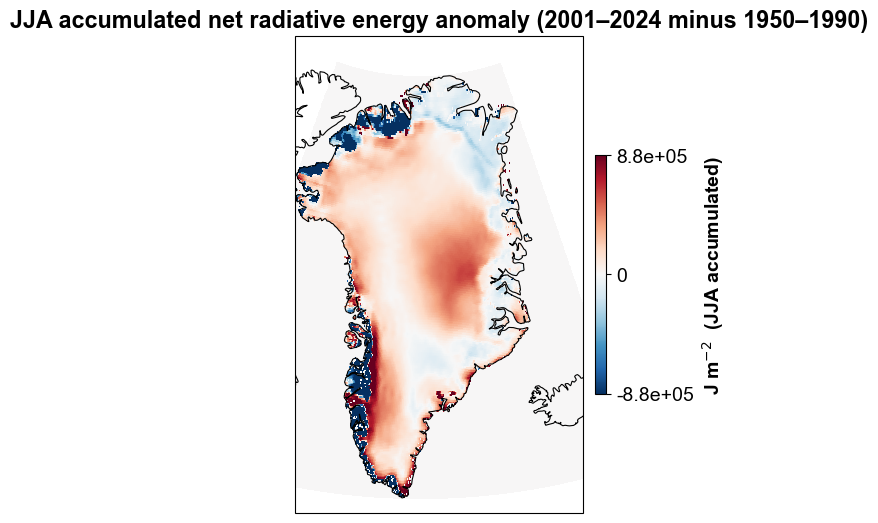

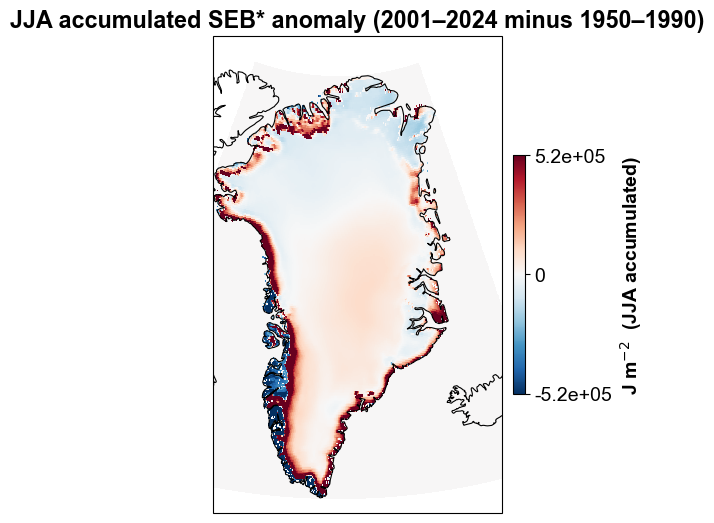

In [ ]:
# -*- coding: utf-8 -*-=============展开是上图的累计值============
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm

NC = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\netradiation4variations_G.nc"

extent = [-58, -20, 58, 85]

# ===== 1) 读取 =====
ds = xr.open_dataset(NC)

if "valid_time" in ds.coords and "time" not in ds.coords:
    ds = ds.rename({"valid_time":"time"})

rename_map={}
if "lat" in ds.coords and "latitude" not in ds.coords: rename_map["lat"]="latitude"
if "lon" in ds.coords and "longitude" not in ds.coords: rename_map["lon"]="longitude"
if rename_map:
    ds = ds.rename(rename_map)

# 这里你的G.nc已经只有Rn和SEB_star，
# 它们是 W m^-2，所以要反推出累计能量：
# E = Flux * seconds_in_month

time = ds["time"].to_index()
sec = xr.DataArray(
    time.days_in_month.values * 86400,
    dims=("time",),
    coords={"time":ds["time"]}
)

# ===== 2) 重新计算“夏季累计能量”(J m^-2) =====
Rn_E  = ds["Rn"]       * sec
SEB_E = ds["SEB_star"] * sec

Rn_E.name  = "Rn_energy"
SEB_E.name = "SEB_energy"

# ===== 3) 每年JJA累计 =====
def yearly_JJA_energy(da):
    jja = da.sel(time=da["time"].dt.month.isin([6,7,8]))
    return jja.groupby("time.year").sum("time", skipna=True)

Rn_year  = yearly_JJA_energy(Rn_E)
SEB_year = yearly_JJA_energy(SEB_E)

# ===== 4) 两个时期平均 =====
Rn_anom  = Rn_year.sel(year=slice(2001,2024)).mean("year") - \
           Rn_year.sel(year=slice(1950,1990)).mean("year")

SEB_anom = SEB_year.sel(year=slice(2001,2024)).mean("year") - \
           SEB_year.sel(year=slice(1950,1990)).mean("year")

# ===== 5) 画图 =====
plt.rcParams.update({"font.family":"Arial","font.size":14})

proj_map  = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
proj_data = ccrs.PlateCarree()

def sym_limit(da,pct=97):
    v=da.values[np.isfinite(da.values)]
    return np.nanpercentile(np.abs(v),pct)

def plot_map(da,title):
    lim=sym_limit(da,97)
    norm=TwoSlopeNorm(vmin=-lim,vcenter=0,vmax=lim)

    fig=plt.figure(figsize=(7.2,6.2))
    ax=plt.axes(projection=proj_map)
    ax.set_extent(extent,crs=proj_data)
    ax.coastlines(linewidth=0.8)
    ax.add_feature(cfeature.BORDERS,linewidth=0.4)

    im=ax.pcolormesh(
        da["longitude"],da["latitude"],da,
        transform=proj_data,
        shading="auto",
        cmap="RdBu_r",
        norm=norm
    )

    cb=plt.colorbar(im,ax=ax,shrink=0.5,pad=0.02)
    cb.set_ticks([-lim,0,lim])
    cb.set_ticklabels([f"{-lim:.1e}","0",f"{lim:.1e}"])
    cb.set_label("J m$^{-2}$  (JJA accumulated)")

    ax.set_title(title)
    plt.show()

plot_map(Rn_anom,  "JJA accumulated net radiative energy anomaly (2001–2024 minus 1950–1990)")
plot_map(SEB_anom, "JJA accumulated SEB* anomaly (2001–2024 minus 1950–1990)")
